# Chapter 1: LOS Calibration Baseline

Checks that the hardware is stable before any modelling:
- the 20 LOS calibration captures of each channel are overlaid and should look like one thick line
- the hardware first-path index FP_INDEX/64 should land at about the same place (~748) every time

--------------------------------------------------------------------------------
CHANNEL    | SAMPLES    | MEAN FP_INDEX/64   |    STD |     MIN |     MAX
--------------------------------------------------------------------------------
CH 1       | 20         | 748.02             |   2.34 |  744.42 |  751.78
CH 2       | 20         | 748.17             |   2.31 |  744.31 |  751.31


CH 3       | 20         | 747.83             |   2.45 |  743.92 |  751.28
CH 4       | 20         | 747.76             |   2.39 |  744.11 |  750.73
CH 5       | 20         | 747.69             |   2.76 |  744.08 |  752.00
CH 7       | 20         | 747.61             |   2.57 |  743.86 |  751.23
--------------------------------------------------------------------------------

  Overall across all channels:
    Mean FP_INDEX/64 = 747.85
    Std  FP_INDEX/64 = 2.42
    Range            = [743.86, 752.00]


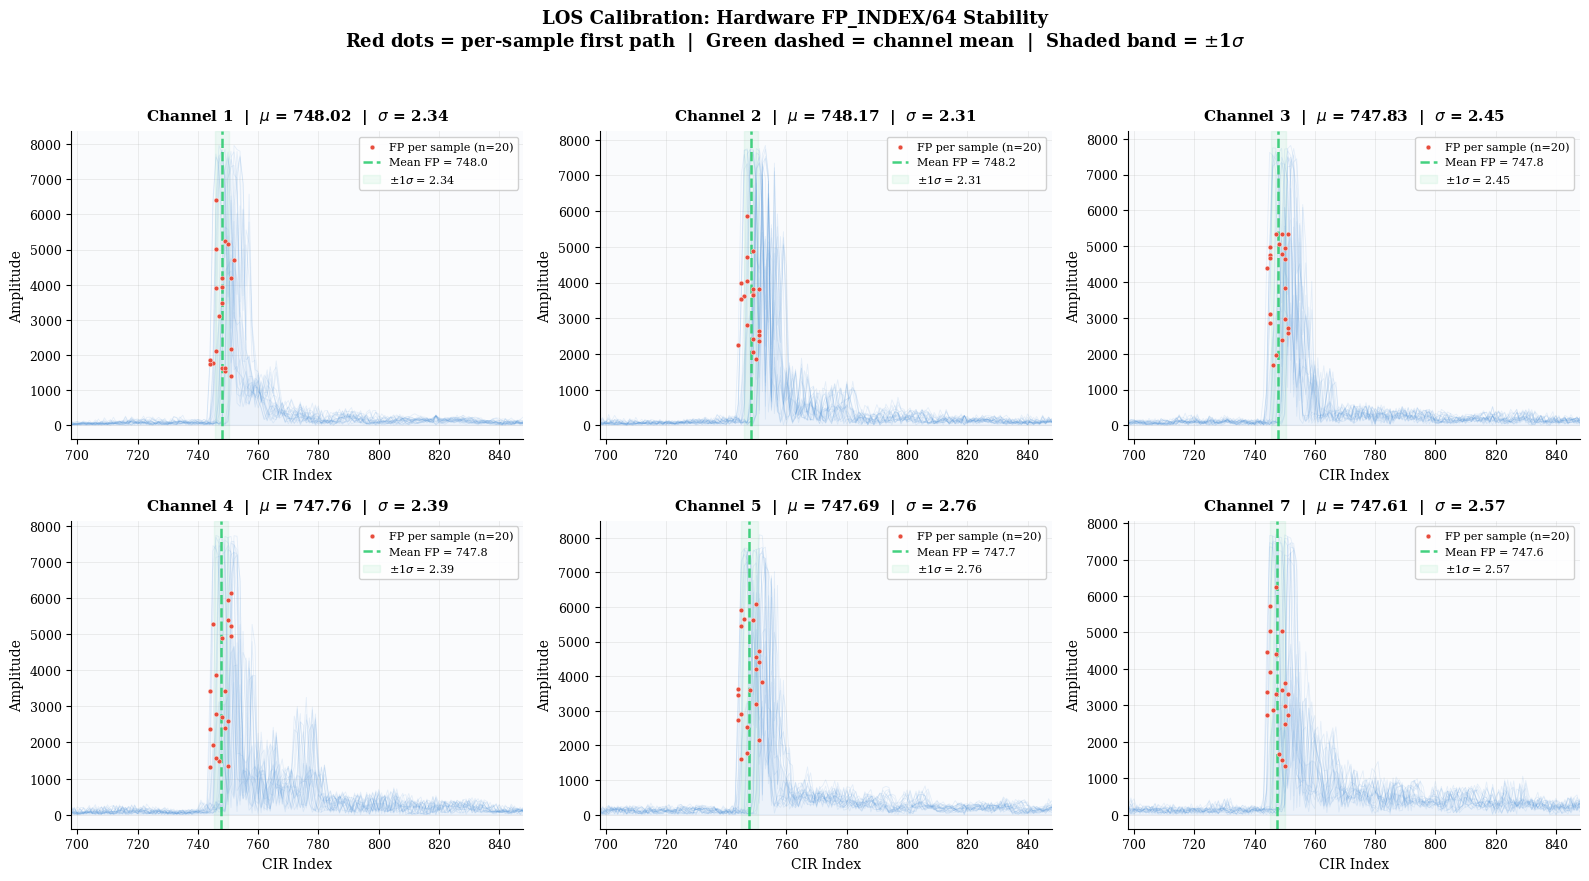

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Path configuration
CALIBRATION_DIR = os.path.join('dataset', 'calibrations')
CHANNEL_DIR     = os.path.join('dataset', 'channels')

if not os.path.exists(CALIBRATION_DIR):
    print(f"Folder not found: {CALIBRATION_DIR}")

# Analysis using the hardware FP_INDEX/64
CHANNELS = [1, 2, 3, 4, 5, 7]

print("-" * 80)
print(f"{'CHANNEL':<10} | {'SAMPLES':<10} | {'MEAN FP_INDEX/64':<18} | {'STD':>6} | {'MIN':>7} | {'MAX':>7}")
print("-" * 80)

# Plot styling
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 8,
})

TRACE_COLOR  = '#4A90D9'   # steel blue for CIR waveforms
FP_DOT_COLOR = '#E74C3C'   # red for per-sample FP dots
MEAN_COLOR   = '#2ECC71'   # green for channel-mean line
FILL_COLOR   = '#B0D4F1'   # light blue fill under mean CIR
BG_COLOR     = '#FAFBFD'   # very light grey-blue background

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

all_fp_vals = []

for i, ch in enumerate(CHANNELS):
    filename = f"2m_loscalibration_c{ch}.csv"
    filepath = os.path.join(CALIBRATION_DIR, filename)
    ax = axes[i]
    ax.set_facecolor(BG_COLOR)

    if not os.path.exists(filepath):
        print(f"CH {ch:<7} | FILE NOT FOUND: {filename}")
        ax.text(0.5, 0.5, f"File not found",
                ha='center', va='center', transform=ax.transAxes, fontsize=11)
        ax.set_title(f"Channel {ch}: No Data")
        continue

    df = pd.read_csv(filepath)
    cir_cols = sorted(
        [c for c in df.columns if c.startswith('CIR')],
        key=lambda x: int(x.replace('CIR', ''))
    )

    fp_indices = df['FP_INDEX'] / 64.0
    mean_fp    = fp_indices.mean()
    std_fp     = fp_indices.std()
    all_fp_vals.extend(fp_indices.tolist())

    print(f"CH {ch:<7} | {len(df):<10} | {mean_fp:<18.2f} | {std_fp:>6.2f} | "
          f"{fp_indices.min():>7.2f} | {fp_indices.max():>7.2f}")

    # Collect all CIR waveforms for computing mean envelope
    all_cirs = []
    fp_points_x, fp_points_y = [], []

    for _, row in df.iterrows():
        cir = row[cir_cols].values.astype(float)
        all_cirs.append(cir)
        fp  = float(row['FP_INDEX']) / 64.0
        fp_int = int(round(fp))

        ax.plot(cir, color=TRACE_COLOR, alpha=0.12, linewidth=0.6)

        if 0 <= fp_int < len(cir):
            fp_points_x.append(fp_int)
            fp_points_y.append(cir[fp_int])

    # Mean CIR with a light fill
    mean_cir = np.mean(all_cirs, axis=0)
    ax.fill_between(range(len(mean_cir)), mean_cir, alpha=0.08, color=TRACE_COLOR)

    # FP dots
    ax.scatter(fp_points_x, fp_points_y, color=FP_DOT_COLOR, s=12,
               zorder=5, edgecolors='white', linewidths=0.3,
               label=f'FP per sample (n={len(df)})')

    # Mean FP line
    mean_fp_int = int(round(mean_fp))
    ax.axvline(mean_fp, color=MEAN_COLOR, linestyle='--', linewidth=1.8,
               alpha=0.9, label=f'Mean FP = {mean_fp:.1f}')

    # +/-1 std band
    ax.axvspan(mean_fp - std_fp, mean_fp + std_fp,
               color=MEAN_COLOR, alpha=0.07, label=f'$\\pm$1$\\sigma$ = {std_fp:.2f}')

    ax.set_title(f"Channel {ch}  |  $\\mu$ = {mean_fp:.2f}  |  $\\sigma$ = {std_fp:.2f}",
                 fontweight='bold', pad=8)
    ax.set_xlim(max(0, mean_fp_int - 50), mean_fp_int + 100)
    ax.set_xlabel("CIR Index")
    ax.set_ylabel("Amplitude")
    ax.legend(loc='upper right', framealpha=0.9, edgecolor='#CCCCCC',
              fancybox=True, borderpad=0.4, handlelength=1.5)
    ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Hide unused subplots
for j in range(len(CHANNELS), 9):
    axes[j].set_visible(False)

print("-" * 80)
overall_mean = np.mean(all_fp_vals)
overall_std  = np.std(all_fp_vals)
print(f"\n  Overall across all channels:")
print(f"    Mean FP_INDEX/64 = {overall_mean:.2f}")
print(f"    Std  FP_INDEX/64 = {overall_std:.2f}")
print(f"    Range            = [{np.min(all_fp_vals):.2f}, {np.max(all_fp_vals):.2f}]")

fig.suptitle("LOS Calibration: Hardware FP_INDEX/64 Stability\n"
             "Red dots = per-sample first path  |  Green dashed = channel mean  |  "
             "Shaded band = $\\pm$1$\\sigma$",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('ch1_los_calibration.png', dpi=200, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()

# Reset rcParams so other cells aren't affected
plt.rcdefaults()

CIR peak index statistics (6000 samples -- training + unseen OOD):
  LOS  (3000) -- min: 719, max: 763, mean: 751.0, std: 3.5
  NLOS (3000) -- min: 732, max: 808, mean: 760.0, std: 15.2
  Overall peak range: [719, 808]

  Percentile-based ROI:
    P1  = 744,  P99 = 800,  buffer = 5
    search_start = round10(P1 - 5) = round10(739) = 740
    search_end   = ceil10(P99 + 5)  = ceil10(805)  = 810
  -> ROI = [740, 810]


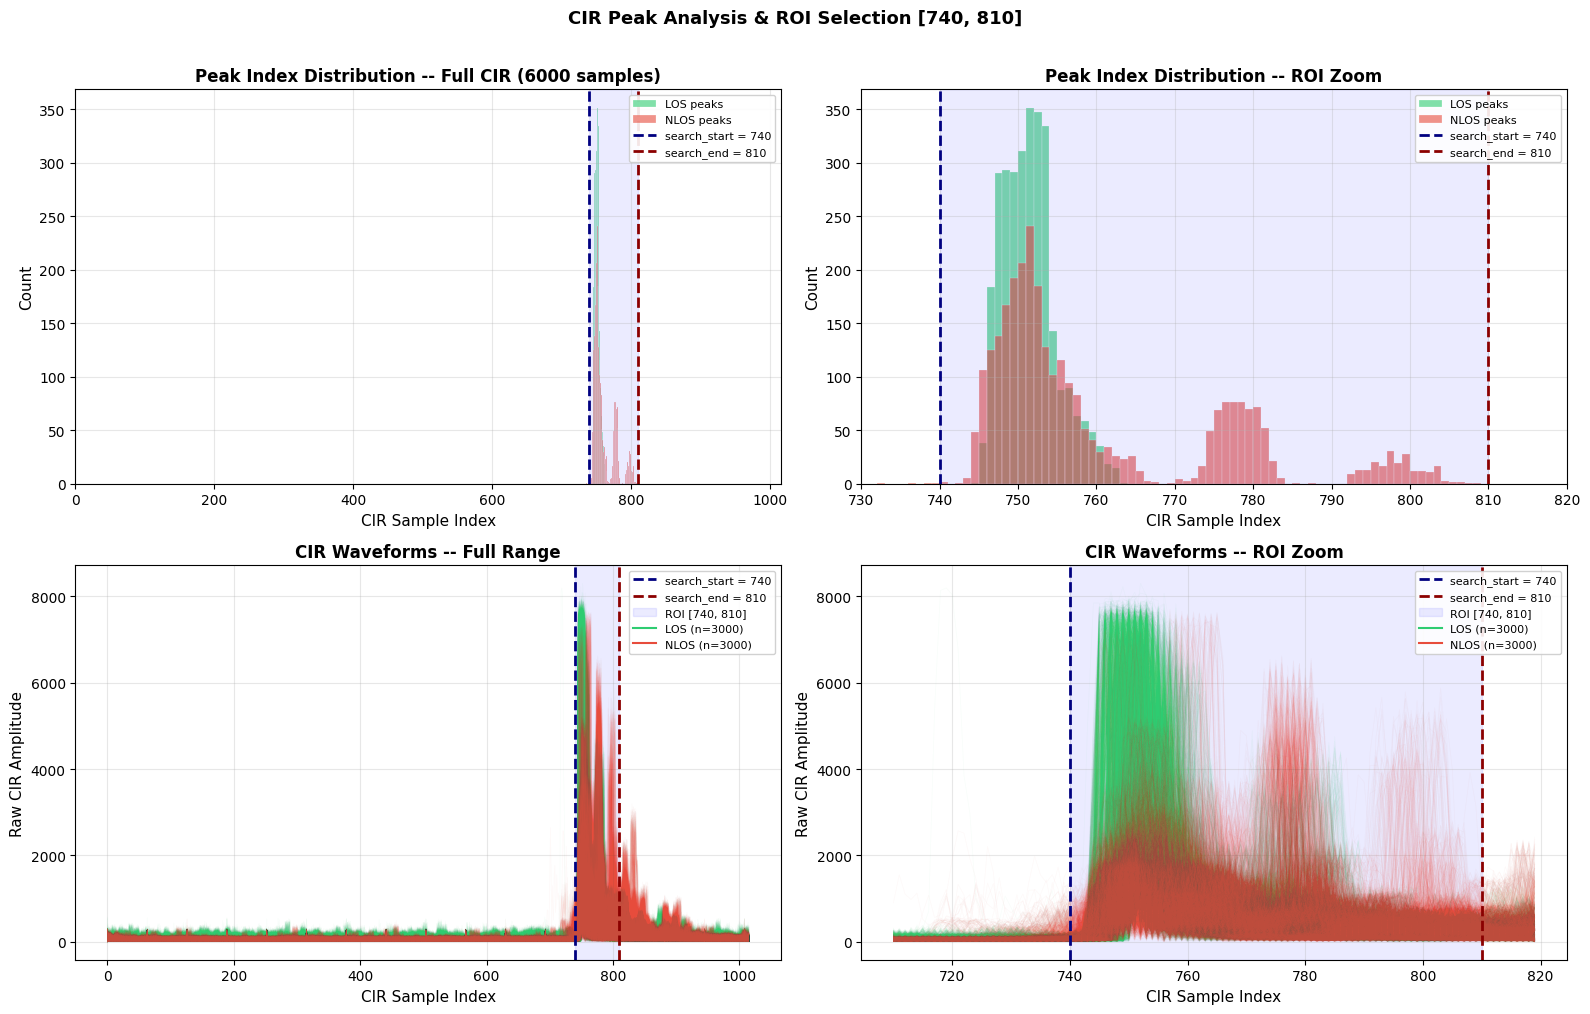

In [2]:
# Pick the ROI from the data
# Empirically find where all CIR peaks land, then define search window from percentiles.
# Uses all 6000 samples (3600 in-distribution + 2400 unseen)

import pandas as pd, numpy as np, matplotlib.pyplot as plt, os

DATA_DIR = os.path.join("dataset", "channels")

df_train  = pd.read_csv(os.path.join(DATA_DIR, "combined_uwb_dataset.csv"))
df_unseen = pd.read_csv(os.path.join(DATA_DIR, "unseen_dataset.csv"))
df_all = pd.concat([df_train, df_unseen], ignore_index=True)

cir_cols = sorted([c for c in df_all.columns if c.startswith('CIR')],
                  key=lambda x: int(x.replace('CIR', '')))

sigs = df_all[cir_cols].values.astype(float)
peak_indices = np.argmax(sigs, axis=1)
labels = df_all['Label'].values

los_peaks  = peak_indices[labels == 0]
nlos_peaks = peak_indices[labels == 1]

peak_min = int(peak_indices.min())
peak_max = int(peak_indices.max())

# Derive ROI from percentiles (robust to outliers)
p1  = int(np.floor(np.percentile(peak_indices, 1)))
p99 = int(np.ceil(np.percentile(peak_indices, 99)))
buffer = 5
search_start_raw = p1  - buffer
search_start = int(round(search_start_raw / 10) * 10)  # round to nearest 10
search_end_raw = p99 + buffer
search_end = int(np.ceil(search_end_raw / 10) * 10)    # round up to nearest 10

print(f"CIR peak index statistics ({len(peak_indices)} samples -- training + unseen OOD):")
print(f"  LOS  ({len(los_peaks)}) -- min: {los_peaks.min()}, max: {los_peaks.max()}, mean: {los_peaks.mean():.1f}, std: {los_peaks.std():.1f}")
print(f"  NLOS ({len(nlos_peaks)}) -- min: {nlos_peaks.min()}, max: {nlos_peaks.max()}, mean: {nlos_peaks.mean():.1f}, std: {nlos_peaks.std():.1f}")
print(f"  Overall peak range: [{peak_min}, {peak_max}]")
print(f"\n  Percentile-based ROI:")
print(f"    P1  = {p1},  P99 = {p99},  buffer = {buffer}")
print(f"    search_start = round10(P1 - {buffer}) = round10({search_start_raw}) = {search_start}")
print(f"    search_end   = ceil10(P99 + {buffer})  = ceil10({search_end_raw})  = {search_end}")
print(f"  -> ROI = [{search_start}, {search_end}]")

los_all  = np.where(labels == 0)[0]
nlos_all = np.where(labels == 1)[0]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

legend_kw = dict(fontsize=8, loc='upper right', framealpha=0.9, edgecolor='#CCCCCC')

# Row 1: Peak index histograms (full -> zoomed)
bins_full = np.arange(peak_min - 5, peak_max + 5, 1)
for ax, zoom in zip(axes[0], [False, True]):
    ax.hist(los_peaks,  bins=bins_full, alpha=0.6, color='#2ecc71', label='LOS peaks', edgecolor='white', lw=0.3)
    ax.hist(nlos_peaks, bins=bins_full, alpha=0.6, color='#e74c3c', label='NLOS peaks', edgecolor='white', lw=0.3)
    ax.axvline(search_start, color='navy', ls='--', lw=2, label=f'search_start = {search_start}')
    ax.axvline(search_end, color='darkred', ls='--', lw=2, label=f'search_end = {search_end}')
    ax.axvspan(search_start, search_end, alpha=0.08, color='blue')
    ax.set_xlabel("CIR Sample Index", fontsize=11)
    ax.set_ylabel("Count", fontsize=11)
    ax.legend(**legend_kw)
    ax.grid(True, alpha=0.3)
    if zoom:
        ax.set_xlim(search_start - 10, search_end + 10)
        ax.set_title("Peak Index Distribution -- ROI Zoom", fontsize=12, fontweight='bold')
    else:
        ax.set_xlim(0, len(cir_cols))
        ax.set_title(f"Peak Index Distribution -- Full CIR ({len(peak_indices)} samples)", fontsize=12, fontweight='bold')

# Row 2: CIR waveforms (full -> zoomed), all samples
x_full = np.arange(len(cir_cols))
plot_start = max(0, search_start - 30)
plot_end   = min(len(cir_cols), search_end + 10)
x_zoom = np.arange(plot_start, plot_end)

for ax, zoom in zip(axes[1], [False, True]):
    xr = x_zoom if zoom else x_full
    sl = slice(plot_start, plot_end) if zoom else slice(None)
    for i in los_all:
        ax.plot(xr, sigs[i, sl], color='#2ecc71', alpha=0.03, lw=0.5)
    for i in nlos_all:
        ax.plot(xr, sigs[i, sl], color='#e74c3c', alpha=0.03, lw=0.5)
    ax.axvline(search_start, color='navy', ls='--', lw=2, label=f'search_start = {search_start}')
    ax.axvline(search_end, color='darkred', ls='--', lw=2, label=f'search_end = {search_end}')
    ax.axvspan(search_start, search_end, alpha=0.08, color='blue', label=f'ROI [{search_start}, {search_end}]')
    ax.plot([], [], color='#2ecc71', lw=1.5, label=f'LOS (n={len(los_all)})')
    ax.plot([], [], color='#e74c3c', lw=1.5, label=f'NLOS (n={len(nlos_all)})')
    ax.set_xlabel("CIR Sample Index", fontsize=11)
    ax.set_ylabel("Raw CIR Amplitude", fontsize=11)
    ax.legend(**legend_kw)
    ax.grid(True, alpha=0.3)
    if zoom:
        ax.set_title("CIR Waveforms -- ROI Zoom", fontsize=12, fontweight='bold')
    else:
        ax.set_title("CIR Waveforms -- Full Range", fontsize=12, fontweight='bold')

plt.suptitle(f"CIR Peak Analysis & ROI Selection [{search_start}, {search_end}]",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

del df_train, df_unseen, df_all, sigs

## Calibration Results

### 1. First-path alignment

Across the 20 calibration captures of every channel, the hardware `FP_INDEX/64` lands at about 748 with a standard deviation of 2.4 samples.

| Channel | Mean FP_INDEX/64 | Std |
|---------|-----------------|-----|
| CH 1 | 748.02 | 2.34 |
| CH 2 | 748.17 | 2.31 |
| CH 3 | 747.83 | 2.45 |
| CH 4 | 747.76 | 2.39 |
| CH 5 | 747.69 | 2.76 |
| CH 7 | 747.61 | 2.57 |
| Overall | 747.85 | 2.42 |

`FP_INDEX` is a 16-bit DW1000 register: the upper 10 bits are the integer CIR index and the lower 6 bits a fraction, so `FP_INDEX / 64` is the first-path position as a CIR index. The DW1000 shifts its accumulator window so that the detected first path lands near the same index whatever the distance; over the ten scenarios the mean `FP_INDEX/64` stays between 742 and 748 (section 2.3). The models therefore search for the leading edge in CIR indices 740 to 810 and crop 60 samples around it.

### 2. Why antenna delay calibration matters

The antenna delay (`ANT_DLY`) does not change the CIR, which is the model input. It changes the reported `Distance`, and the labels are built from it: Stage 3 predicts `bounce_path_idx = fp_idx + (d_bounce - Distance) / 0.3003`, so a constant bias in `Distance` would shift every label.

Antenna delay calibration: residual error at 2.0 m
Ch    |   TX_ANT_DLY |   RX_ANT_DLY |  Mean Dist (m) |  Std Dist |  Mean Error (m) |  Std Error
-----------------------------------------------------------------------------------------------
C1    |        16400 |        16556 |         2.0328 |    0.0484 |         +0.0328 |     0.0484
C2    |        16375 |        16531 |         2.0300 |    0.0248 |         +0.0300 |     0.0248
C3    |        16367 |        16523 |         2.0140 |    0.0230 |         +0.0140 |     0.0230
C4    |        16324 |        16480 |         2.0093 |    0.0243 |         +0.0093 |     0.0243
C5    |        16358 |        16514 |         2.0459 |    0.0254 |         +0.0459 |     0.0254
C7    |        16309 |        16465 |         1.9868 |    0.0258 |         -0.0132 |     0.0258


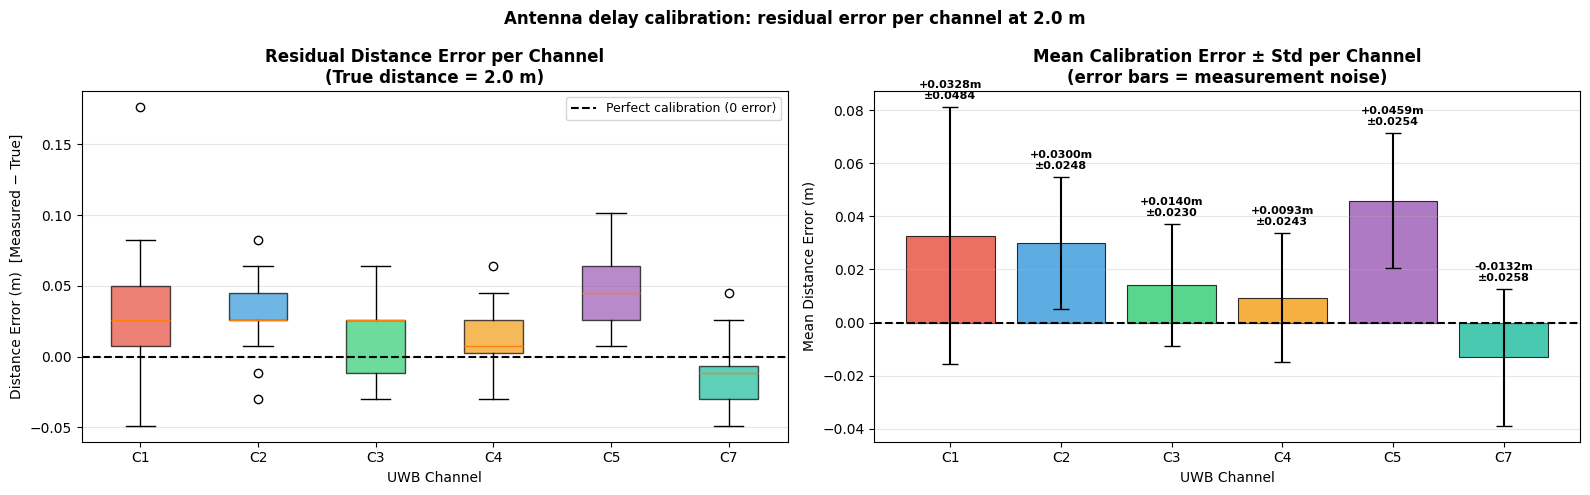

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Antenna delay calibration validation
# All calibration files were recorded at TRUE distance = 2.0m.
# After applying the per-channel ANT_DLY values below, the hardware
# should report Distance ~ 2.0m. Here we measure the residual error
# to show how well each channel is calibrated.
#
# ANT_DLY is a TWR timestamp correction: it shifts the reported
# Distance but does NOT affect the CIR waveform or FP_INDEX.

TRUE_DIST = 2.0  # metres (laser-measured ground truth)

# Per-channel antenna delay constants (from firmware header)
ANT_DLY = {
    1: {'TX': 16400, 'RX': 16556},
    2: {'TX': 16375, 'RX': 16531},
    3: {'TX': 16367, 'RX': 16523},
    4: {'TX': 16324, 'RX': 16480},
    5: {'TX': 16358, 'RX': 16514},
    7: {'TX': 16309, 'RX': 16465},
}

CHANNELS = [1, 2, 3, 4, 5, 7]
results  = []

for ch in CHANNELS:
    filepath = os.path.join(CALIBRATION_DIR, f'2m_loscalibration_c{ch}.csv')
    df = pd.read_csv(filepath)
    d   = df['Distance']
    err = d - TRUE_DIST
    results.append({
        'Channel':     f'C{ch}',
        'TX_ANT_DLY':  ANT_DLY[ch]['TX'],
        'RX_ANT_DLY':  ANT_DLY[ch]['RX'],
        'Mean_Dist':   d.mean(),
        'Std_Dist':    d.std(),
        'Mean_Error':  err.mean(),
        'Std_Error':   err.std(),
        'errors':      err.values,
    })

# Summary table
print(f"{'='*95}")
print(f"Antenna delay calibration: residual error at {TRUE_DIST} m")
print(f"{'='*95}")
print(f"{'Ch':<5} | {'TX_ANT_DLY':>12} | {'RX_ANT_DLY':>12} | "
      f"{'Mean Dist (m)':>14} | {'Std Dist':>9} | {'Mean Error (m)':>15} | {'Std Error':>10}")
print(f"{'-'*95}")

for r in results:
    print(f"{r['Channel']:<5} | {r['TX_ANT_DLY']:>12} | {r['RX_ANT_DLY']:>12} | "
          f"{r['Mean_Dist']:>14.4f} | {r['Std_Dist']:>9.4f} | "
          f"{r['Mean_Error']:>+15.4f} | {r['Std_Error']:>10.4f}")

print(f"{'='*95}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

colors = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6','#1abc9c']

# Box plot of the distance error per channel
ax = axes[0]
box_data = [r['errors'] for r in results]
labels   = [r['Channel'] for r in results]
bp = ax.boxplot(box_data, patch_artist=True, tick_labels=labels)
for patch, col in zip(bp['boxes'], colors):
    patch.set_facecolor(col)
    patch.set_alpha(0.7)
ax.axhline(0, color='black', ls='--', lw=1.5, label='Perfect calibration (0 error)')
ax.set_ylabel("Distance Error (m)  [Measured − True]")
ax.set_xlabel("UWB Channel")
ax.set_title("Residual Distance Error per Channel\n(True distance = 2.0 m)", fontweight='bold')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# Bar chart: Mean Error with Std as error bars
ax = axes[1]
mean_errs = [r['Mean_Error'] for r in results]
std_errs  = [r['Std_Error']  for r in results]
x = np.arange(len(CHANNELS))
bars = ax.bar(x, mean_errs, yerr=std_errs, capsize=6,
              color=colors, alpha=0.8, edgecolor='black', linewidth=0.8)
ax.axhline(0, color='black', ls='--', lw=1.5)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Mean Distance Error (m)")
ax.set_xlabel("UWB Channel")
ax.set_title("Mean Calibration Error ± Std per Channel\n(error bars = measurement noise)",
             fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Annotate bars with mean +/- std text
for xi, (me, se) in enumerate(zip(mean_errs, std_errs)):
    ax.text(xi, me + se + 0.003, f"{me:+.4f}m\n±{se:.4f}", ha='center',
            fontsize=8, fontweight='bold')

plt.suptitle("Antenna delay calibration: residual error per channel at 2.0 m",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## Antenna Delay Calibration: Results

Every calibration file was recorded at a laser-measured distance of 2.0 m, with the per-channel `ANT_DLY` constants applied.

| Ch | TX_ANT_DLY | RX_ANT_DLY | Mean Dist (m) | Mean Error (m) | Std Error (m) |
|----|-----------|-----------|--------------|---------------|--------------|
| C1 | 16400 | 16556 | 2.0328 | +0.0328 | 0.0484 |
| C2 | 16375 | 16531 | 2.0300 | +0.0300 | 0.0248 |
| C3 | 16367 | 16523 | 2.0140 | +0.0140 | 0.0230 |
| C4 | 16324 | 16480 | 2.0093 | +0.0093 | 0.0243 |
| C5 | 16358 | 16514 | 2.0459 | +0.0459 | 0.0254 |
| C7 | 16309 | 16465 | 1.9868 | -0.0132 | 0.0258 |

All channels are within 5 cm of the true distance, inside the 10 cm ranging accuracy of the DW1000. C4 is the closest (+0.9 cm) and C5 the furthest (+4.6 cm). C7 is the only channel that under-reports, so its `ANT_DLY` values are slightly too high. C1 has the largest spread (std 4.8 cm), which the antenna delay cannot reduce because it only shifts the mean. The largest residual, 4.6 cm, is about 0.15 of a CIR sample, small compared with the bounce offsets of 6 to 30 samples.

# Chapter 2: Multi-Channel Fingerprint

Every scenario was recorded on the six DW1000 channels, which differ in centre frequency and bandwidth. This chapter compares how the channels see the same scenario.

## 2.1 Multi-Channel Analysis

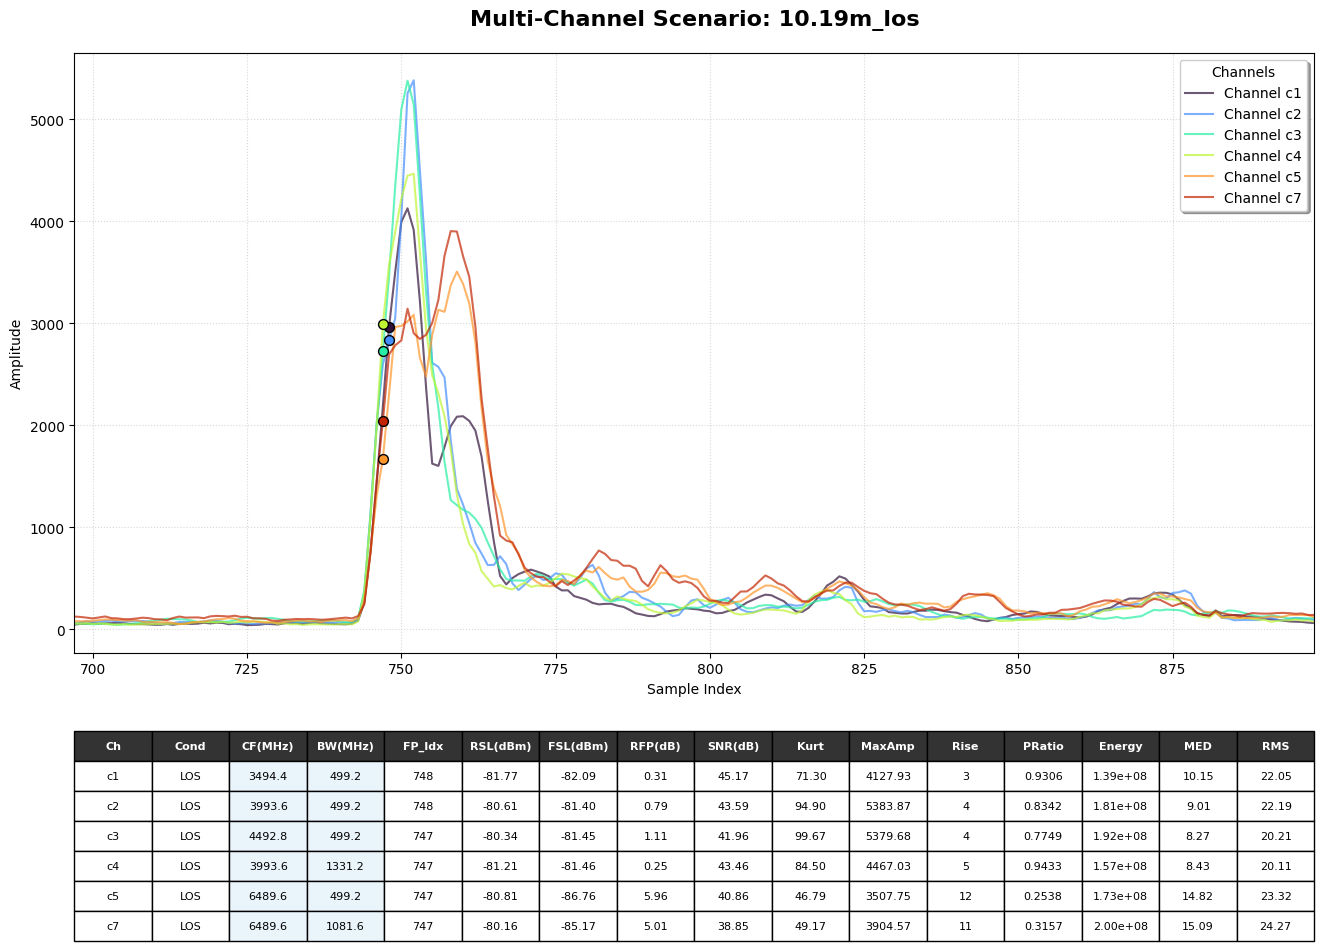

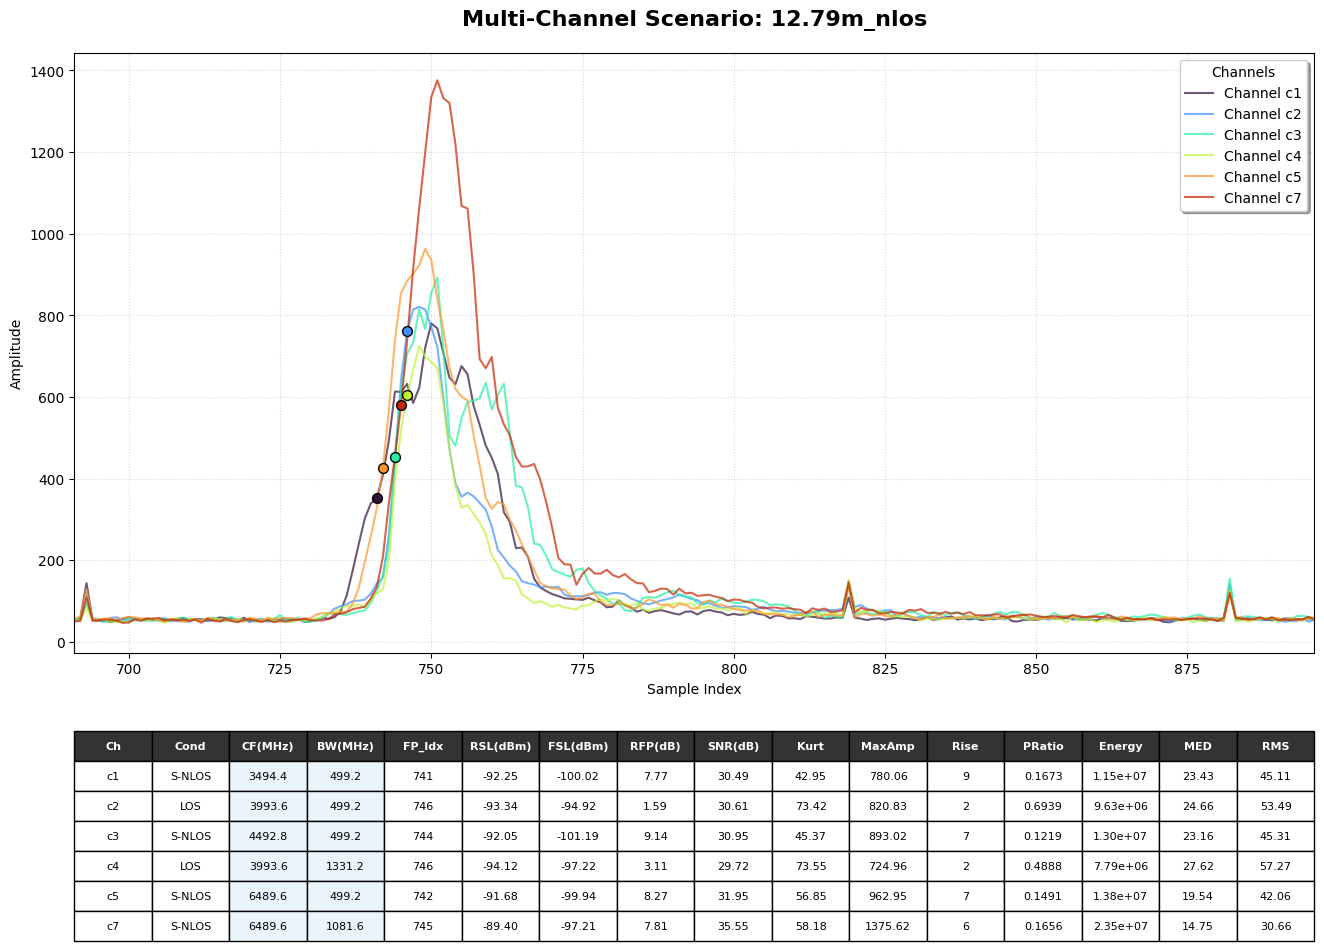

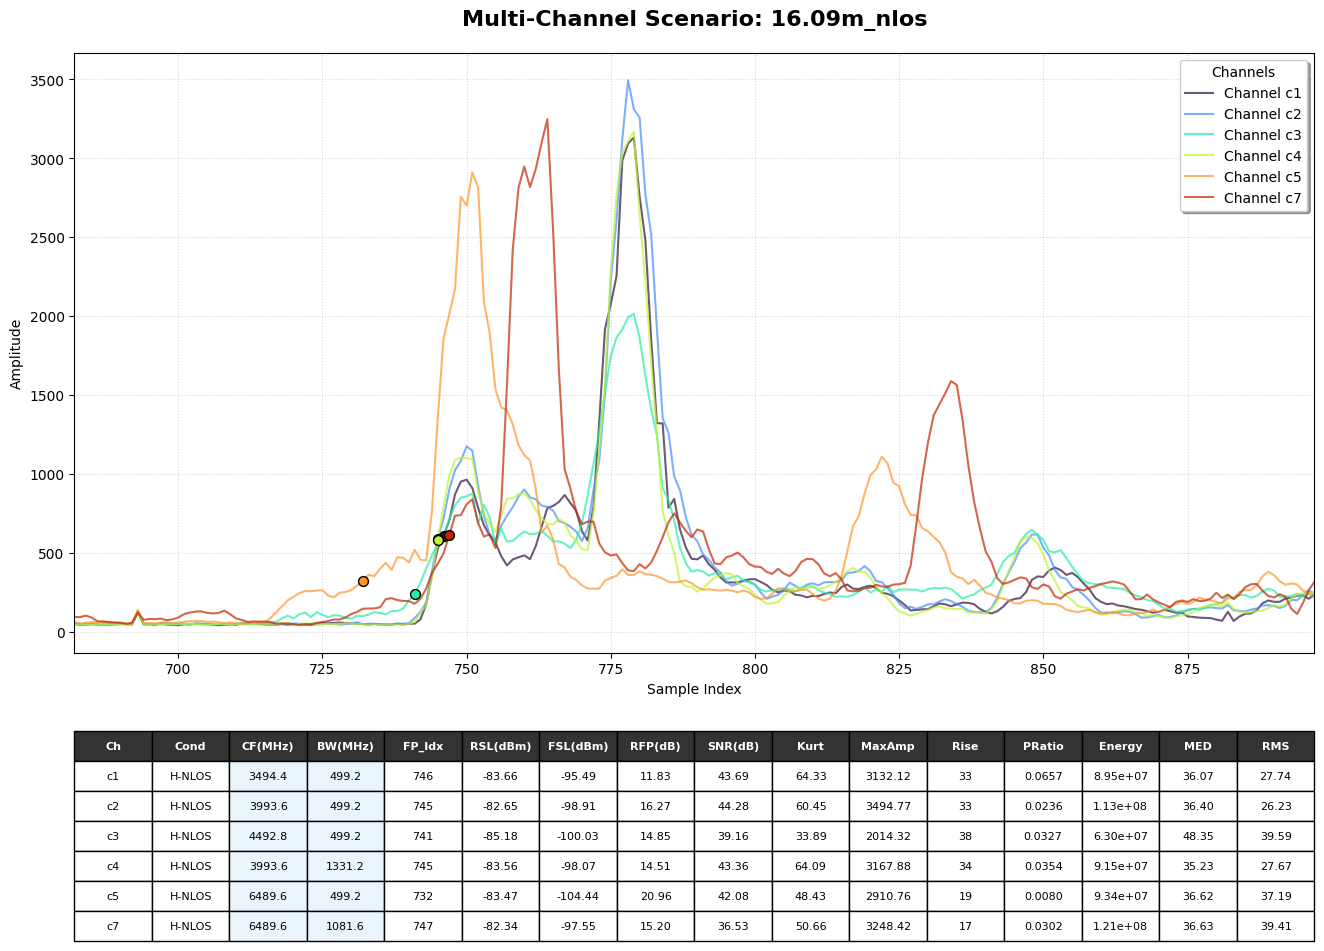

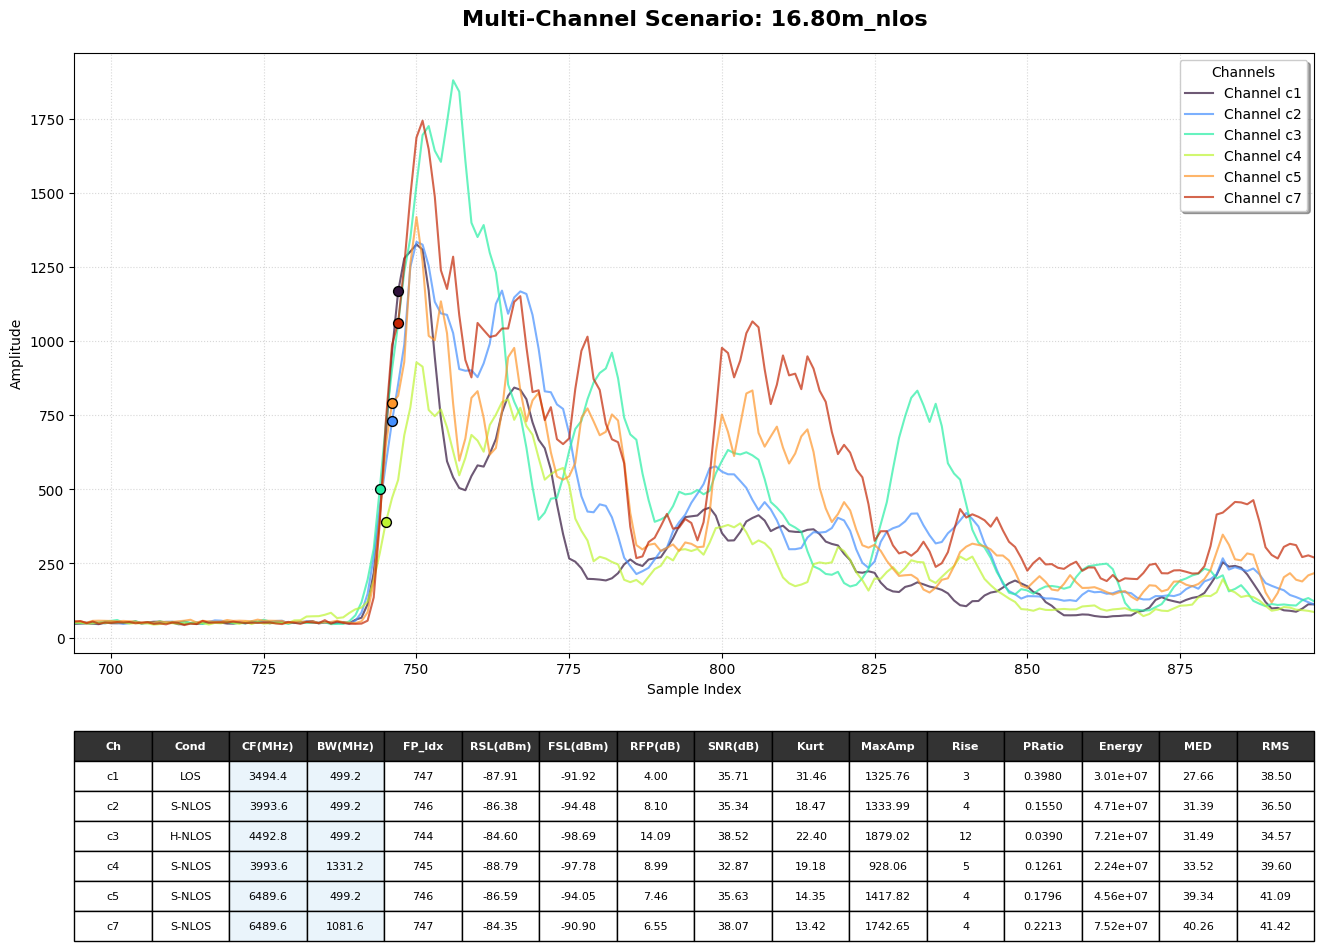

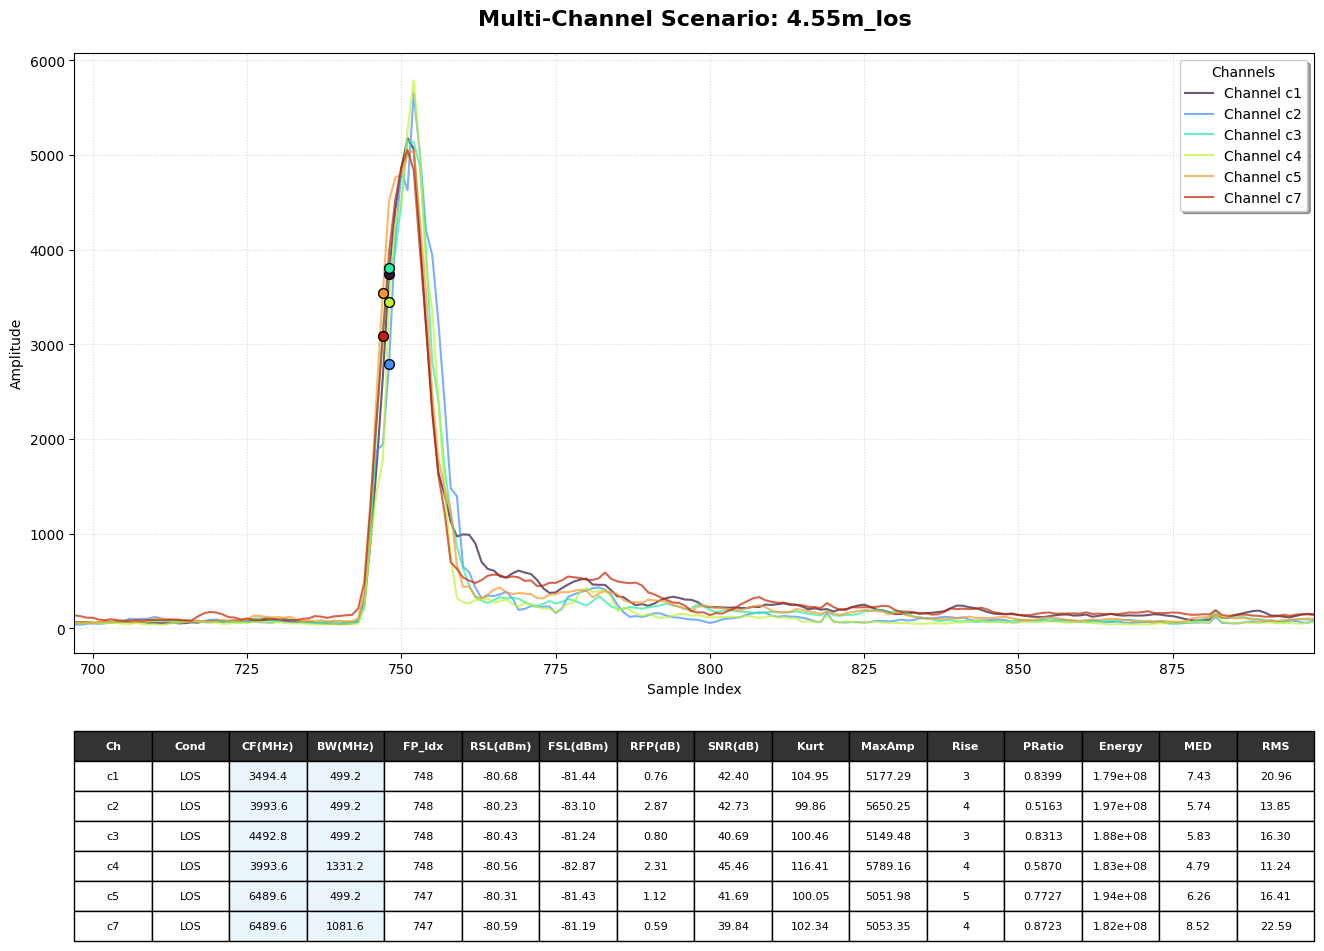

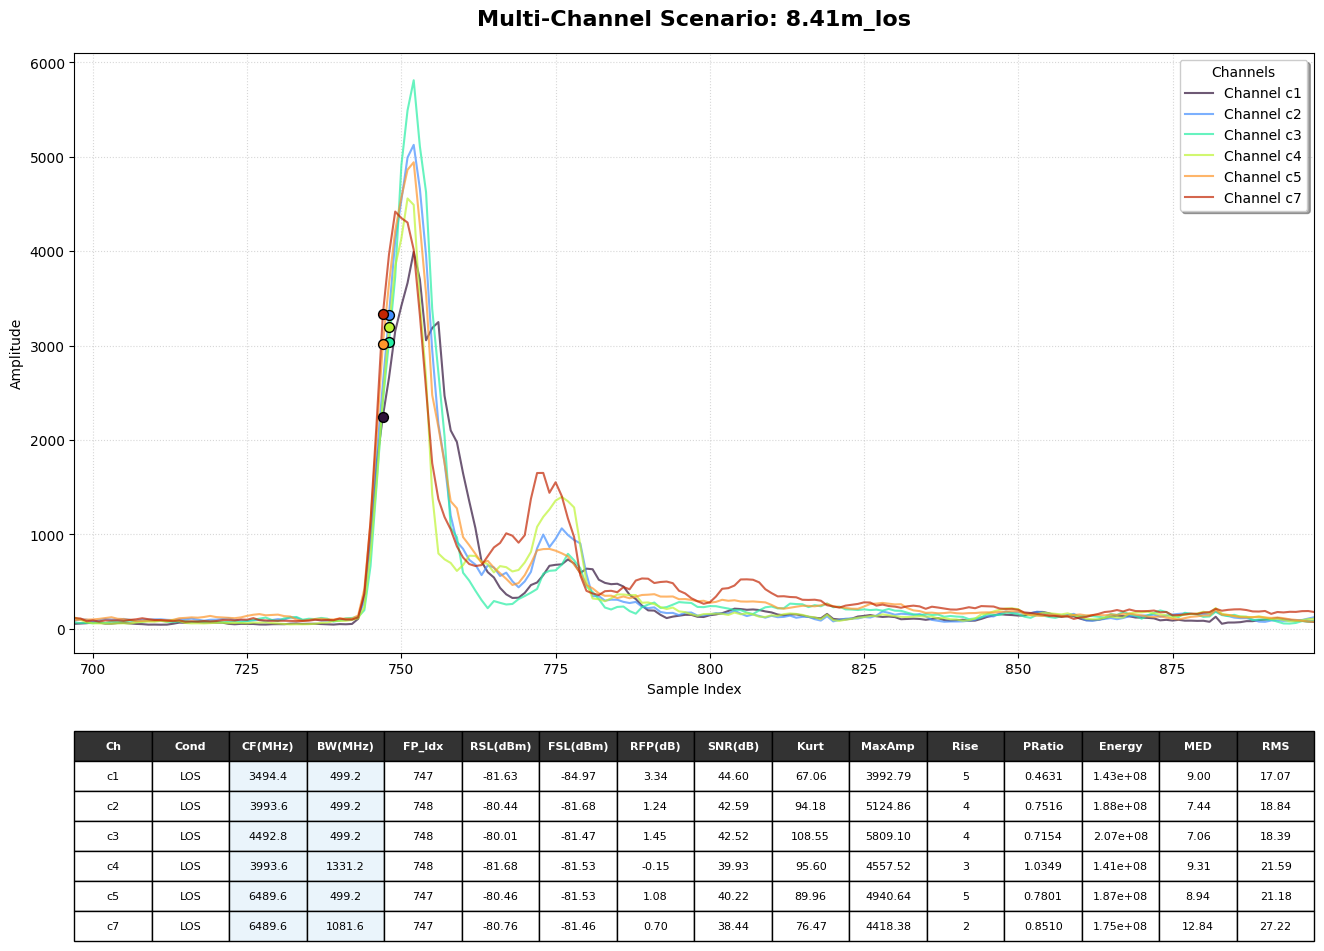

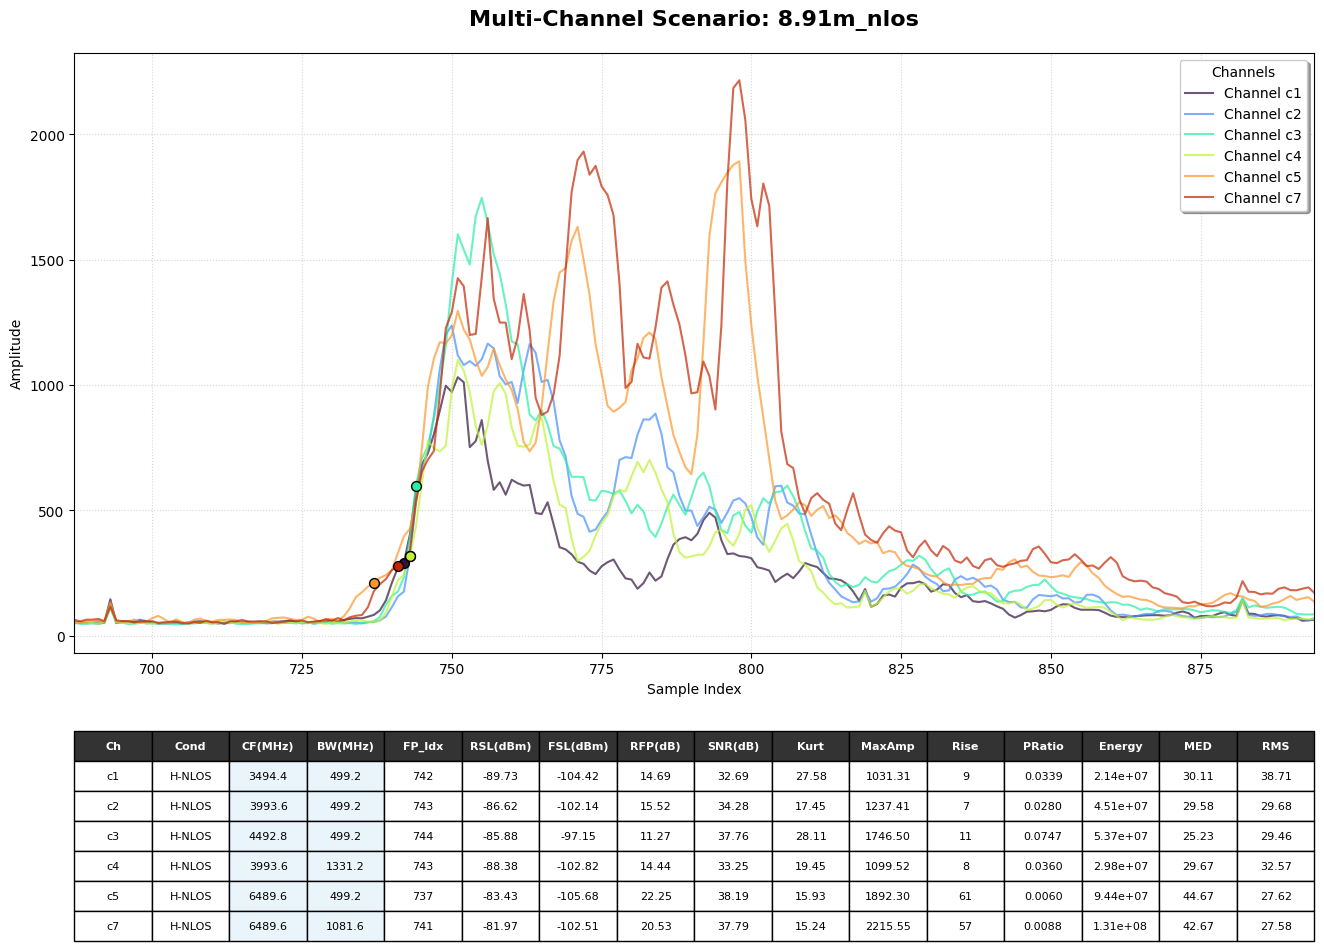

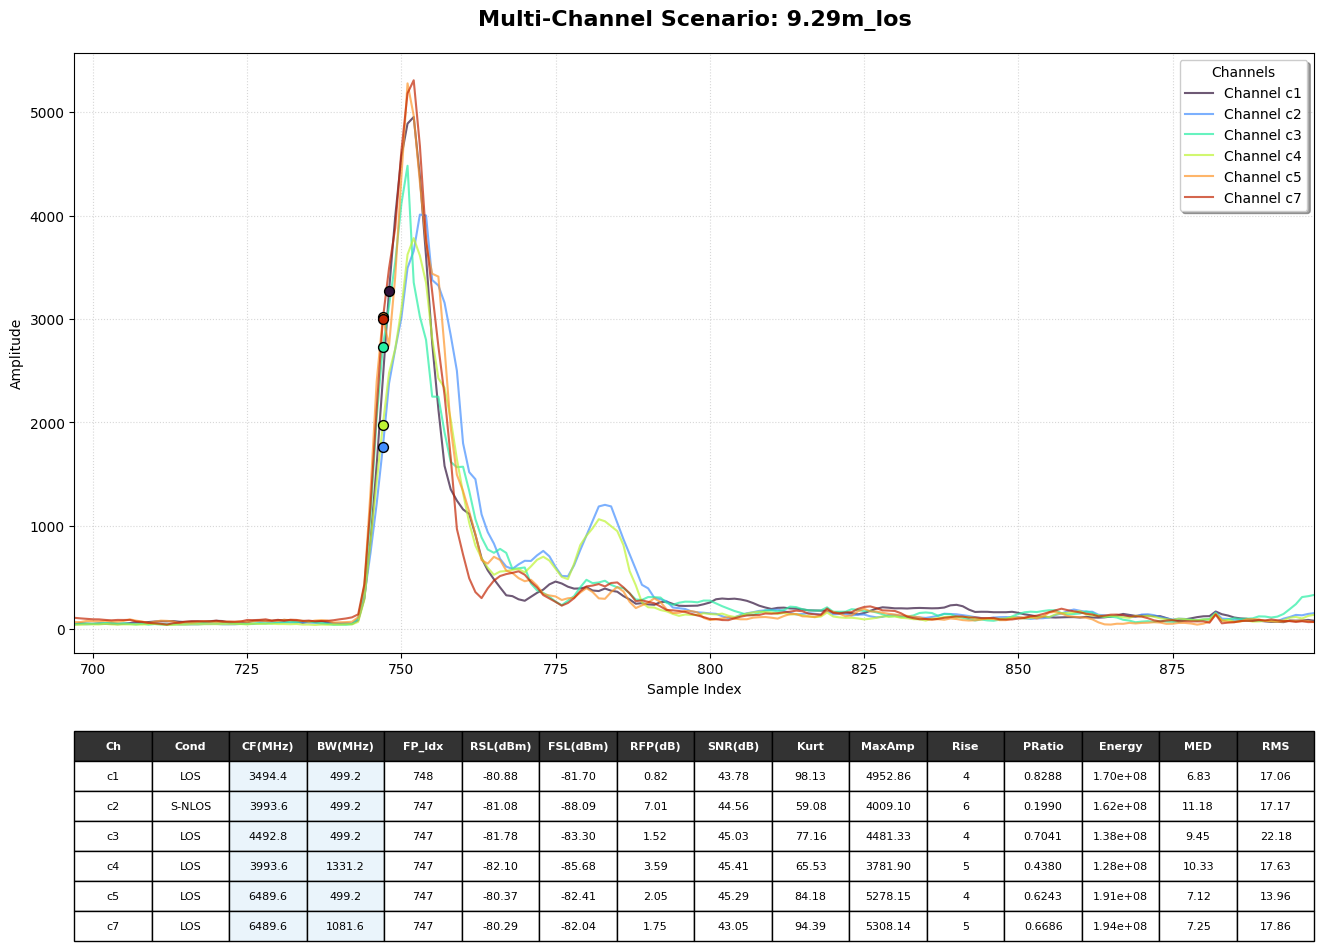

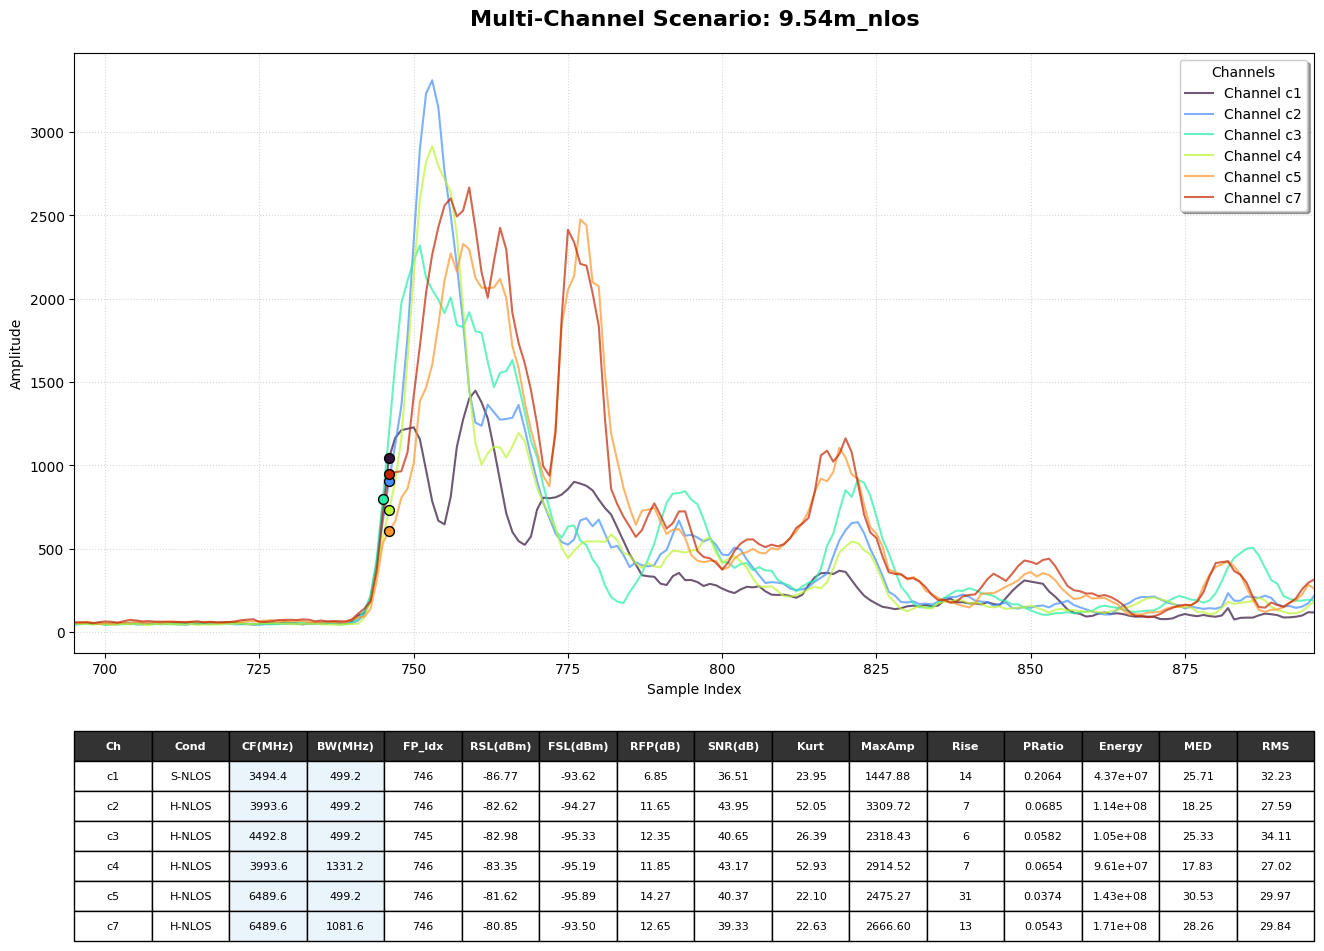

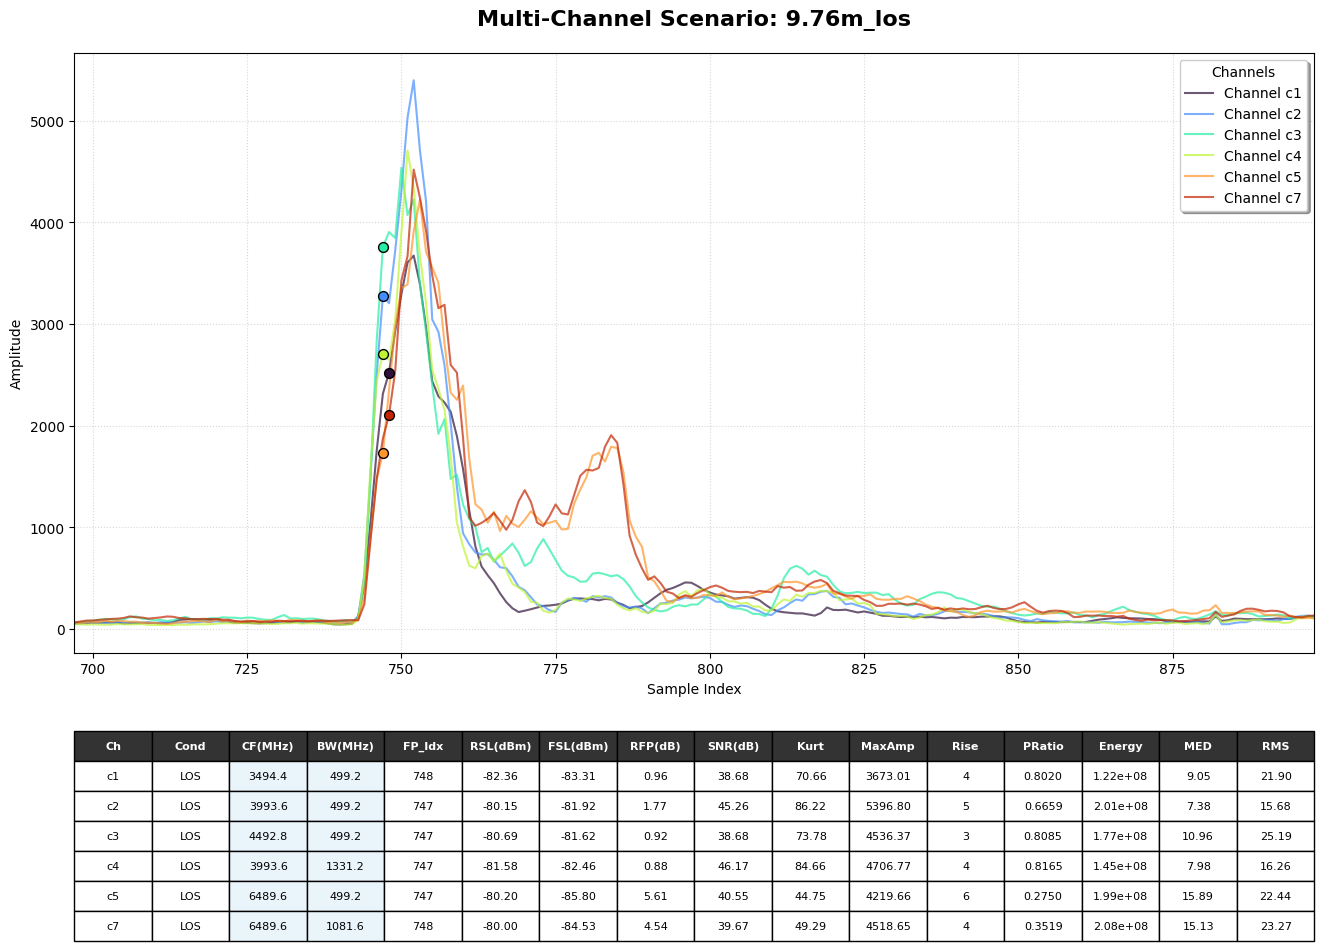

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
import glob
import re
import os

# DW1000 channel specifications (Table 57)
CHANNEL_SPECS = {
    1: {'cf_mhz': 3494.4, 'bw_mhz': 499.2},
    2: {'cf_mhz': 3993.6, 'bw_mhz': 499.2},
    3: {'cf_mhz': 4492.8, 'bw_mhz': 499.2},
    4: {'cf_mhz': 3993.6, 'bw_mhz': 1331.2},
    5: {'cf_mhz': 6489.6, 'bw_mhz':  499.2},
    7: {'cf_mhz': 6489.6, 'bw_mhz': 1081.6},
}

# Metric calculation
def get_original_metrics(filepath):
    try:
        df = pd.read_csv(filepath)
        cir_cols = sorted([c for c in df.columns if c.startswith('CIR')], key=lambda x: int(x.replace('CIR', '')))
        if not cir_cols: return None

        # Waveform: mean of all rows
        avg_wave = np.mean(df[cir_cols].values, axis=0)

        # Constants and signal strength
        A = 121.74
        N = df['RXPACC'].mean() if 'RXPACC' in df.columns else (df['RXP_ACC'].mean() if 'RXP_ACC' in df.columns else 128.0)

        # RSL and total energy
        total_energy = np.sum(avg_wave**2)
        C = df['CIR_PWR'].mean() if 'CIR_PWR' in df.columns else total_energy / (2**17)
        RSL = 10 * np.log10((max(C, 1e-9) * (2**17)) / (N**2)) - A

        # FSL (first path), using the hardware FP_INDEX/64
        hw_fp_idx = int(df['FP_INDEX'].mean() / 64)
        if 'FP_AMPL1' in df.columns:
            f1, f2, f3 = df['FP_AMPL1'].mean(), df['FP_AMPL2'].mean(), df['FP_AMPL3'].mean()
        else:
            f1, f2, f3 = avg_wave[max(0, hw_fp_idx-1)], avg_wave[hw_fp_idx], avg_wave[min(len(avg_wave)-1, hw_fp_idx+1)]

        fp_energy = (f1**2 + f2**2 + f3**2)
        FSL = 10 * np.log10(max(fp_energy, 1e-9) / (N**2)) - A
        RFP = RSL - FSL

        # Condition from RFP
        if RFP < 6.0:   condition = "LOS"
        elif RFP <= 10.0: condition = "S-NLOS"
        else:             condition = "H-NLOS"

        # Peak, rise time and power ratio
        max_amp  = np.max(avg_wave)
        peak_idx = np.argmax(avg_wave)
        rise_time    = peak_idx - hw_fp_idx
        power_ratio  = fp_energy / max(total_energy, 1e-9)

        std_noise = df['STD_NOISE'].mean() if 'STD_NOISE' in df.columns else np.std(avg_wave[0:30])
        SNR = 20 * np.log10(max_amp / (std_noise + 1e-9))

        # Delay spread
        pdp     = avg_wave[hw_fp_idx:]**2
        pwr_sum = np.sum(pdp) + 1e-9
        mean_delay = np.sum(pdp * np.arange(len(pdp))) / pwr_sum
        rms_delay  = np.sqrt(max(0, (np.sum(pdp * (np.arange(len(pdp))**2)) / pwr_sum) - (mean_delay**2)))

        # Channel specs lookup
        ch_match = re.search(r'_c(\d+)\.csv', filepath)
        ch_num   = int(ch_match.group(1)) if ch_match else None
        specs    = CHANNEL_SPECS.get(ch_num, {'cf_mhz': 'N/A', 'bw_mhz': 'N/A'})

        return {
            "Ch":    re.search(r'_(c\d+)\.csv', filepath).group(1),
            "Wave":  avg_wave, "FP": hw_fp_idx, "Cond": condition,
            "CF":    f"{specs['cf_mhz']:.1f}",
            "BW":    f"{specs['bw_mhz']:.1f}",
            "RSL":   f"{RSL:.2f}", "FSL": f"{FSL:.2f}", "RFP": f"{RFP:.2f}",
            "SNR":   f"{SNR:.2f}", "Kurt": f"{kurtosis(avg_wave):.2f}",
            "MaxAmp": f"{max_amp:.2f}", "Rise": f"{rise_time}",
            "PRatio": f"{power_ratio:.4f}", "Energy": f"{total_energy:.2e}",
            "MED":   f"{mean_delay:.2f}", "RMS": f"{rms_delay:.2f}",
        }
    except Exception:
        return None


def plot_overlay_with_table(scenario_prefix):
    files = sorted(glob.glob(f"{scenario_prefix}_c*.csv"),
                   key=lambda x: int(re.search(r'_c(\d+)', x).group(1)))
    if not files: return

    results = [get_original_metrics(f) for f in files if get_original_metrics(f) is not None]
    if not results: return

    fig, ax = plt.subplots(figsize=(16, 12))
    colors = plt.cm.turbo(np.linspace(0, 0.9, len(results)))

    for i, res in enumerate(results):
        ax.plot(res['Wave'], color=colors[i], label=f"Channel {res['Ch']}", lw=1.5, alpha=0.7)
        ax.scatter(res['FP'], res['Wave'][res['FP']], color=colors[i], s=50, edgecolors='black', zorder=5)

    ax.set_title(f"Multi-Channel Scenario: {os.path.basename(scenario_prefix)}", fontsize=16, fontweight='bold', pad=20)
    ax.set_ylabel("Amplitude")
    ax.set_xlabel("Sample Index")

    all_fps = [res['FP'] for res in results]
    ax.set_xlim(min(all_fps) - 50, max(all_fps) + 150)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend(loc='upper right', title="Channels", shadow=True)

    # Table, including CF (MHz) and BW (MHz)
    headers = ["Ch", "Cond", "CF(MHz)", "BW(MHz)", "FP_Idx",
               "RSL(dBm)", "FSL(dBm)", "RFP(dB)", "SNR(dB)",
               "Kurt", "MaxAmp", "Rise", "PRatio", "Energy", "MED", "RMS"]
    rows = [[r['Ch'], r['Cond'], r['CF'], r['BW'], r['FP'],
             r['RSL'], r['FSL'], r['RFP'], r['SNR'],
             r['Kurt'], r['MaxAmp'], r['Rise'], r['PRatio'], r['Energy'],
             r['MED'], r['RMS']] for r in results]

    table = plt.table(cellText=rows, colLabels=headers, loc='bottom',
                      cellLoc='center', bbox=[0, -0.48, 1, 0.35])
    table.auto_set_font_size(False)
    table.set_fontsize(8.0)

    for (row, col), cell in table.get_celld().items():
        if row == 0:
            cell.set_text_props(weight='bold', color='white')
            cell.set_facecolor('#333333')
        # Highlight CF and BW columns (cols 2 and 3)
        elif col in (2, 3):
            cell.set_facecolor('#eaf4fb')

    plt.subplots_adjust(bottom=0.38)
    plt.show()


# Run on every scenario in dataset/channels/
all_csvs = glob.glob(os.path.join(CHANNEL_DIR, "*.csv"))
unique_scenarios = sorted(list(set([re.sub(r'_c\d+\.csv$', '', f) for f in all_csvs if "_c" in f])))
for s in unique_scenarios:
    plot_overlay_with_table(s)


## 2.1 Multi-Channel Analysis: Results

The table under each plot gives metrics of the mean waveform per channel:
- CF / BW: centre frequency and bandwidth (DW1000 datasheet, Table 57)
- RFP: RSL - FSL; below 6 dB is classed as LOS, 6 to 10 dB as soft NLOS and above 10 dB as hard NLOS
- Kurt: how peaked the CIR is
- Rise: samples from the hardware first path to the strongest peak
- MED / RMS: mean excess delay and RMS delay spread, in samples

#### LOS scenarios

29 of the 30 LOS recordings (5 scenarios x 6 channels) have an RFP below 6 dB; the exception is 9.29 m on C2 (7.0 dB). Kurtosis lies between 45 and 116, the rise time is mostly 2 to 6 samples, MED 5 to 16 and RMS 11 to 27. C4, the channel with the widest bandwidth (1331.2 MHz), has the highest kurtosis (116 at 4.55 m) and the lowest RMS delay spread (11.2).

#### NLOS 12.79 m (d_direct = 8.82 m)

| Ch | CF (MHz) | BW (MHz) | Cond | RFP | Kurtosis | Rise | MED | RMS |
|----|---------|---------|------|-----|---------|------|-----|-----|
| C1 | 3494.4 | 499.2 | S-NLOS | 7.77 | 42.95 | 9 | 23.43 | 45.11 |
| C2 | 3993.6 | 499.2 | LOS | 1.59 | 73.42 | 2 | 24.66 | 53.49 |
| C3 | 4492.8 | 499.2 | S-NLOS | 9.14 | 45.37 | 7 | 23.16 | 45.31 |
| C4 | 3993.6 | 1331.2 | LOS | 3.11 | 73.55 | 2 | 27.62 | 57.27 |
| C5 | 6489.6 | 499.2 | S-NLOS | 8.27 | 56.85 | 7 | 19.54 | 42.06 |
| C7 | 6489.6 | 1081.6 | S-NLOS | 7.81 | 58.18 | 6 | 14.75 | 30.66 |

C2 and C4 are classed as LOS (RFP 1.59 and 3.11) although the scenario is NLOS. On these channels the hardware locks onto the bounce (they report 12.8 and 12.6 m), and the strong, sharp bounce pulse looks like a direct path to the RFP metric. Only C1 reports a distance close to the direct path (8.4 m).

#### NLOS 16.09 m (d_direct = 7.20 m)

| Ch | Cond | RFP | Rise | MED | RMS |
|----|------|-----|------|-----|-----|
| C1 | H-NLOS | 11.83 | 33 | 36.07 | 27.74 |
| C2 | H-NLOS | 16.27 | 33 | 36.40 | 26.23 |
| C3 | H-NLOS | 14.85 | 38 | 48.35 | 39.59 |
| C4 | H-NLOS | 14.51 | 34 | 35.23 | 27.67 |
| C5 | H-NLOS | 20.96 | 19 | 36.62 | 37.19 |
| C7 | H-NLOS | 15.20 | 17 | 36.63 | 39.41 |

All six channels give hard NLOS. On C1 to C4 the first path stays near the direct path (they report about 7.5 m) while the strongest energy arrives with the bounce about 30 samples later, hence the rise times of 33 to 38 samples. On C5 and C7 the first path moves later (11.3 and 12.5 m) and the rise time drops to 17 to 19.

#### NLOS 16.80 m (d_direct = 13.06 m)

| Ch | Cond | RFP | Kurtosis | Rise |
|----|------|-----|---------|------|
| C1 | LOS | 4.00 | 31.46 | 3 |
| C2 | S-NLOS | 8.10 | 18.47 | 4 |
| C3 | H-NLOS | 14.09 | 22.40 | 12 |
| C4 | S-NLOS | 8.99 | 19.18 | 5 |
| C5 | S-NLOS | 7.46 | 14.35 | 4 |
| C7 | S-NLOS | 6.55 | 13.42 | 4 |

The direct and reflected paths are only 12.5 samples apart. C1 is classed as LOS and C3 as hard NLOS, and the kurtosis drops to 13 to 31 on all channels, against 45 to 116 in LOS.

No channel classifies every scenario correctly: C2 and C4 miss the NLOS at 12.79 m and C1 misses it at 16.80 m. The models are therefore trained on all six channels and learn from the CIR rather than from these metrics.

## 2.2 Individual Analysis

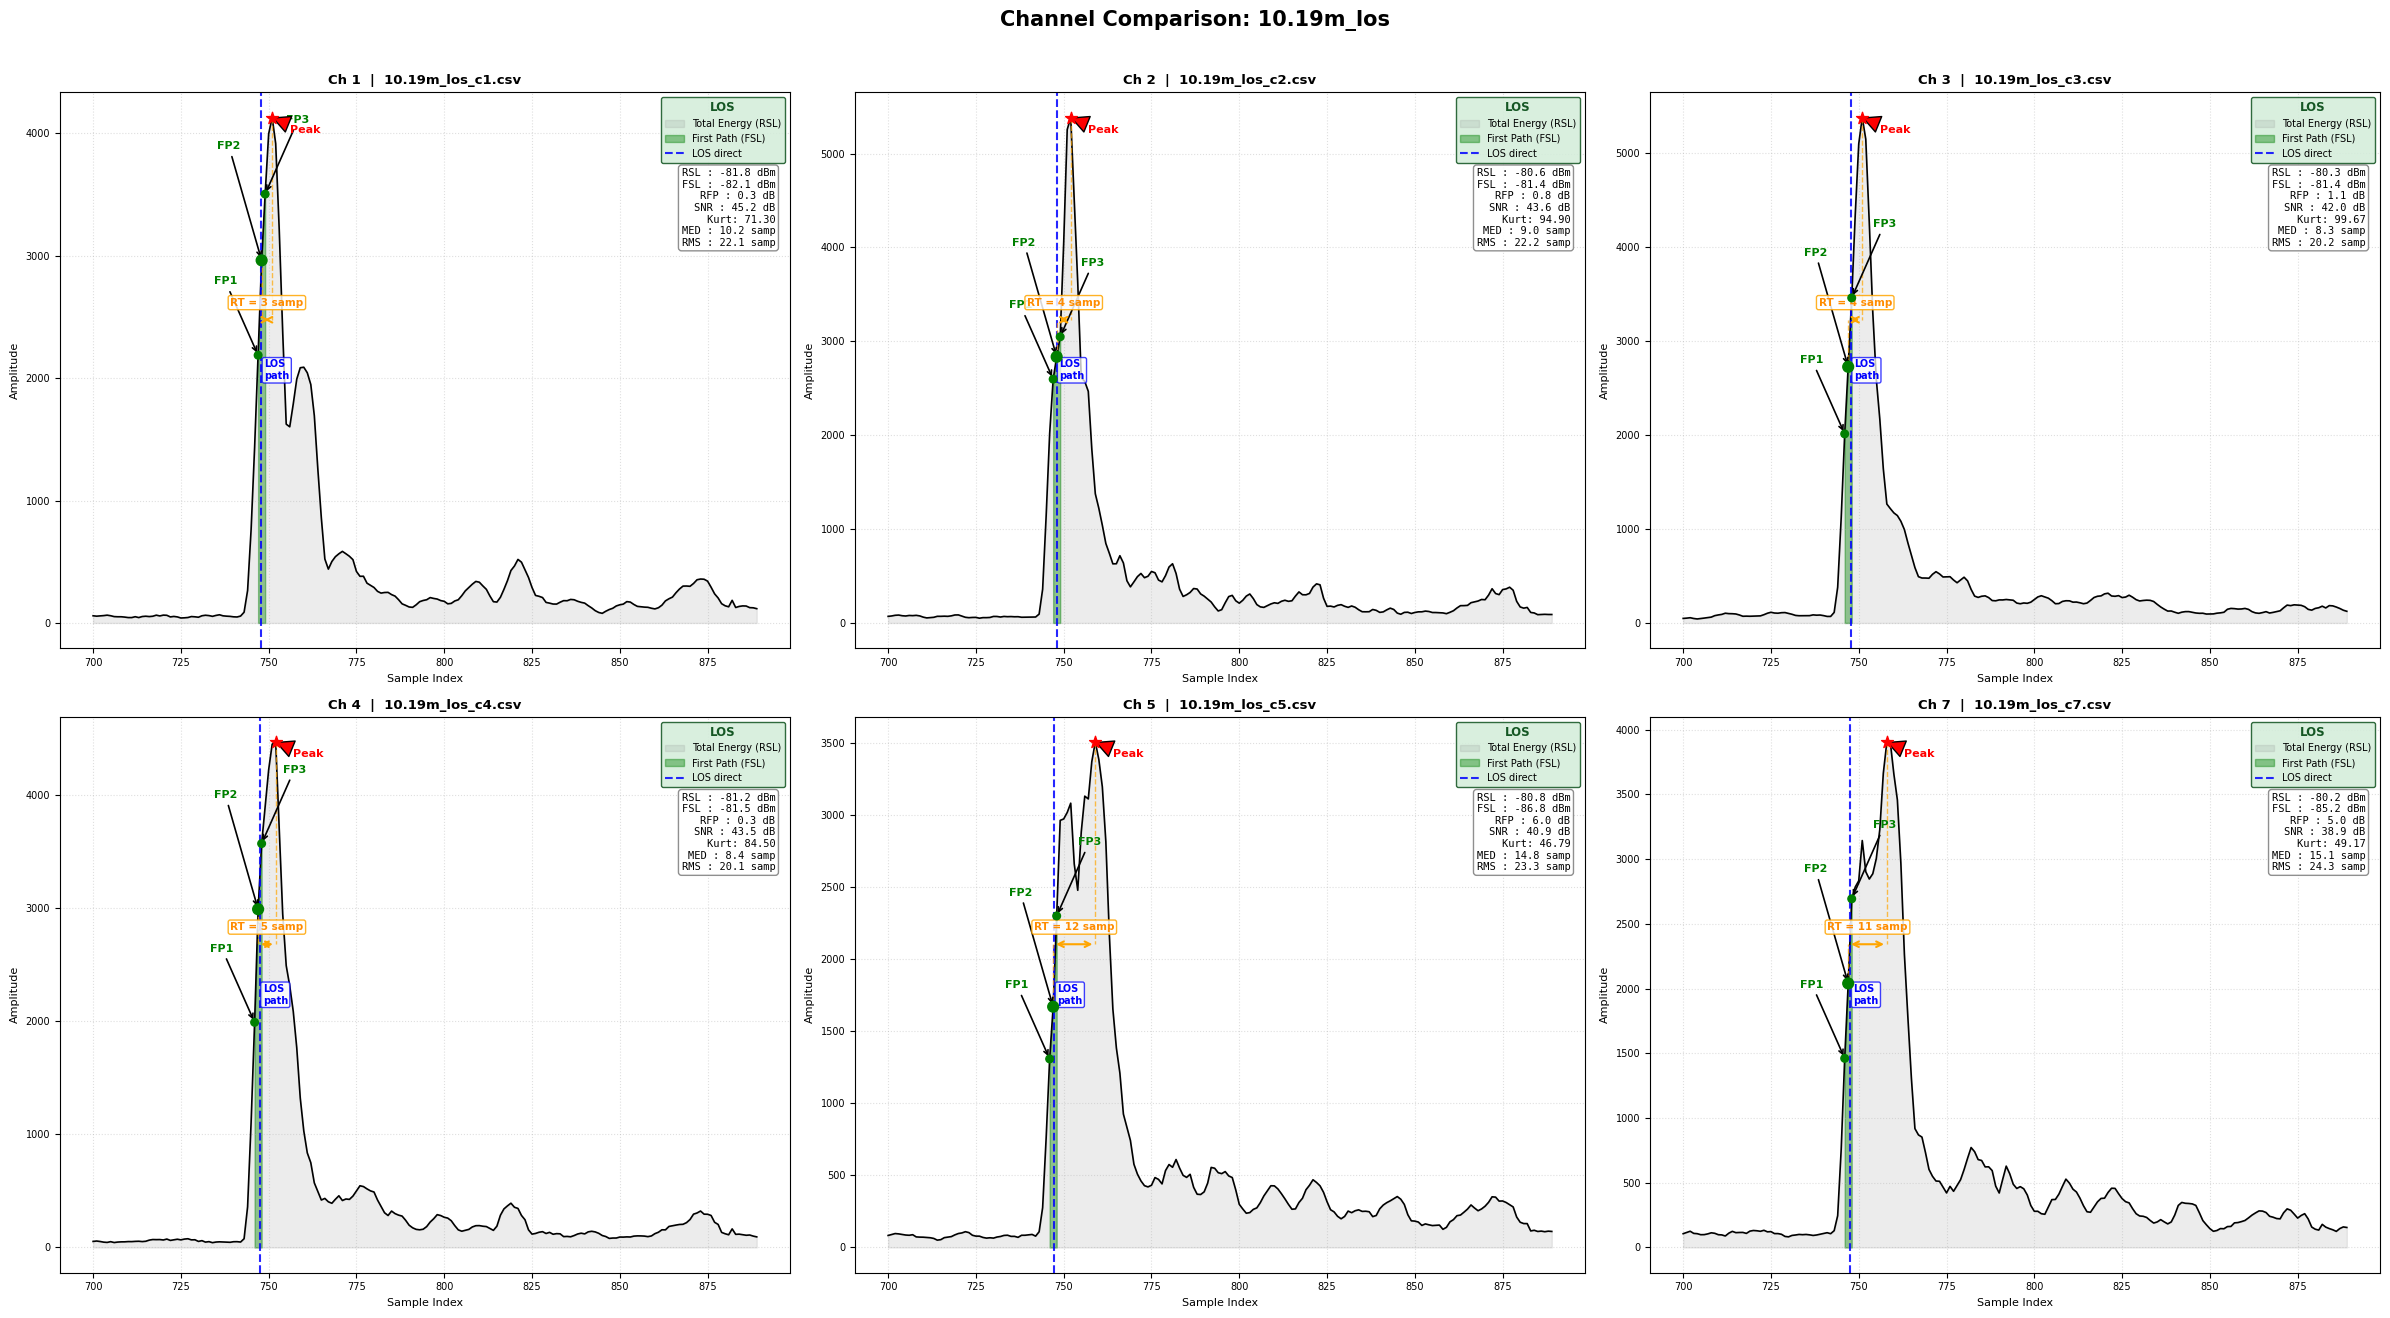

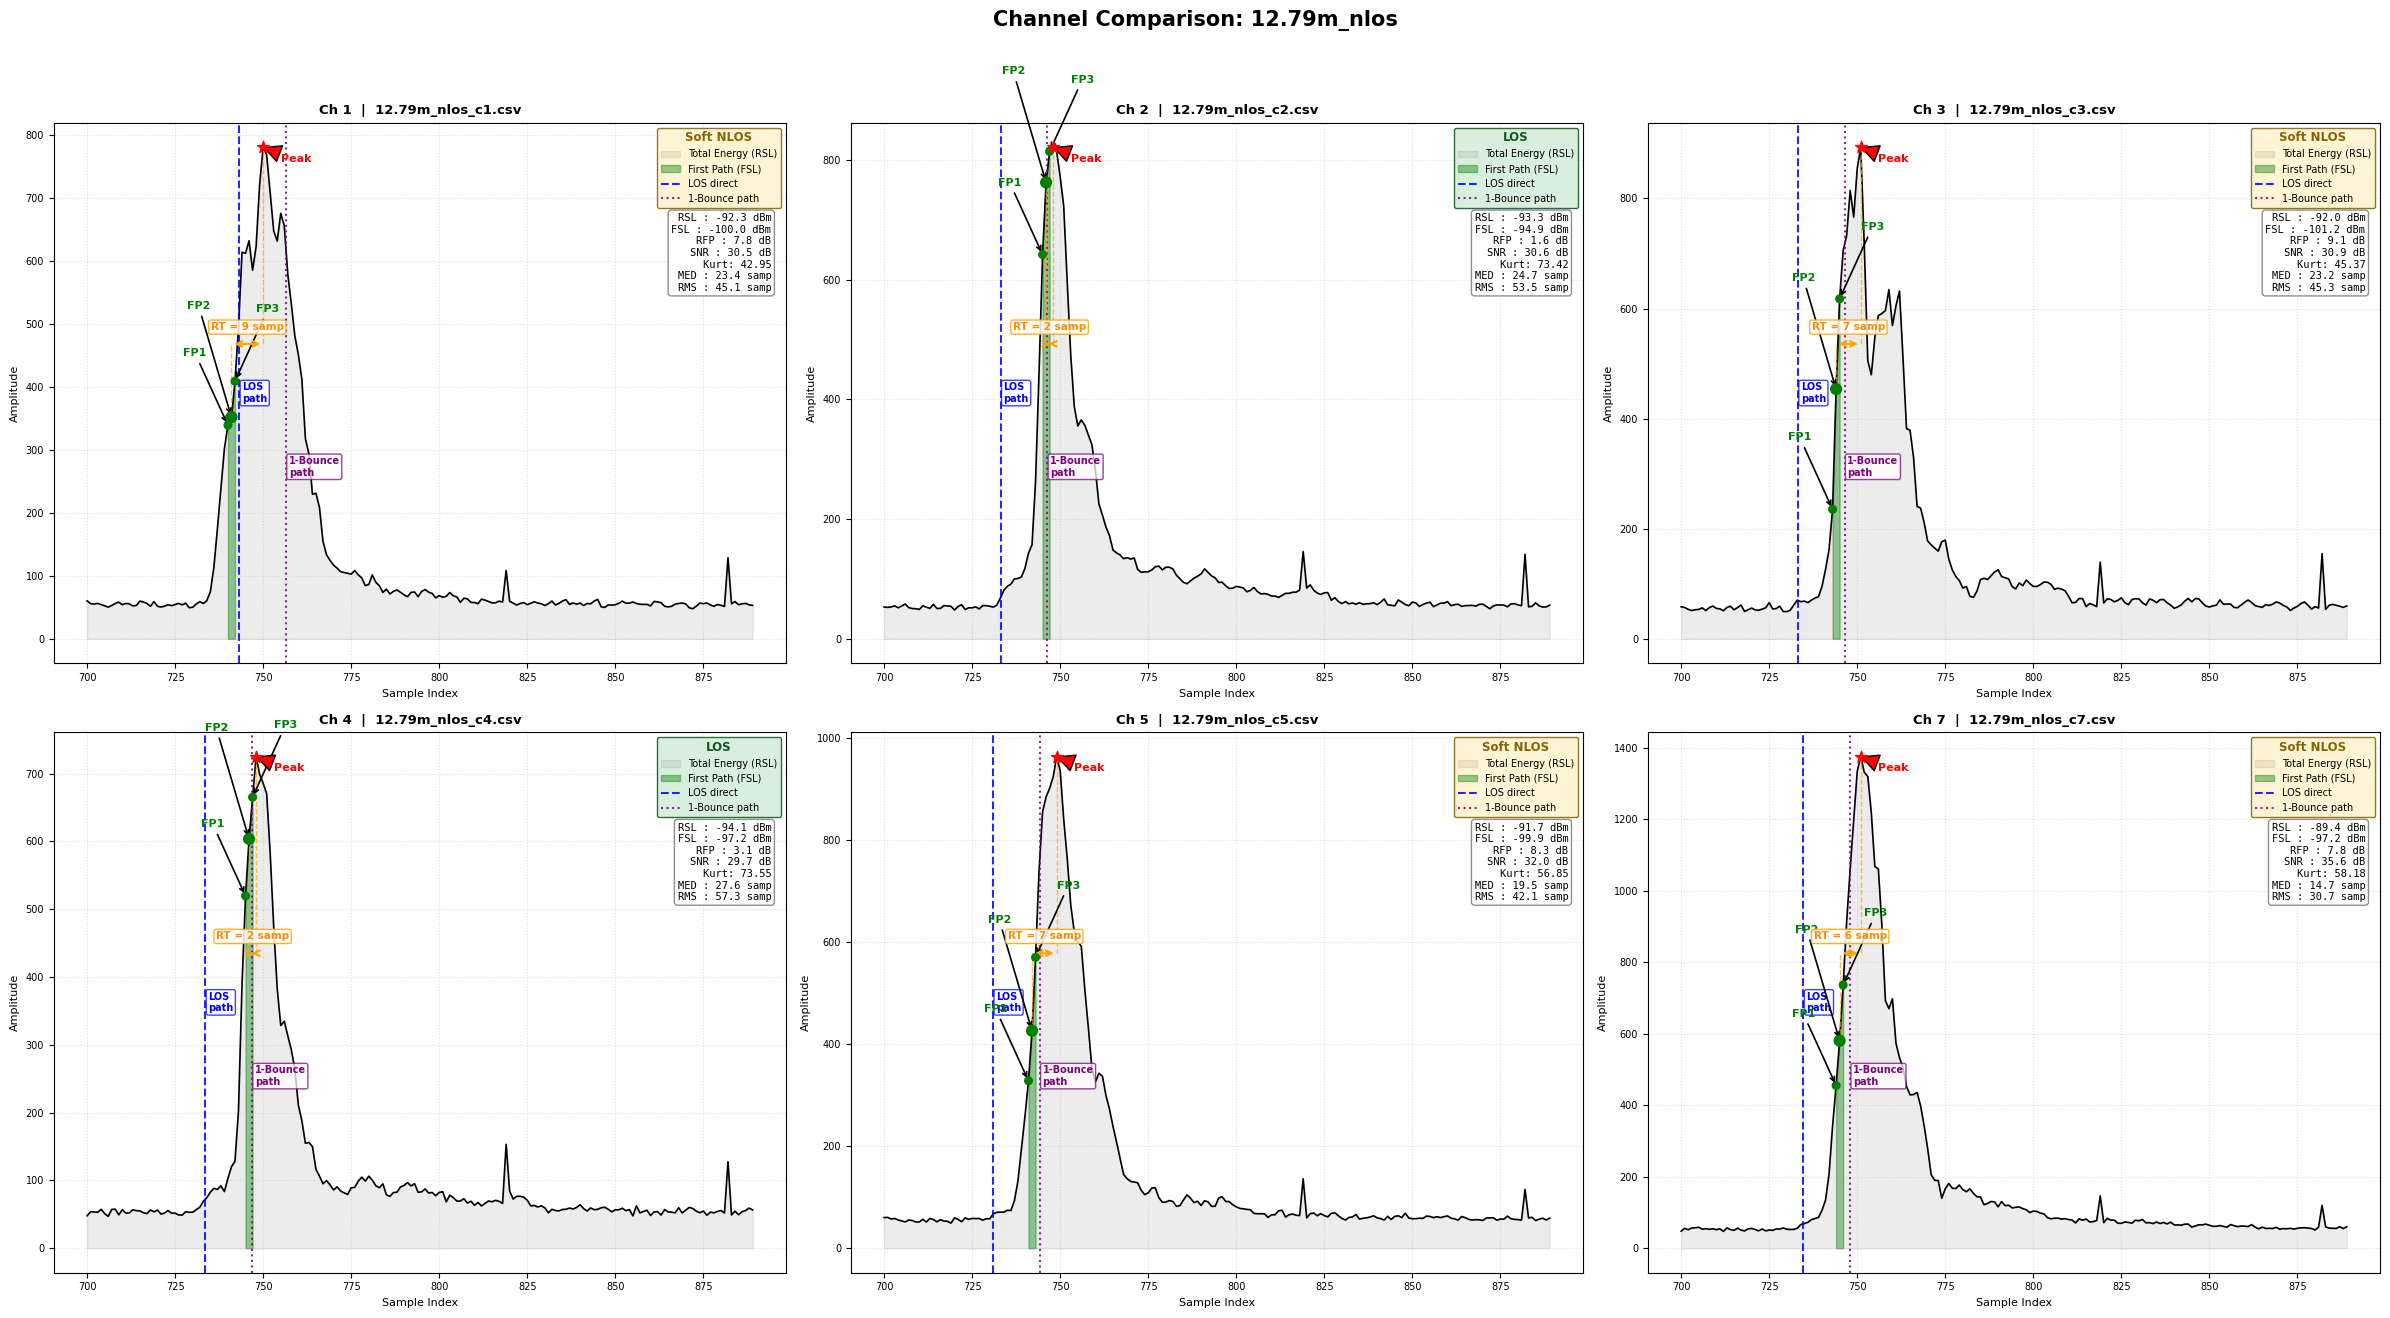

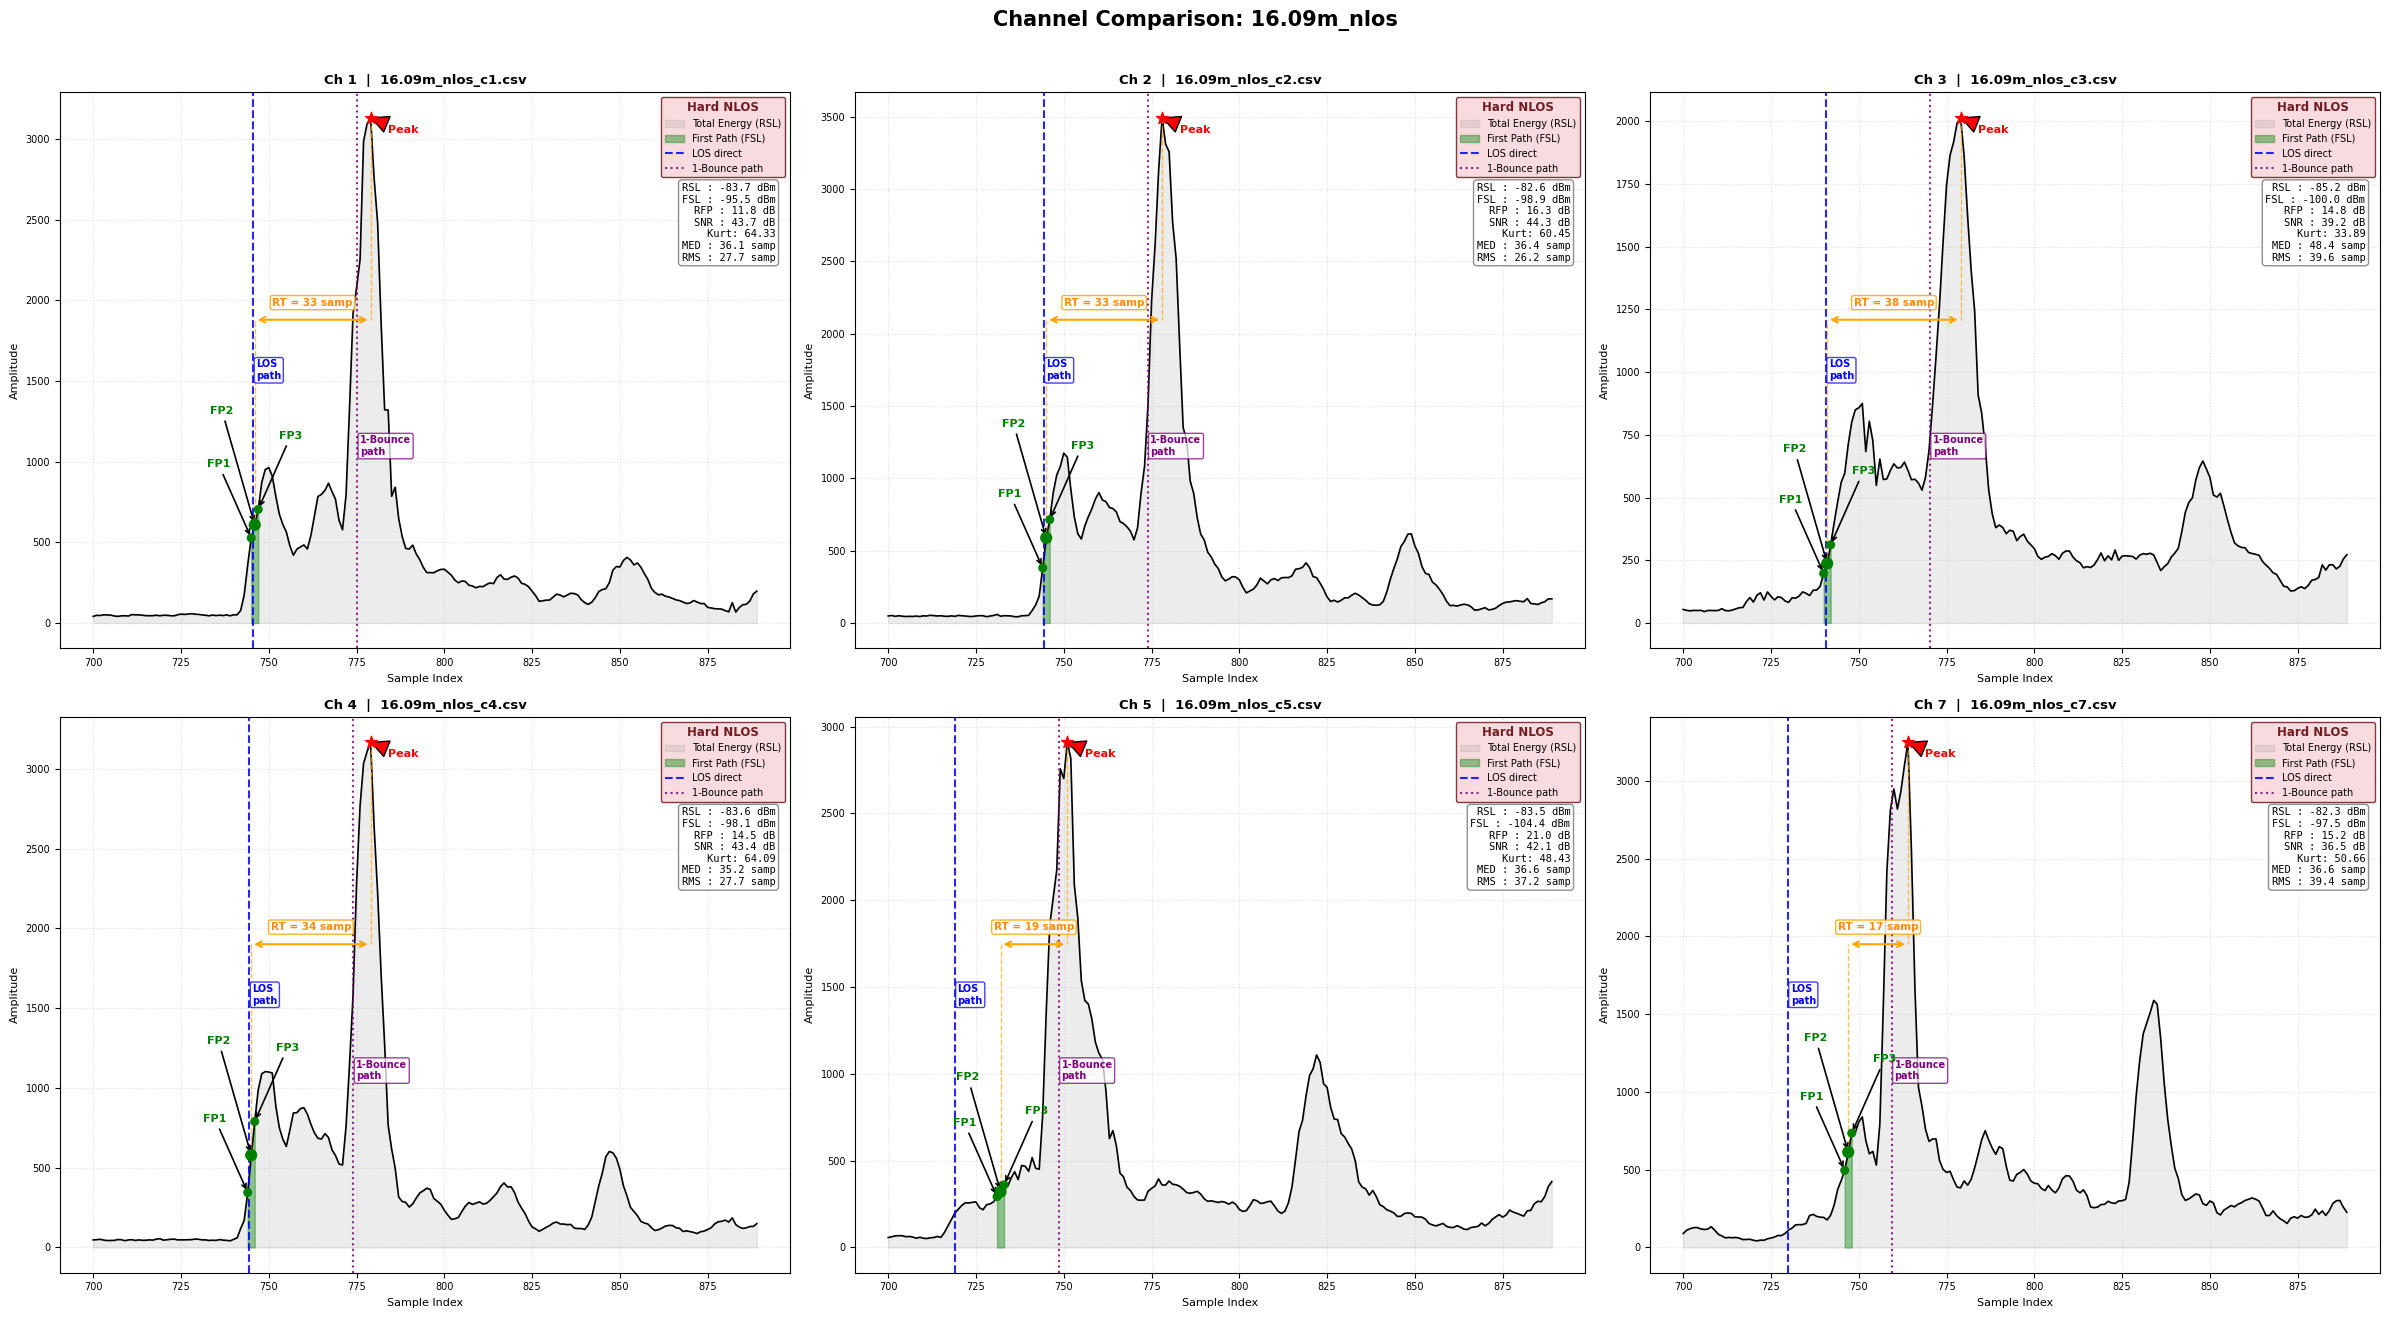

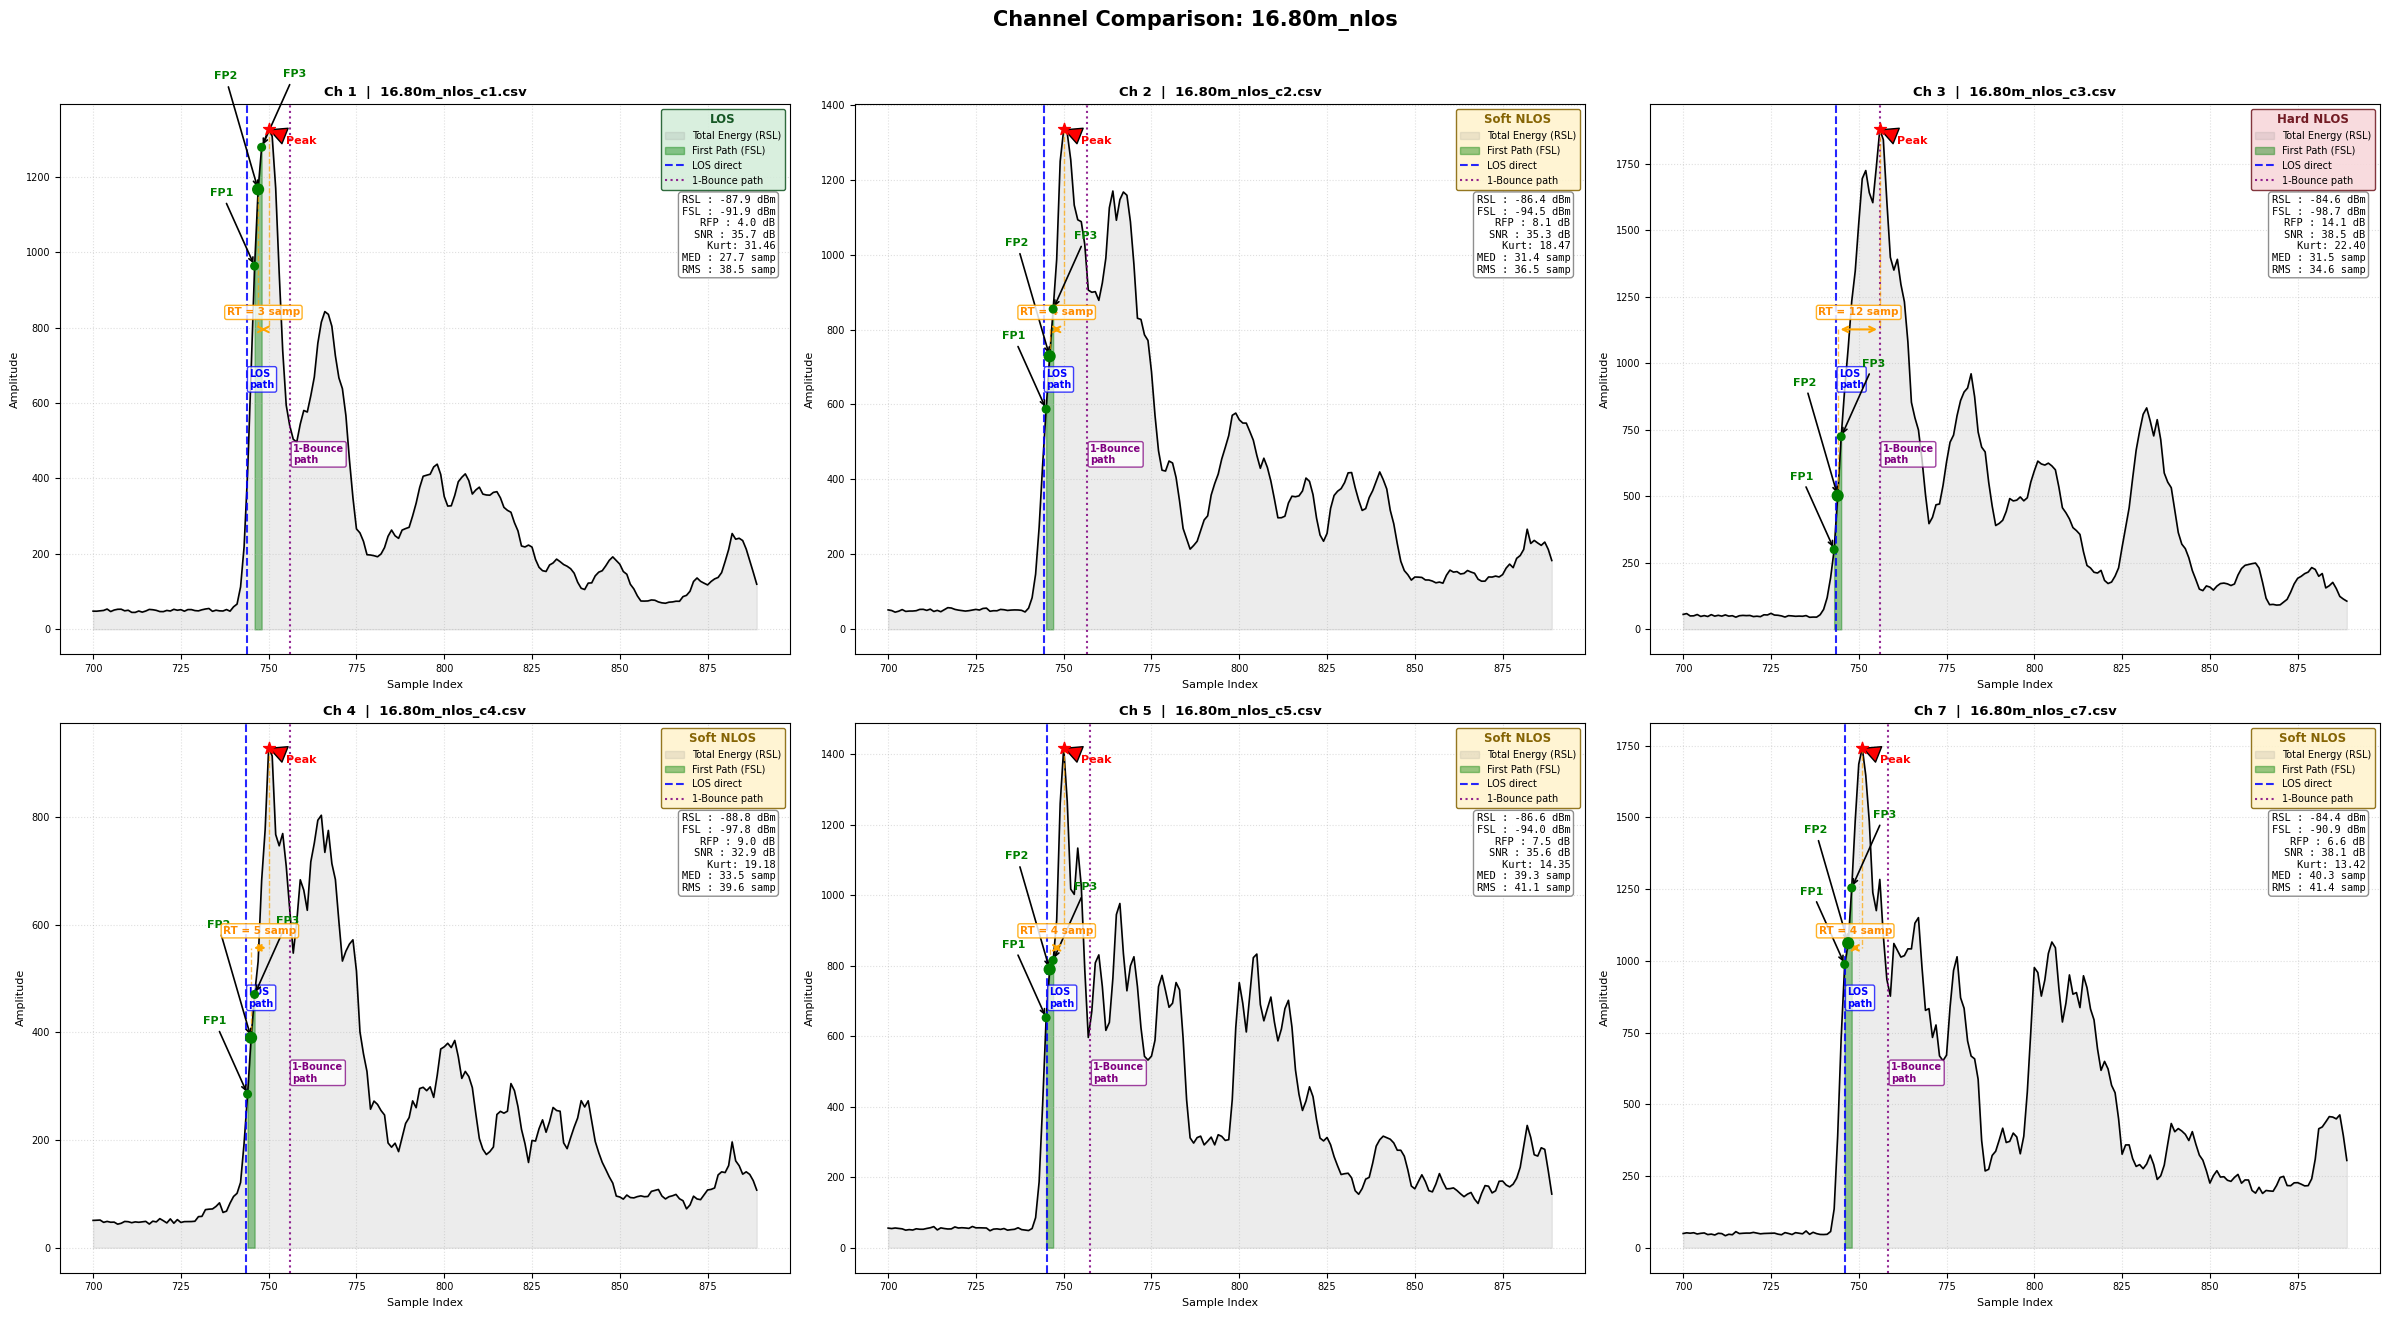

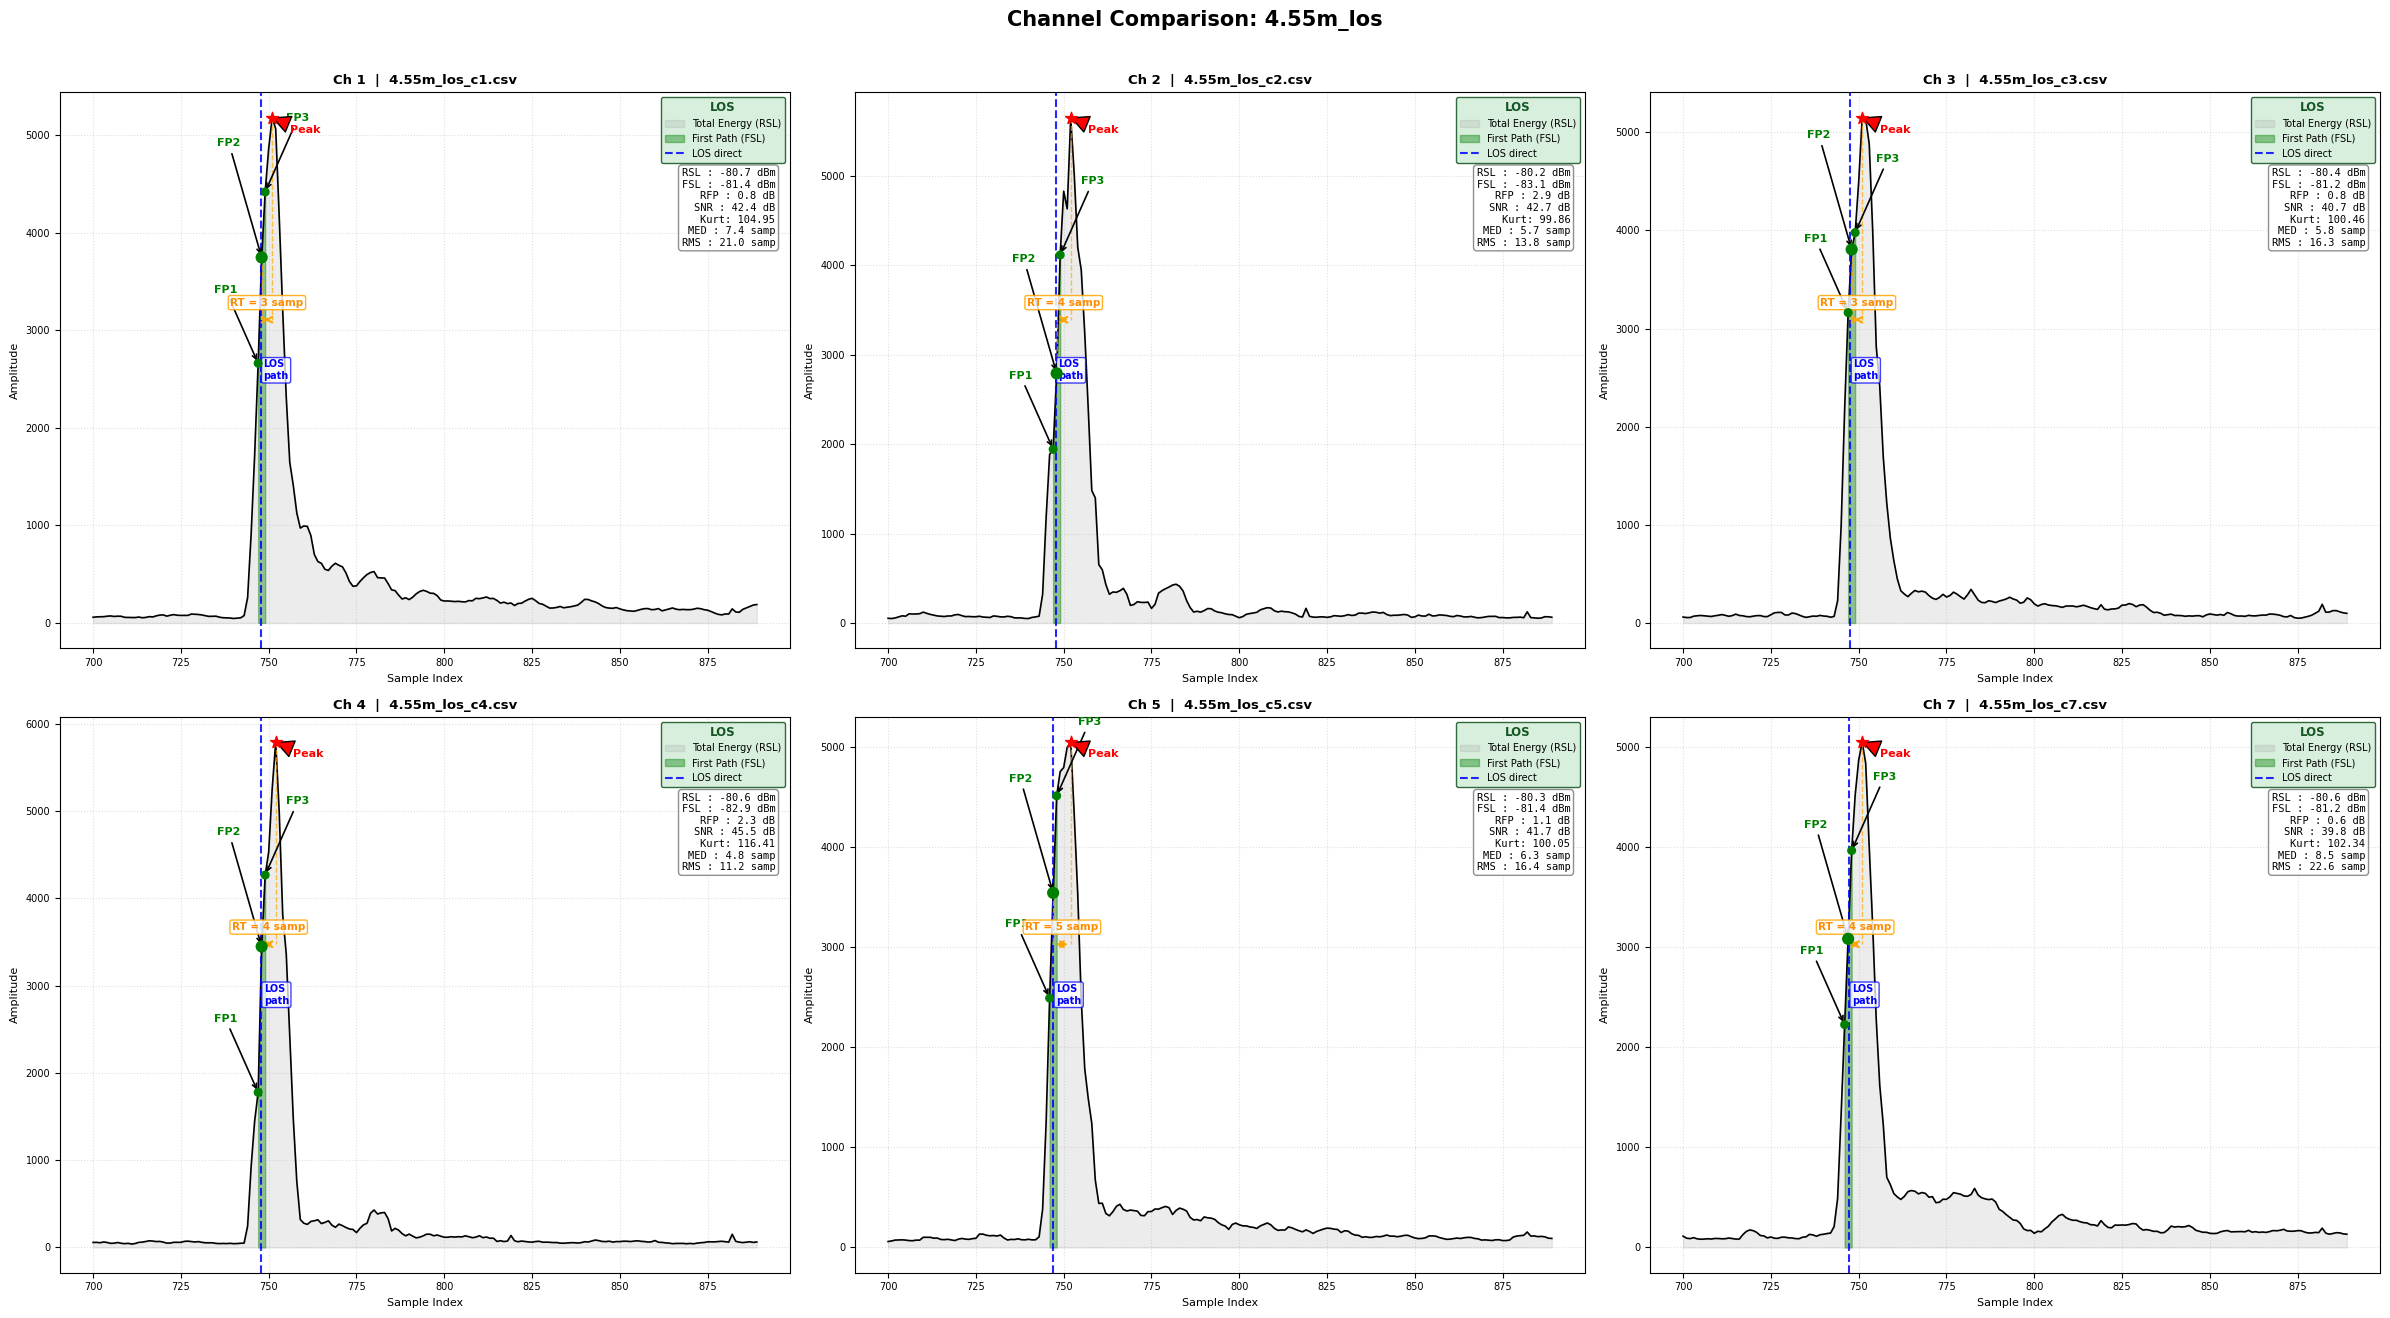

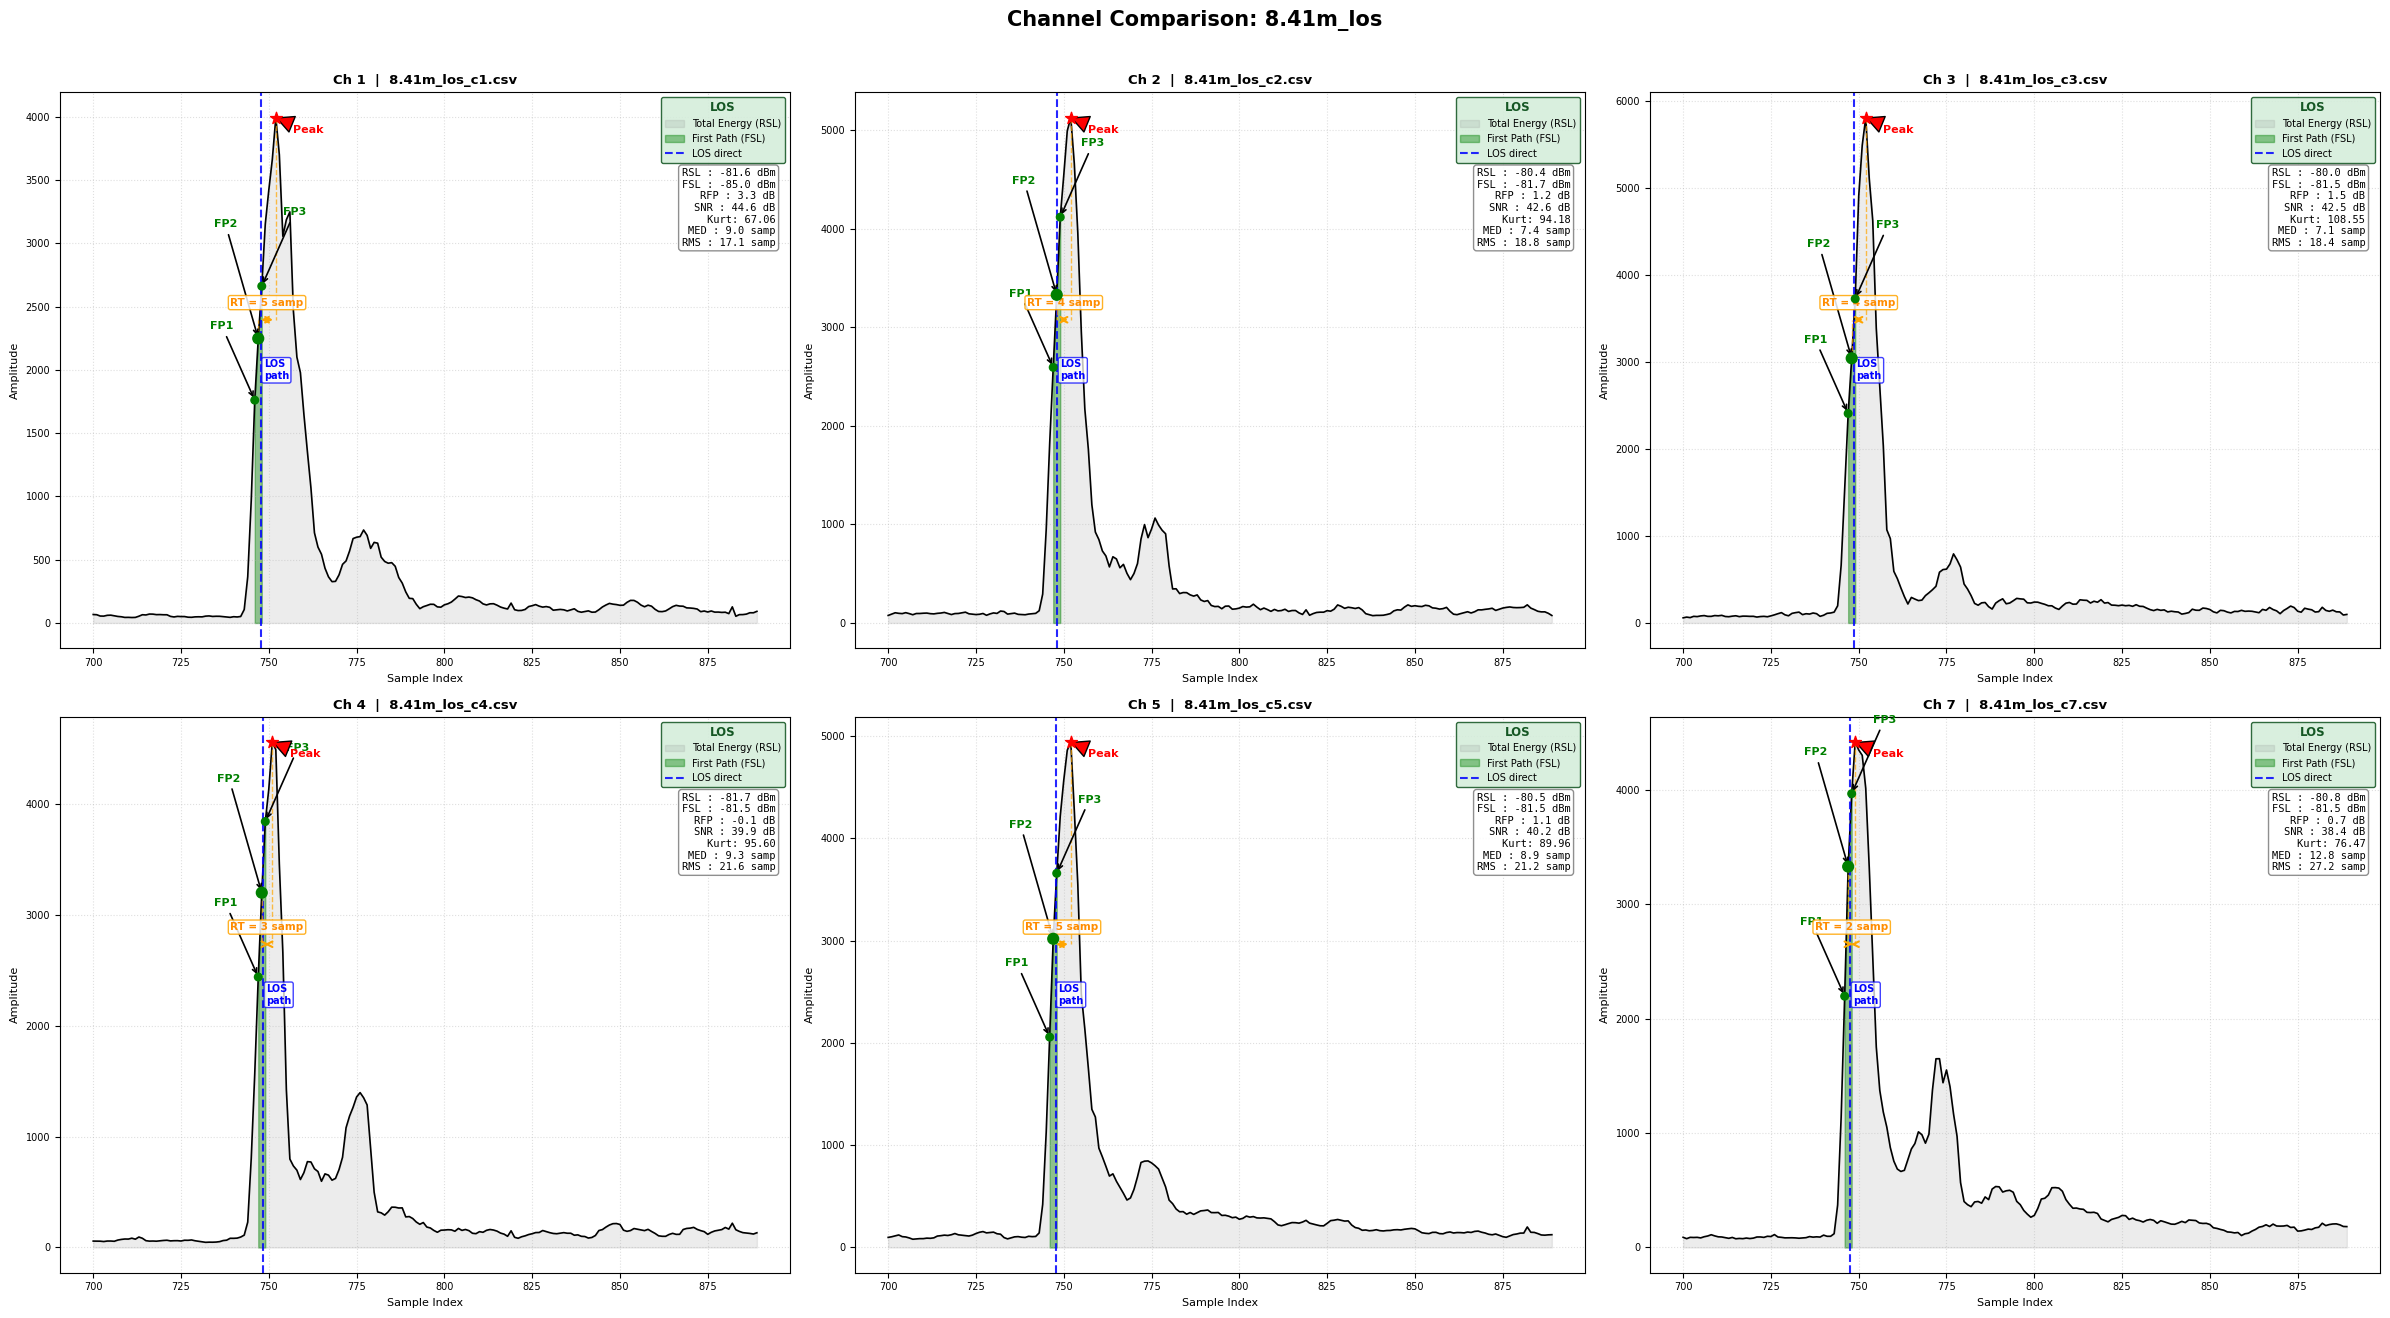

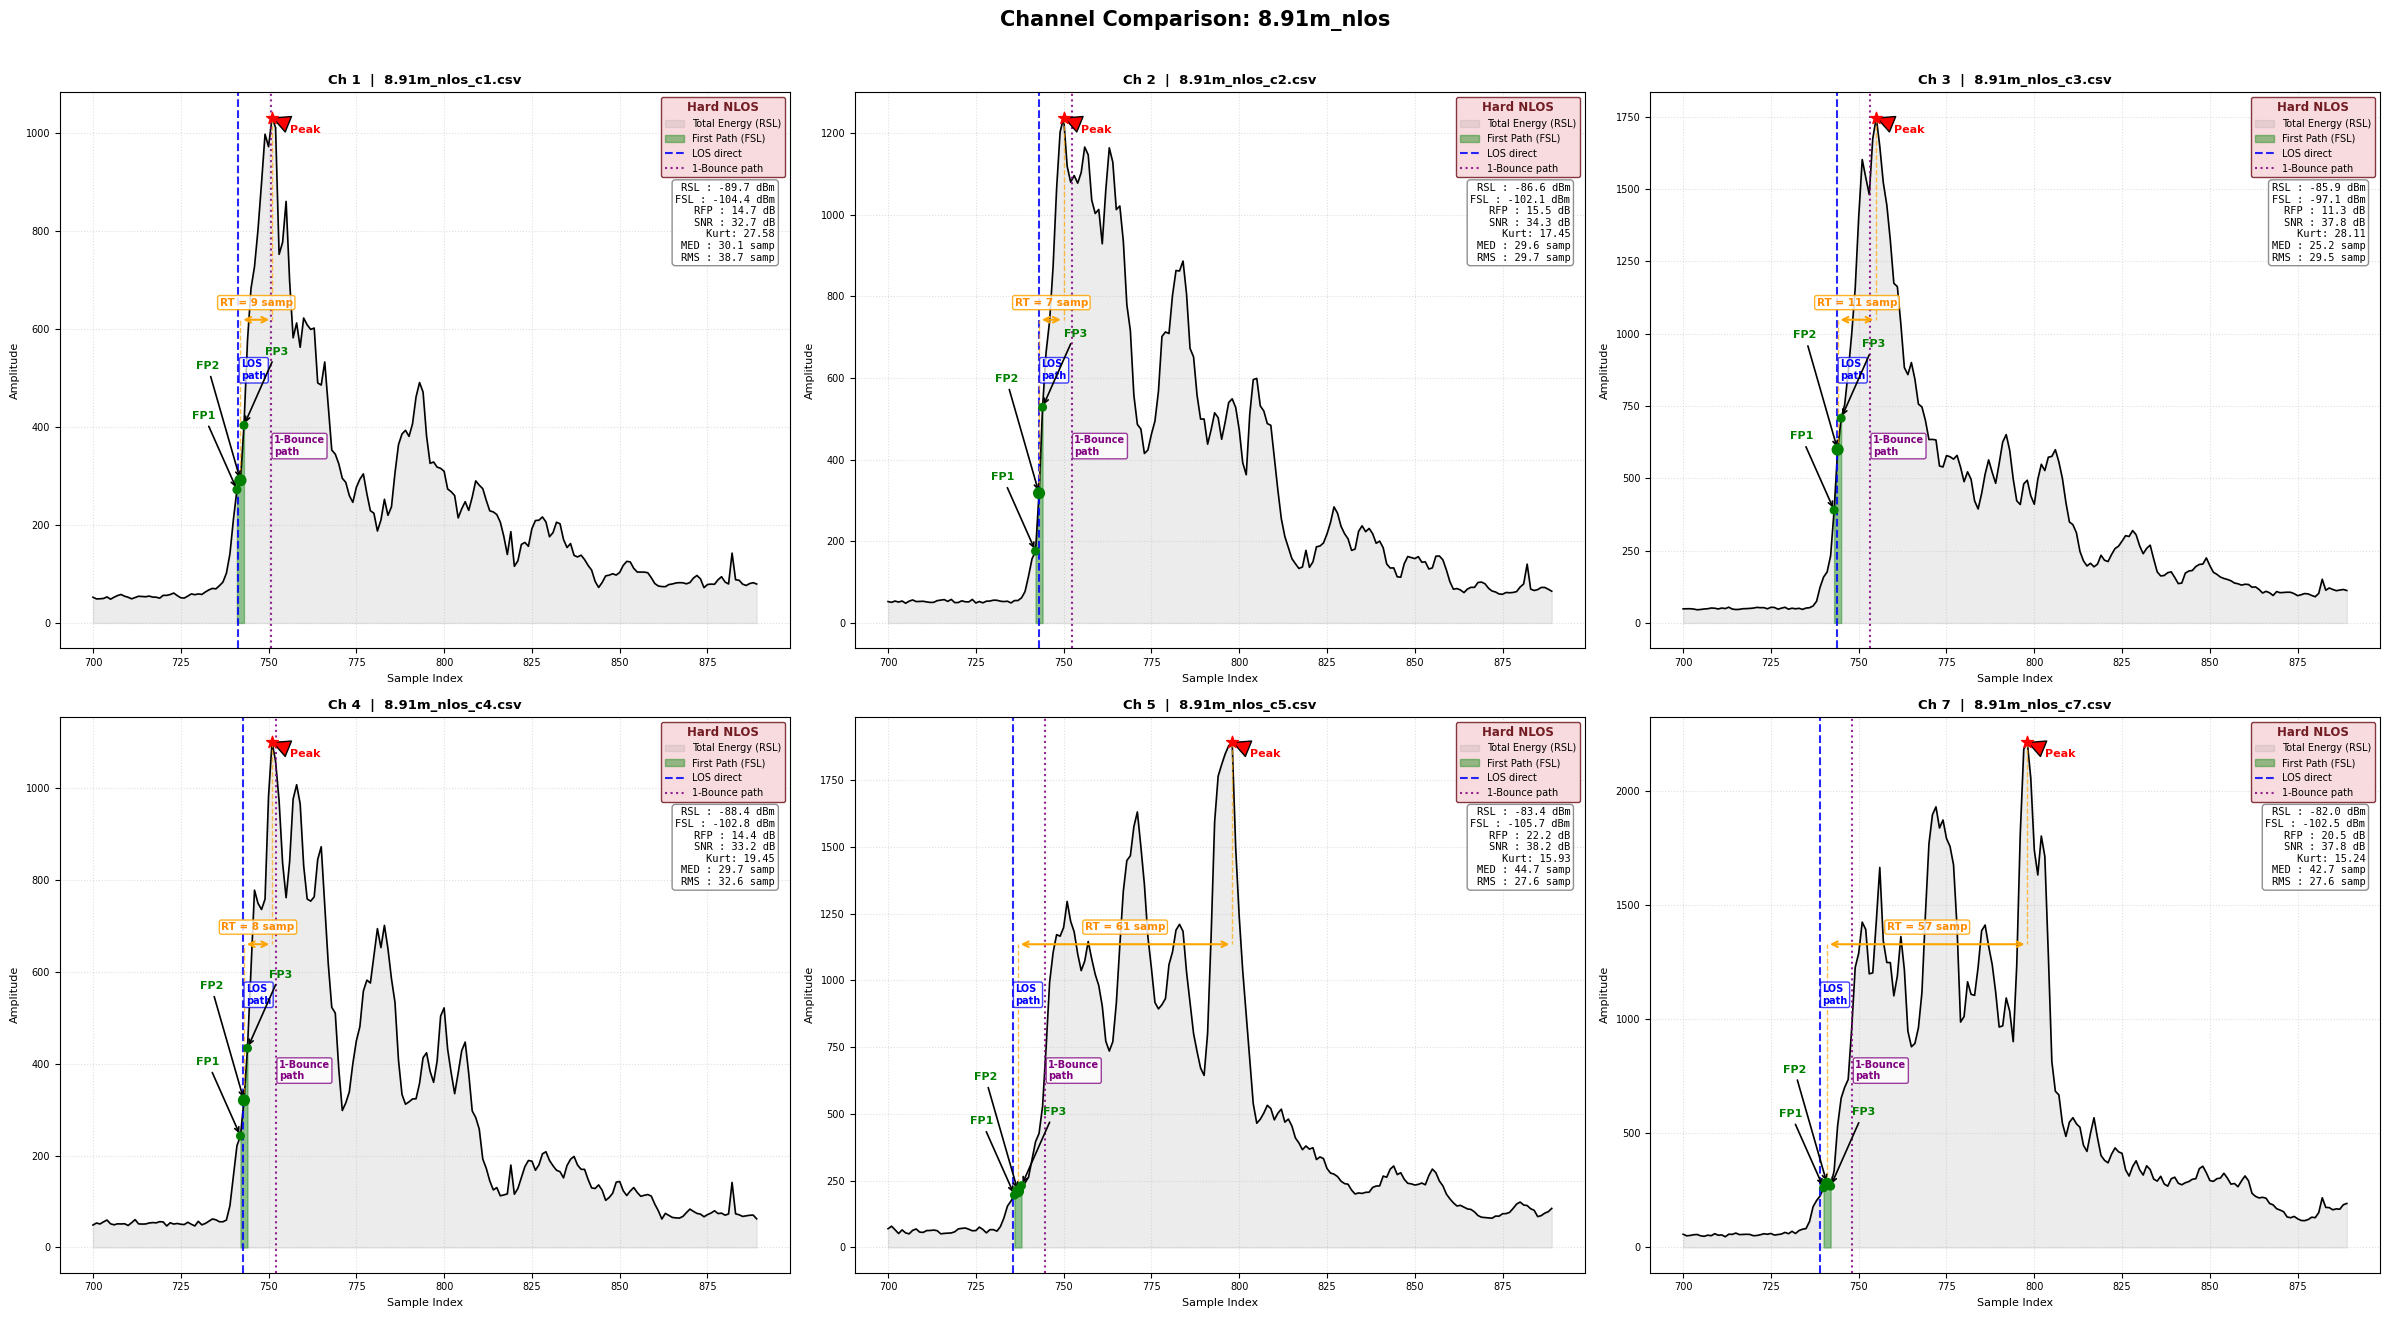

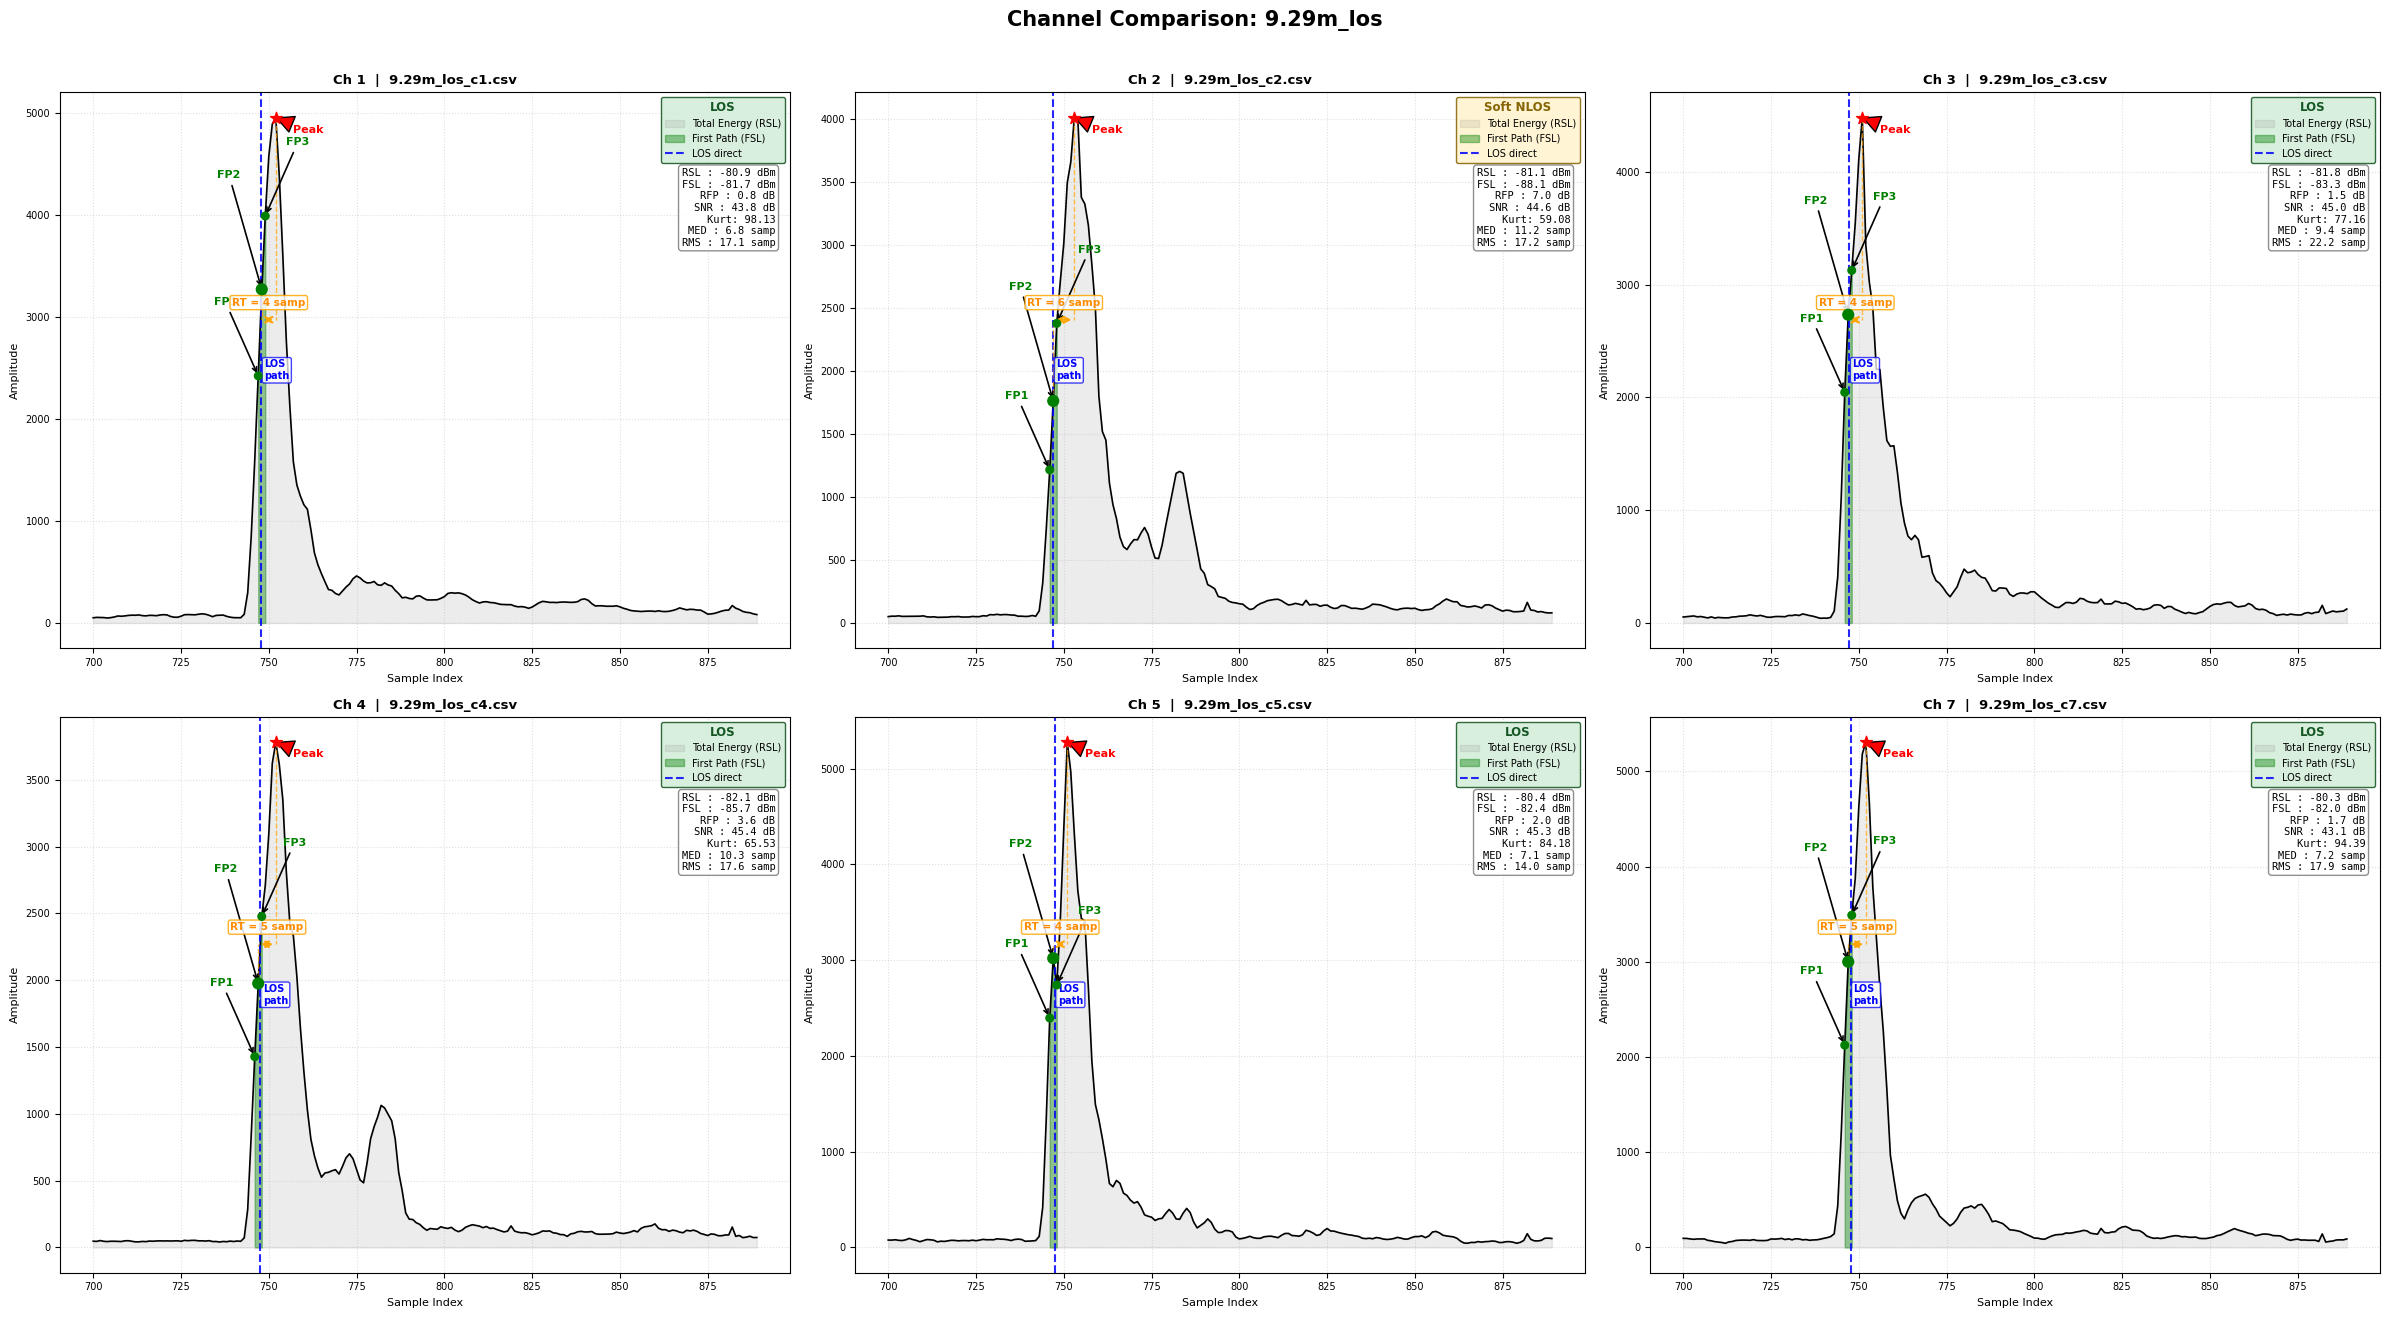

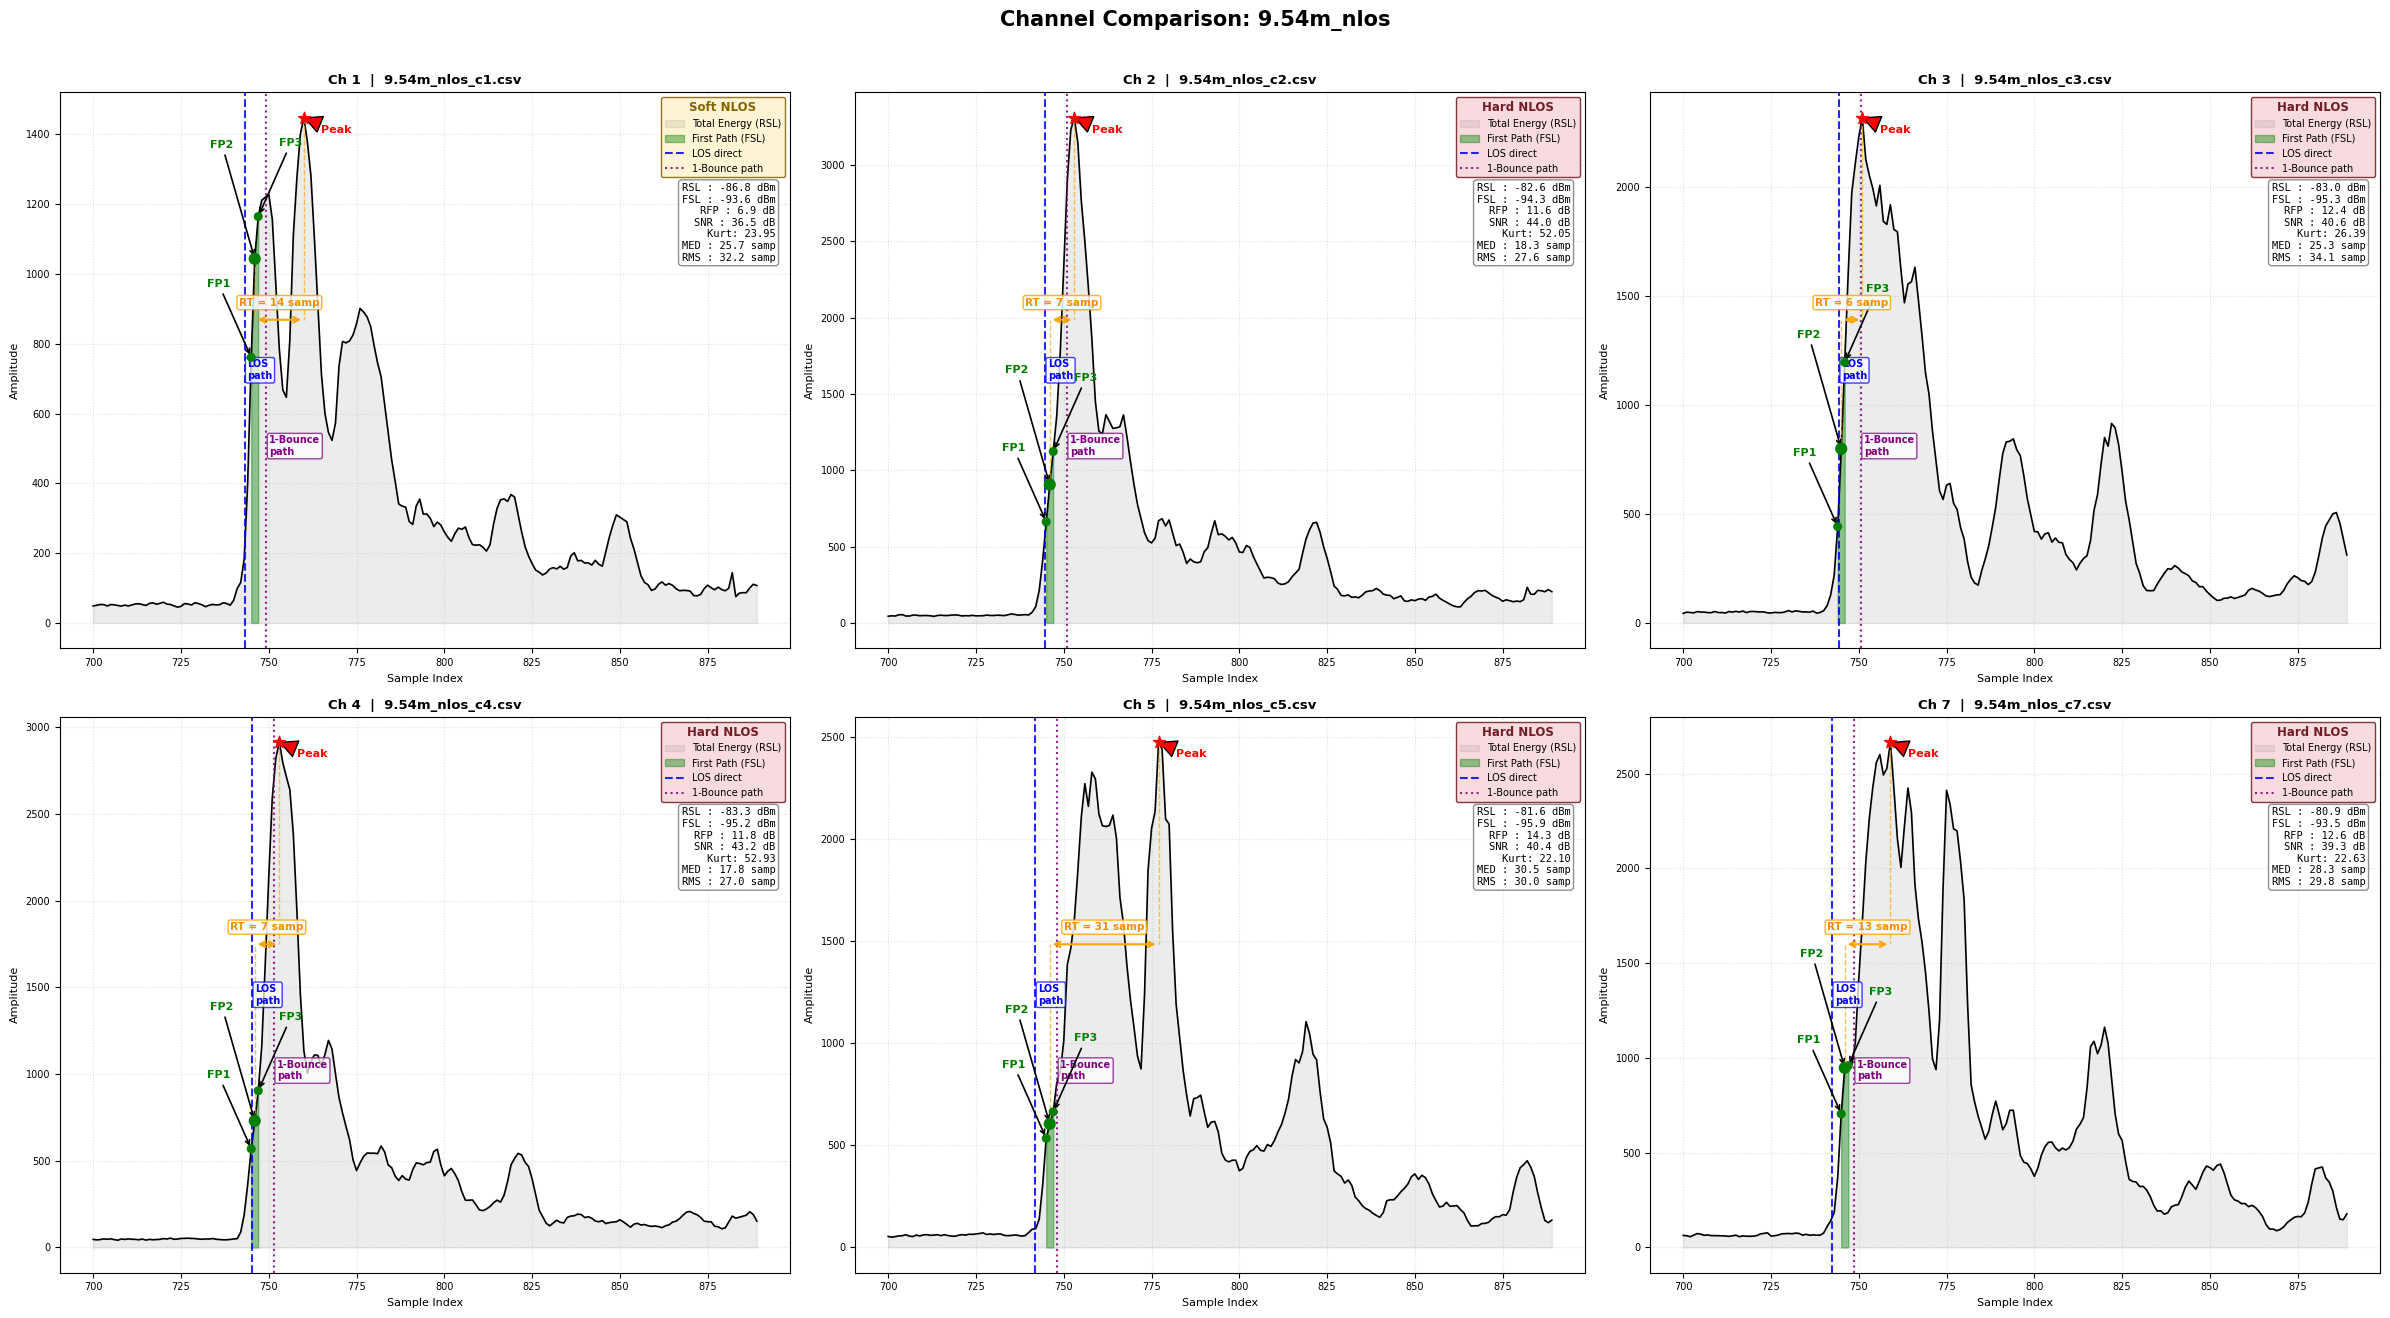

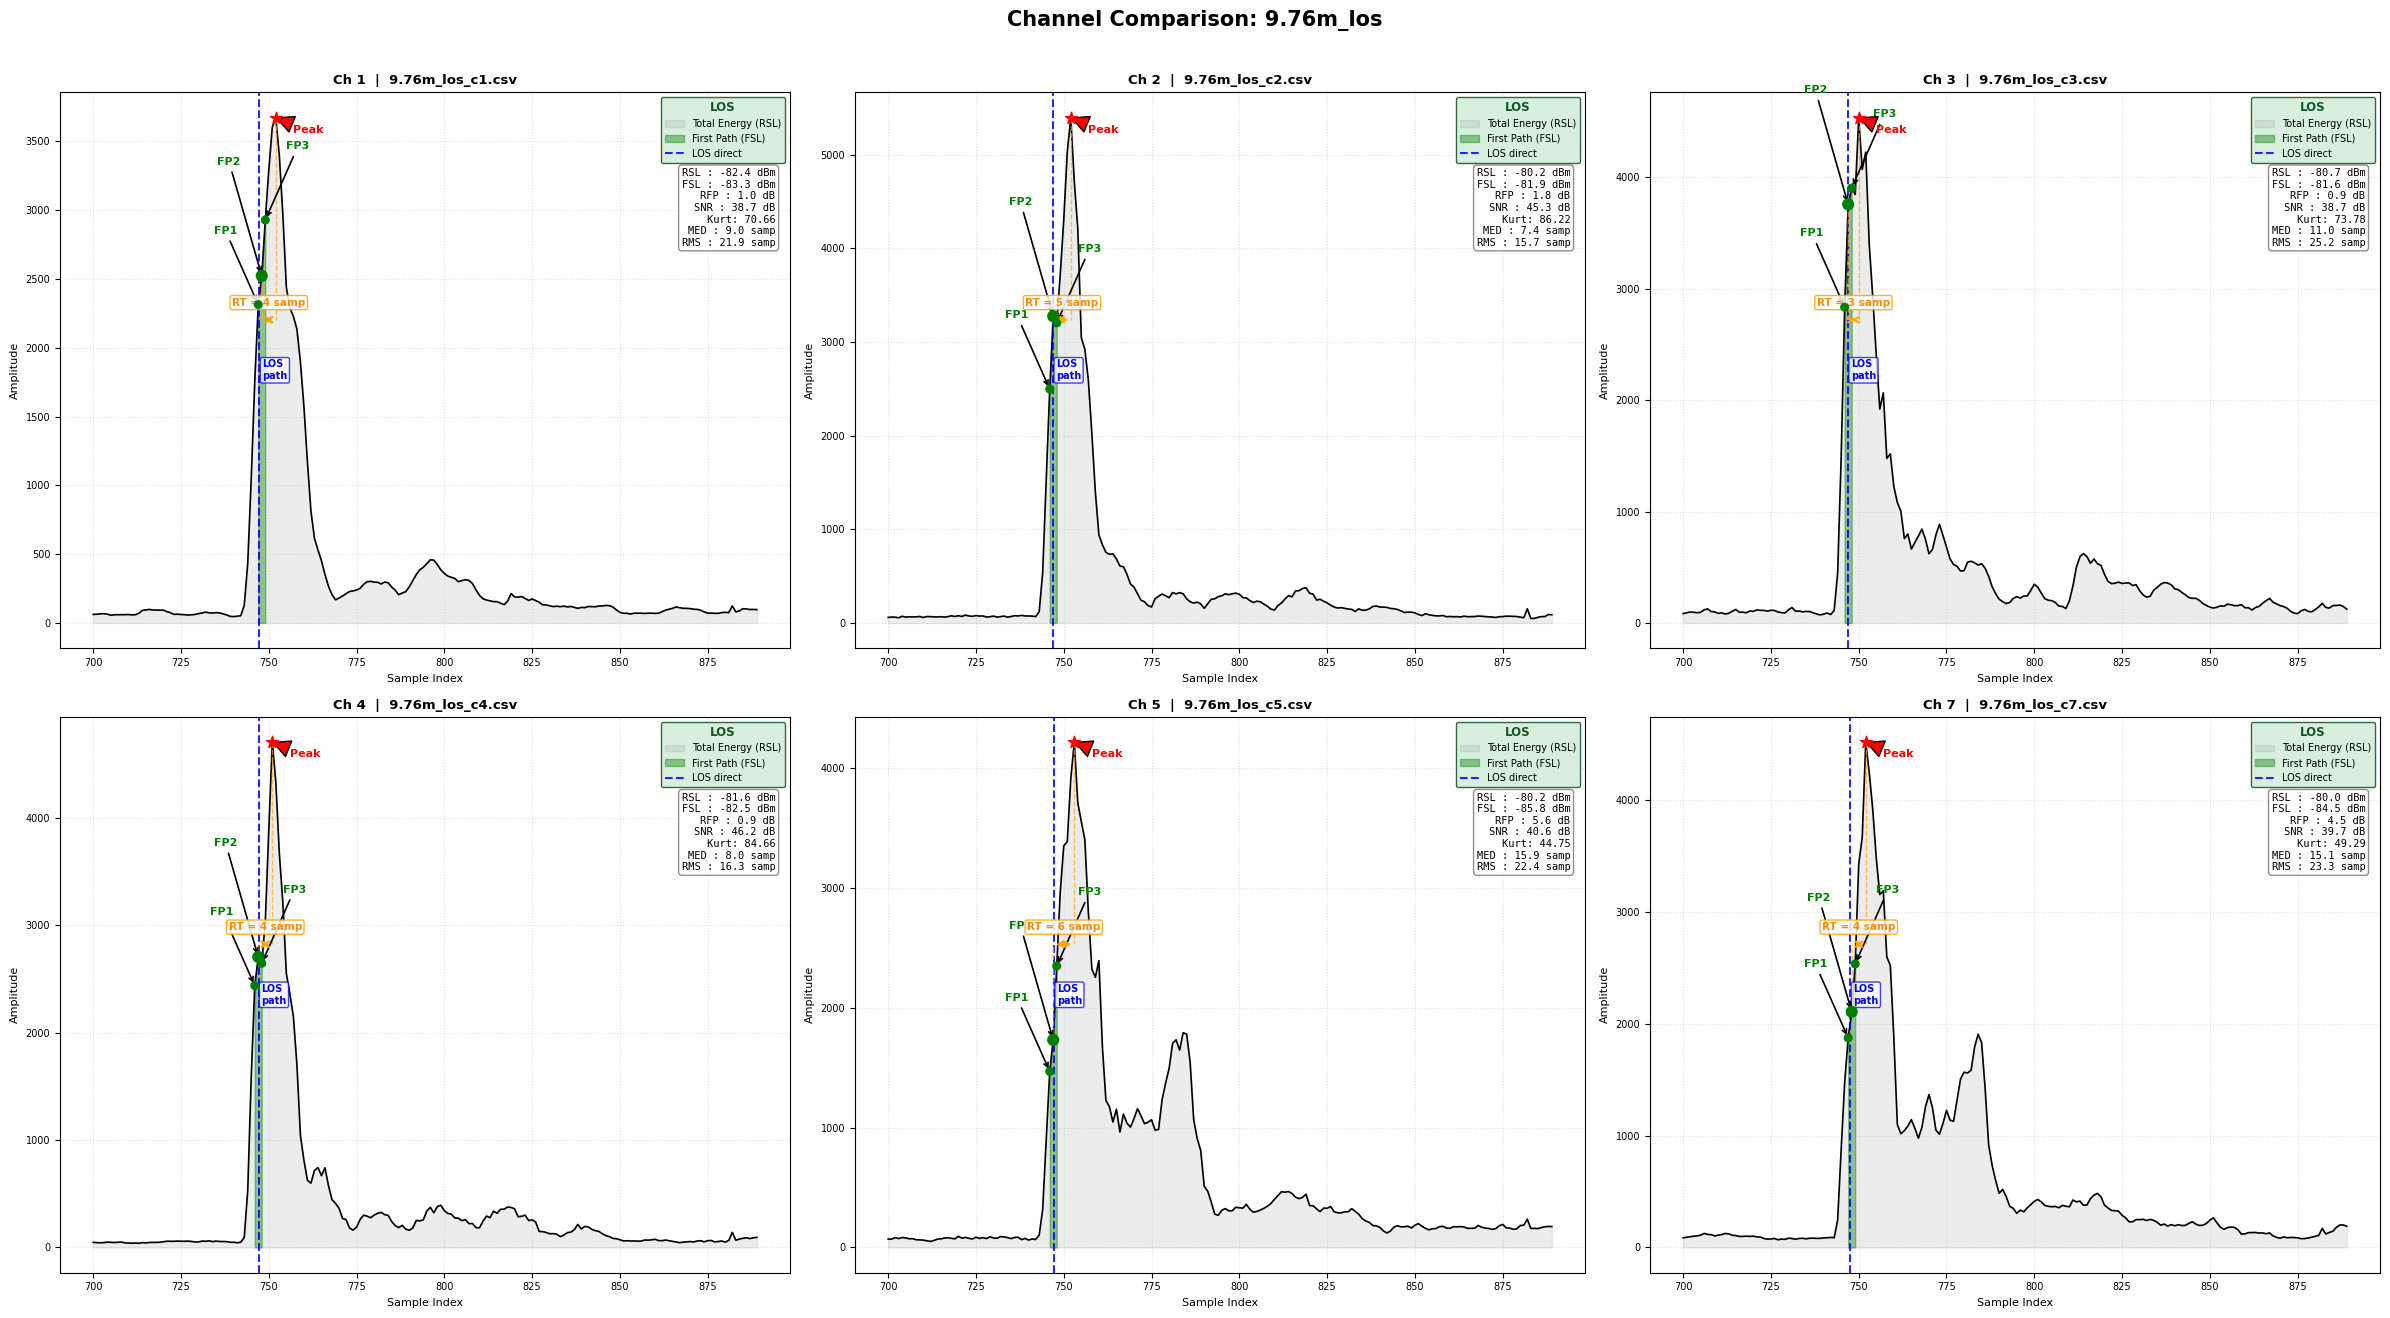

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from scipy.stats import kurtosis
import os
import glob
import re

# Ground-truth lookup
# NLOS files: prefix = d_bounce; d_direct computed geometrically from floor plan
# LOS  files: prefix = d_direct; no bounce
NLOS_GT = {
    '12.79m_nlos': {'d_direct': 8.81887, 'd_bounce': 12.79},
    '16.09m_nlos': {'d_direct': 7.20139, 'd_bounce': 16.09},
    '16.80m_nlos': {'d_direct': 13.05986, 'd_bounce': 16.80},
    '9.54m_nlos':  {'d_direct': 7.668,    'd_bounce': 9.54},
    '8.91m_nlos': {'d_direct': 6.1,      'd_bounce': 8.91},
}
METERS_PER_INDEX = 0.3002  # c x 1.0016 ns

def get_ground_truth(scenario_name):
    """Return (d_direct, d_bounce_or_None) for a scenario."""
    if scenario_name in NLOS_GT:
        gt = NLOS_GT[scenario_name]
        return gt['d_direct'], gt['d_bounce']
    m = re.match(r'^([\d.]+)m_los', scenario_name)
    if m:
        return float(m.group(1)), None
    return None, None

# Metric calculation
def analyze_hardware_dataset(filepath):
    try:
        df = pd.read_csv(filepath)
        cir_cols = sorted([c for c in df.columns if c.startswith('CIR')], key=lambda x: int(x.replace('CIR', '')))
        if not cir_cols: return None 

        raw_waves = df[cir_cols].values 
        avg_wave = np.mean(raw_waves, axis=0)
        
        A = 121.74 
        if 'RXPACC' in df.columns: N = df['RXPACC'].mean()
        elif 'RXP_ACC' in df.columns: N = df['RXP_ACC'].mean()
        else: N = 128.0 

        raw_sum_squares = np.sum(avg_wave**2)
        if 'CIR_PWR' in df.columns: C = df['CIR_PWR'].mean()
        else: C = raw_sum_squares / (2**17) 
        safe_C = max(C, 1e-9)
        RSL = 10 * np.log10( (safe_C * (2**17)) / (N**2) ) - A

        # Float FP index (for path labeling formula)
        fp_idx_float = df['FP_INDEX'].mean() / 64.0
        hw_fp_idx    = int(fp_idx_float)
        idx_f1 = max(0, hw_fp_idx - 1)
        idx_f2 = hw_fp_idx
        idx_f3 = min(len(avg_wave)-1, hw_fp_idx + 1)
        
        plot_F1 = avg_wave[idx_f1]
        plot_F2 = avg_wave[idx_f2]
        plot_F3 = avg_wave[idx_f3]
        
        if 'FP_AMPL1' in df.columns:
            math_F1, math_F2, math_F3 = df['FP_AMPL1'].mean(), df['FP_AMPL2'].mean(), df['FP_AMPL3'].mean()
        else:
            math_F1, math_F2, math_F3 = plot_F1, plot_F2, plot_F3

        F_sum = (math_F1**2) + (math_F2**2) + (math_F3**2)
        safe_F = max(F_sum, 1e-9)
        FSL = 10 * np.log10( safe_F / (N**2) ) - A

        if 'STD_NOISE' in df.columns: std_noise = df['STD_NOISE'].mean()
        else: std_noise = np.std(avg_wave[0:30])
        max_amp = np.max(avg_wave)
        SNR = 20 * np.log10(max_amp / (std_noise + 1e-9))

        kurt_val = kurtosis(avg_wave)
        fp_energy_raw = math_F1**2 + math_F2**2 + math_F3**2
        total_energy_raw = np.sum(avg_wave**2)
        power_ratio = fp_energy_raw / max(total_energy_raw, 1e-9)
        
        pdp = avg_wave[hw_fp_idx:]**2
        times = np.arange(len(pdp))
        total_pdp_pwr = np.sum(pdp) + 1e-9
        mean_excess_delay = np.sum(pdp * times) / total_pdp_pwr
        second_moment = np.sum(pdp * (times**2)) / total_pdp_pwr
        rms_delay_spread = np.sqrt(max(0, second_moment - (mean_excess_delay**2)))
        
        RFP = RSL - FSL
        if RFP < 6.0: condition = "LOS"
        elif RFP <= 10.0: condition = "Soft NLOS"
        else: condition = "Hard NLOS"
        
        peak_idx = np.argmax(avg_wave)
        rise_time = peak_idx - hw_fp_idx

        # Mean reported distance (needed for FP-anchored path formula)
        mean_distance = df['Distance'].mean() if 'Distance' in df.columns else None

        return {
            "Filename": os.path.basename(filepath),
            "Avg_Wave": avg_wave,
            "HW_FP_Index": hw_fp_idx,
            "FP_Idx_Float": fp_idx_float,
            "Mean_Distance": mean_distance,
            "Indices": (idx_f1, idx_f2, idx_f3, peak_idx),
            "Plot_Amps": (plot_F1, plot_F2, plot_F3),
            "Max_Amp": max_amp,
            "RSL_dBm": RSL,
            "FSL_dBm": FSL,
            "RFP_Metric": RFP,
            "SNR_dB": SNR,
            "Kurtosis": kurt_val,
            "Power_Ratio": power_ratio,
            "Total_Energy": total_energy_raw,
            "Rise_Time": rise_time,
            "Mean_Excess_Delay": mean_excess_delay,
            "RMS_Delay_Spread": rms_delay_spread,
            "Condition": condition
        }
    except Exception as e: return None

# 2x3 grid, one subplot per channel
def plot_final_standard_labels(scenario_prefix):
    files = sorted(glob.glob(f"{scenario_prefix}_c*.csv"))
    if not files: return

    all_data = [d for d in (analyze_hardware_dataset(f) for f in files) if d]
    if not all_data: return

    scenario_name = os.path.basename(scenario_prefix)
    d_direct, d_bounce = get_ground_truth(scenario_name)

    fig, axes = plt.subplots(2, 3, figsize=(24, 13))
    fig.suptitle(f"Channel Comparison: {scenario_name}", fontsize=15, fontweight='bold', y=1.01)
    axes = axes.flatten()

    subplot_refs = []  # (ax, legend, metrics_str)

    for i, data in enumerate(all_data):
        ax = axes[i]
        avg_wave = data['Avg_Wave']
        hw_fp    = data['HW_FP_Index']
        fp_float = data['FP_Idx_Float']
        mean_dist = data['Mean_Distance']
        idx_f1, idx_f2, idx_f3, peak_idx = data['Indices']
        f1, f2, f3 = data['Plot_Amps']
        max_amp  = data['Max_Amp']

        start = 700
        end    = min(len(avg_wave), 890)
        x_zoom = np.arange(start, end)
        y_zoom = avg_wave[start:end]

        # Waveform
        ax.fill_between(x_zoom, 0, y_zoom, color='gray', alpha=0.15, label='Total Energy (RSL)')
        ax.fill_between([idx_f1, idx_f2, idx_f3], 0, [f1, f2, f3], color='green', alpha=0.4, label='First Path (FSL)')
        ax.plot(x_zoom, y_zoom, color='black', linewidth=1.2)

        # Ground-truth path markers
        if d_direct is not None and mean_dist is not None:
            los_idx = fp_float + (d_direct - mean_dist) / METERS_PER_INDEX
            ax.axvline(los_idx, color='blue', linestyle='--', lw=1.5, alpha=0.85, label='LOS direct')
            ax.text(los_idx + 0.8, max_amp * 0.50, 'LOS\npath',
                    color='blue', fontsize=7, fontweight='bold', va='center',
                    bbox=dict(facecolor='white', edgecolor='blue', alpha=0.75,
                              boxstyle='round,pad=0.2'))

        if d_bounce is not None and mean_dist is not None:
            bounce_idx = fp_float + (d_bounce - mean_dist) / METERS_PER_INDEX
            ax.axvline(bounce_idx, color='purple', linestyle=':', lw=1.5, alpha=0.85, label='1-Bounce path')
            ax.text(bounce_idx + 0.8, max_amp * 0.35, '1-Bounce\npath',
                    color='purple', fontsize=7, fontweight='bold', va='center',
                    bbox=dict(facecolor='white', edgecolor='purple', alpha=0.75,
                              boxstyle='round,pad=0.2'))

        # FP1 / FP2 / FP3
        ax.scatter([idx_f1, idx_f2, idx_f3], [f1, f2, f3], color='green', s=[30, 60, 30], zorder=5)
        ax.annotate('FP1', xy=(idx_f1, f1),
                    xytext=(idx_f1 - 6, f1 + max_amp * 0.14),
                    arrowprops=dict(facecolor='green', arrowstyle='->', lw=1.2),
                    fontsize=8, color='green', fontweight='bold', ha='right')
        ax.annotate('FP2', xy=(idx_f2, f2),
                    xytext=(idx_f2 - 6, f2 + max_amp * 0.22),
                    arrowprops=dict(facecolor='green', arrowstyle='->', lw=1.2),
                    fontsize=8, color='green', fontweight='bold', ha='right')
        ax.annotate('FP3', xy=(idx_f3, f3),
                    xytext=(idx_f3 + 6, f3 + max_amp * 0.14),
                    arrowprops=dict(facecolor='green', arrowstyle='->', lw=1.2),
                    fontsize=8, color='green', fontweight='bold', ha='left')

        # Max peak
        ax.scatter(peak_idx, max_amp, color='red', s=80, marker='*', zorder=5)
        ax.annotate('Peak', xy=(peak_idx, max_amp),
                    xytext=(peak_idx + 5, max_amp * 0.97),
                    arrowprops=dict(facecolor='red', shrink=0.05),
                    fontsize=8, color='red', fontweight='bold')

        # Rise-time bracket
        dim_y = max_amp * 0.60
        ax.plot([hw_fp, hw_fp],       [f2, dim_y],     color='orange', linestyle='--', alpha=0.7, lw=1)
        ax.plot([peak_idx, peak_idx], [max_amp, dim_y], color='orange', linestyle='--', alpha=0.7, lw=1)
        ax.annotate('', xy=(hw_fp, dim_y), xytext=(peak_idx, dim_y),
                    arrowprops=dict(arrowstyle='<->', color='orange', lw=1.5))
        mid_x = (hw_fp + peak_idx) / 2
        ax.text(mid_x, dim_y * 1.04, f"RT = {data['Rise_Time']} samp",
                color='darkorange', fontsize=7.5, ha='center', va='bottom', fontweight='bold',
                bbox=dict(facecolor='white', edgecolor='orange', boxstyle='round,pad=0.2', alpha=0.85))

        # Condition legend (top-right)
        cond     = data['Condition']
        badge_fc = '#d4edda' if cond == 'LOS' else ('#fff3cd' if 'Soft' in cond else '#f8d7da')
        badge_ec = '#155724' if cond == 'LOS' else ('#856404' if 'Soft' in cond else '#721c24')

        leg = ax.legend(fontsize=7, loc='upper right', framealpha=0.88,
                        title=cond, title_fontsize=8.5,
                        facecolor=badge_fc, edgecolor=badge_ec)
        leg.get_title().set_color(badge_ec)
        leg.get_title().set_fontweight('bold')

        ch_match = re.search(r'_c(\d+)\.csv$', data['Filename'], re.IGNORECASE)
        ch_label = f"Ch {ch_match.group(1)}" if ch_match else data['Filename']
        ax.set_title(f"{ch_label}  |  {data['Filename']}", fontsize=9.5, fontweight='bold')
        ax.set_xlabel("Sample Index", fontsize=8)
        ax.set_ylabel("Amplitude",    fontsize=8)
        ax.tick_params(labelsize=7)
        ax.grid(True, linestyle=':', alpha=0.4)

        metrics_str = (
            f"RSL : {data['RSL_dBm']:.1f} dBm\n"
            f"FSL : {data['FSL_dBm']:.1f} dBm\n"
            f"RFP : {data['RFP_Metric']:.1f} dB\n"
            f"SNR : {data['SNR_dB']:.1f} dB\n"
            f"Kurt: {data['Kurtosis']:.2f}\n"
            f"MED : {data['Mean_Excess_Delay']:.1f} samp\n"
            f"RMS : {data['RMS_Delay_Spread']:.1f} samp"
        )
        subplot_refs.append((ax, leg, metrics_str))

    for j in range(len(all_data), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()

    # Second pass: place the metrics boxes just below each legend
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    for ax, leg, metrics_str in subplot_refs:
        leg_bb = leg.get_window_extent(renderer=renderer)
        ax_bb  = ax.get_window_extent(renderer=renderer)
        leg_bottom_frac = (leg_bb.y0 - ax_bb.y0) / ax_bb.height
        ax.text(0.98, leg_bottom_frac - 0.01, metrics_str, transform=ax.transAxes,
                fontsize=7.5, family='monospace', va='top', ha='right',
                bbox=dict(facecolor='white', edgecolor='gray', alpha=0.88, boxstyle='round,pad=0.3'))

    plt.show()

# Run on every scenario in dataset/channels/
all_csvs = glob.glob(os.path.join(CHANNEL_DIR, "*.csv"))
scenarios = sorted(list(set([re.sub(r'_c\d+\.csv$', '', f) for f in all_csvs if "_c" in f])))
for s in scenarios:
    plot_final_standard_labels(s)


### 2.2 Notes on the Individual Waveforms

One CIR sample is one chip period of 1.0016 ns, so it covers c x 1.0016 ns = 0.3003 m (d_sample in Eq. 1 of the paper); the path indices in this notebook use 0.3002 m, which changes an index by less than 0.01 samples over these distances. `fp_idx = FP_INDEX / 64` is the CIR index that belongs to the reported distance d_hardware (`Distance`), so a path of length d arrives at

$$\mathrm{path\_idx} = \mathrm{fp\_idx} + \frac{d - d_{\mathrm{hardware}}}{0.3002}$$

Anchoring on the first path cancels the window shift of the DW1000, which changes from one capture to the next. Each plot is a 2x3 grid, one subplot per channel, with the mean of the 100 captures and three markers:
- green fill, FP1 to FP3: the three first-path amplitude samples of the DW1000
- blue dashed: the direct path `los_path_idx`, with d = d_direct (laser-measured for LOS, from the floor plan for NLOS)
- purple dotted: the single-bounce path `bounce_path_idx`, with d = d_bounce (NLOS only)

The ranging error of an NLOS capture is `Distance - d_direct`. When the first path locks onto the bounce it approaches `d_bounce - d_direct`, the extra length of the reflected path. In the 12.79 m scenario, for example, five channels report 12.1 to 12.8 m against a direct path of 8.82 m.

| Scenario | TX -> reflector -> RX (m) | d_direct (m) | Bounce after the direct path |
|---|---|---|---|
| 12.79 m | 5.00 + 7.79 | 8.82 | 13.2 samples |
| 16.09 m | 5.32 + 10.77 | 7.20 | 29.6 samples |
| 16.80 m | 2.80 + 14.00 | 13.06 | 12.5 samples |
| 9.54 m | - | 7.67 | 6.2 samples |
| 8.91 m | - | 6.10 | 9.4 samples |

In LOS the pulse is sharp and short, most of the energy sits at FP1 to FP3 and the blue marker lands near FP2, which also confirms the antenna delay calibration. In NLOS the pulse is broader and the tail longer, and the first path either stays near the direct path or locks onto the bounce (section 2.3).

## 2.3 FP_INDEX Check

The DW1000 reports three amplitude samples, FP_AMPL1 to FP_AMPL3, around its detected first path (`FP_INDEX / 64`), and RSL, FSL and RFP are computed from them. The offset between the hardware first path and the true direct path (`fp_to_los_offset`) shows whether these samples describe the direct path or a reflection:

$$
\begin{aligned}
\mathrm{offset} &= \mathrm{fp\_idx} - \mathrm{los\_path\_idx} \\[4pt]
&= \frac{d_{\mathrm{hardware}} - d_{\mathrm{direct}}}{0.3002}
\end{aligned}
$$

An offset near 0 means the hardware locked onto the direct path; a large positive offset means it locked onto a later path.

Loaded 3600 rows, 1016 CIR columns


Appended 2400 new rows from 24 files
Total: 6000 rows



Per-scenario summary
los_path_idx = FP_INDEX/64 + (d_direct - Distance) / 0.3002

Source Pattern         | Cond  | d_direct | d_bounce |  <los_idx> | <bounce_idx> |  <fp_idx> |  <fp-los> |  <peak>
------------------------------------------------------------------------------------------------------------------
4.55m_los_c*           | LOS   |     4.55 |      N/A |     747.53 |          N/A |    747.89 |     +0.36 |   750.4
8.91m_nlos_c*          | NLOS  |     6.10 |     8.91 |     740.88 |       750.24 |    742.24 |     +1.36 |   768.2
16.09m_nlos_c*         | NLOS  |     7.20 |    16.09 |     737.30 |       766.90 |    743.14 |     +5.85 |   770.2
9.54m_nlos_c*          | NLOS  |     7.67 |     9.54 |     743.63 |       749.86 |    746.48 |     +2.85 |   760.3
8.41m_los_c*           | LOS   |     8.41 |      N/A |     748.04 |          N/A |    748.06 |     +0.03 |   750.2
12.79m_nlos_c*         | NLOS  |     8.82 |    12.79 |     734.80 |       748.03 |    744.52 |     +9.72 |   748

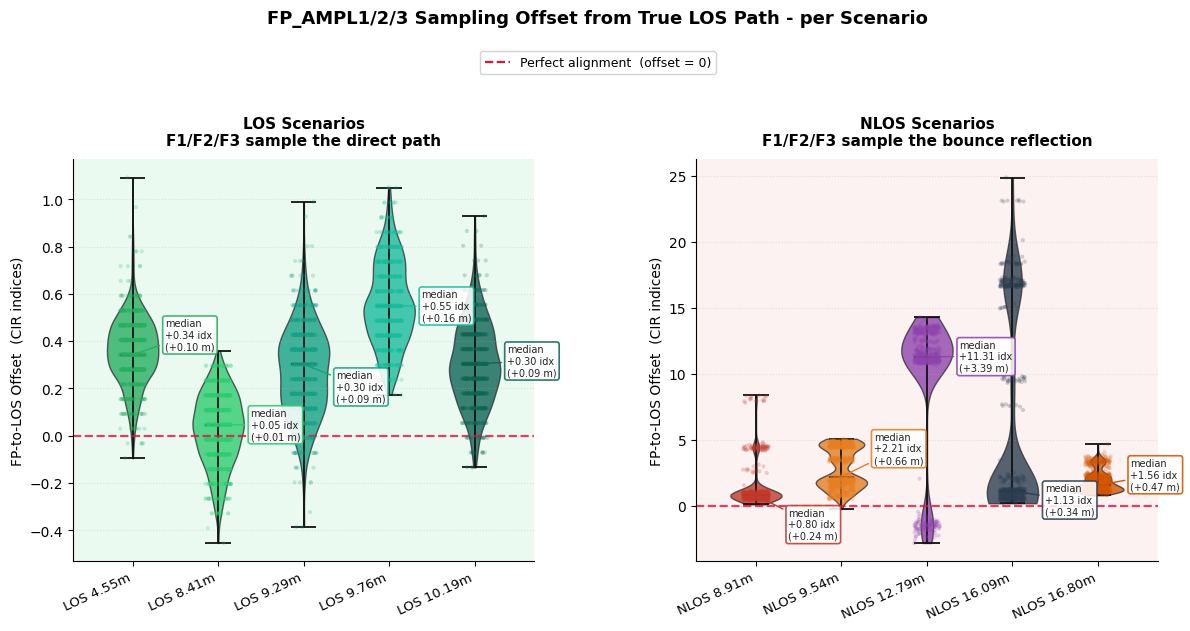


Columns added to df_combined:
  d_direct, d_bounce, fp_idx, los_path_idx, bounce_path_idx,
  fp_to_los_offset, peak_idx, channel, cir_at_los_path


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import os
import re

DIST_PER_CIR_INDEX = 0.3002  # metres per CIR sample (c x 1.0016 ns)

# Keys are the filename prefix of each NLOS scenario (d_bounce, laser-measured)
# d_direct = true TX->RX, computed geometrically from floor plan
# 16.80m: d_direct = sqrt(11.60^2 + 6.00^2) = 13.05986 m from the floor plan
NLOS_GROUND_TRUTH = {
    "12.79":  {"d_direct":  8.81887, "d_bounce": 12.79},
    "16.09": {"d_direct":  7.20139, "d_bounce": 16.09},
    "16.80":    {"d_direct": 13.05986,    "d_bounce": 16.80},
    "9.54":     {"d_direct": 7.668,      "d_bounce": 9.54},
    "8.91":    {"d_direct": 6.1,        "d_bounce": 8.91},
}

# Load combined dataset
filepath = os.path.join(CHANNEL_DIR, "combined_uwb_dataset.csv")
df_combined = pd.read_csv(filepath)

cir_cols = sorted(
    [c for c in df_combined.columns if c.startswith('CIR')],
    key=lambda x: int(x.replace('CIR', ''))
)

for col in ['d_direct', 'd_bounce', 'los_path_idx', 'bounce_path_idx',
            'fp_idx', 'fp_to_los_offset', 'peak_idx', 'channel', 'cir_at_los_path']:
    if col in df_combined.columns:
        df_combined.drop(columns=[col], inplace=True)

print(f"Loaded {len(df_combined)} rows, {len(cir_cols)} CIR columns")

# Append new channel files not yet in combined CSV
import glob
existing_files = set(df_combined["Source_File"].unique())
new_rows = []
for csv_path in sorted([f for f in glob.glob(os.path.join(CHANNEL_DIR, "*m_*_c*.csv")) if re.search(r"\d+\.?\d*m_(los|nlos)_c\d+\.csv$", f)]):
    fname = os.path.basename(csv_path)
    if fname in existing_files or fname == "combined_uwb_dataset.csv":
        continue
    tmp = pd.read_csv(csv_path)
    tmp["Source_File"] = fname
    tmp["Label"] = 1 if "_nlos_" in fname else 0
    new_rows.append(tmp)
if new_rows:
    df_new = pd.concat(new_rows, ignore_index=True)
    df_combined = pd.concat([df_combined, df_new], ignore_index=True)
    print(f"Appended {len(df_new)} new rows from {len(new_rows)} files")
    print(f"Total: {len(df_combined)} rows")

# Parse Source_File -> d_direct, d_bounce
d_direct_list, d_bounce_list = [], []
for _, row in df_combined.iterrows():
    fname = str(row['Source_File'])
    m = re.match(r'^([\d.]+)m', fname)
    if not m:
        d_direct_list.append(np.nan); d_bounce_list.append(np.nan); continue
    prefix = m.group(1)
    if '_nlos_' in fname:
        gt = NLOS_GROUND_TRUTH.get(prefix)
        if gt:
            d_direct_list.append(gt['d_direct']); d_bounce_list.append(gt['d_bounce'])
        else:
            d_direct_list.append(np.nan); d_bounce_list.append(np.nan)
    else:
        d_direct_list.append(float(prefix)); d_bounce_list.append(np.nan)

df_combined['d_direct'] = d_direct_list
df_combined['d_bounce'] = d_bounce_list

# FP-anchored path indices
# fp_to_los_offset ~ 0 for LOS; > 0 for NLOS (HW locked onto bounce, not LOS)
df_combined['fp_idx'] = df_combined['FP_INDEX'] / 64.0
df_combined['los_path_idx'] = (
    df_combined['fp_idx']
    + (df_combined['d_direct'] - df_combined['Distance']) / DIST_PER_CIR_INDEX
)
df_combined['bounce_path_idx'] = (
    df_combined['fp_idx']
    + (df_combined['d_bounce'] - df_combined['Distance']) / DIST_PER_CIR_INDEX
)
df_combined['fp_to_los_offset'] = df_combined['fp_idx'] - df_combined['los_path_idx']

cir_matrix = df_combined[cir_cols].values.astype(float)
df_combined['peak_idx'] = np.argmax(cir_matrix, axis=1)
df_combined['channel'] = df_combined['Source_File'].apply(
    lambda x: int(re.search(r'_c(\d+)\.csv', str(x)).group(1))
    if re.search(r'_c(\d+)\.csv', str(x)) else None
)

los_int_idx = df_combined['los_path_idx'].round().astype(int).clip(0, len(cir_cols) - 1)
df_combined['cir_at_los_path'] = cir_matrix[np.arange(len(df_combined)), los_int_idx.values]

# Summary table
header = ("Per-scenario summary\n"
          "los_path_idx = FP_INDEX/64 + (d_direct - Distance) / 0.3002\n")
print(f"\n{header}")
cols = ["Source Pattern", "Cond", "d_direct", "d_bounce",
        "<los_idx>", "<bounce_idx>", "<fp_idx>", "<fp-los>", "<peak>"]
widths = [22, 5, 8, 8, 10, 12, 9, 9, 7]
header_line = " | ".join(f"{c:>{w}}" if i > 1 else f"{c:<{w}}" for i, (c, w) in enumerate(zip(cols, widths)))
print(header_line)
print("-" * len(header_line))

rows_data = []
for (d_dir, label), grp in df_combined.groupby(['d_direct', 'Label'], sort=True):
    cond = 'NLOS' if label == 1 else 'LOS'
    d_bnc = grp['d_bounce'].iloc[0]
    is_nlos = not np.isnan(d_bnc)
    pattern = grp['Source_File'].iloc[0].rsplit('_c', 1)[0] + '_c*'
    row = [
        f"{pattern:<22}",
        f"{cond:<5}",
        f"{d_dir:>8.2f}",
        f"{d_bnc:>8.2f}" if is_nlos else f"{'N/A':>8}",
        f"{grp['los_path_idx'].mean():>10.2f}",
        f"{grp['bounce_path_idx'].mean():>12.2f}" if is_nlos else f"{'N/A':>12}",
        f"{grp['fp_idx'].mean():>9.2f}",
        f"{grp['fp_to_los_offset'].mean():>+9.2f}",
        f"{grp['peak_idx'].mean():>7.1f}",
    ]
    rows_data.append(row)

for row in rows_data:
    print(" | ".join(row))

# First-path offset and FP_AMPL2 check
print(f"\n\nOffset between the hardware first path and the direct path\n")
for cond_label, cond_name in [(0, 'LOS'), (1, 'NLOS')]:
    subset = df_combined[df_combined['Label'] == cond_label]
    offsets = subset['fp_to_los_offset'].abs()
    n = len(subset)
    print(f"  {cond_name} (n={n}):")
    print(f"    Mean |offset| = {offsets.mean():.2f} idx  ({offsets.mean()*DIST_PER_CIR_INDEX:.2f} m)")
    for t in [1, 2, 3, 5, 10]:
        count = (offsets <= t).sum()
        pct = 100 * count / n
        print(f"    |offset| <= {t:>2} idx ({t*DIST_PER_CIR_INDEX:.2f} m):  {count:>5}/{n}  ({pct:.1f}%)")
    print()

print(f"FP_AMPL2 vs CIR amplitude at true LOS path\n")
for cond_label, cond_name in [(0, 'LOS'), (1, 'NLOS')]:
    sub = df_combined[df_combined['Label'] == cond_label]
    ratio = sub['cir_at_los_path'].mean() / sub['FP_AMPL2'].mean()
    print(f"  {cond_name}: FP_AMPL2 = {sub['FP_AMPL2'].mean():.1f}  "
          f"CIR@LOS = {sub['cir_at_los_path'].mean():.1f}  ratio = {ratio:.3f}")

# Violin: split LOS / NLOS panels so each y-axis is legible
# LOS  label -> d_direct (= TX->RX, matches filename prefix)
# NLOS label -> d_bounce (= total bounce path, matches filename prefix e.g. 12.79m_nlos)
scenario_key = df_combined.apply(
    lambda r: (
        f"NLOS {r['d_bounce']:.2f}m" if r['Label'] == 1
        else f"LOS {r['d_direct']:.2f}m"
    ),
    axis=1
)
unique_scenarios = sorted(
    scenario_key.unique(),
    key=lambda s: (0 if s.startswith('LOS') else 1, float(s.split()[1].rstrip('m')))
)
los_scenarios  = [s for s in unique_scenarios if s.startswith('LOS')]
nlos_scenarios = [s for s in unique_scenarios if s.startswith('NLOS')]

LOS_PALETTE  = ['#27ae60', '#2ecc71', '#16a085', '#1abc9c', '#0e6655']
NLOS_PALETTE = ['#c0392b', '#e67e22', '#8e44ad', '#2c3e50', '#d35400']

rng = np.random.default_rng(42)

def draw_violin_panel(ax, scenarios, palette, bg_color, panel_title):
    vdata = [df_combined.loc[scenario_key == sc, 'fp_to_los_offset'].values
             for sc in scenarios]

    parts = ax.violinplot(vdata, positions=range(len(scenarios)),
                          showmedians=True, showextrema=True, widths=0.6)
    for body, color in zip(parts['bodies'], palette):
        body.set_facecolor(color)
        body.set_edgecolor('#333')
        body.set_alpha(0.80)
    for part_name in ('cmedians', 'cmins', 'cmaxes', 'cbars'):
        parts[part_name].set_color('#111')
        parts[part_name].set_linewidth(1.3)

    # Jitter overlay to show the density
    for i, (sc, color) in enumerate(zip(scenarios, palette)):
        vals = df_combined.loc[scenario_key == sc, 'fp_to_los_offset'].values
        jitter = rng.uniform(-0.15, 0.15, size=len(vals))
        ax.scatter(i + jitter, vals, s=9, alpha=0.22, color=color,
                   edgecolors='none', zorder=3)

    # Median labels, spread out vertically so they don't overlap
    medians = [np.median(df_combined.loc[scenario_key == sc, 'fp_to_los_offset'].values)
               for sc in scenarios]
    # Compute adjusted y-positions: push apart labels that are too close
    y_range = max(max(v) - min(v) for v in vdata if len(v) > 0)
    min_gap = y_range * 0.08  # minimum vertical gap between annotation centers
    adjusted_y = list(medians)
    # Sort by median value, then push apart overlapping pairs
    order = sorted(range(len(adjusted_y)), key=lambda k: adjusted_y[k])
    for pass_num in range(5):
        for j in range(1, len(order)):
            a, b = order[j - 1], order[j]
            gap = adjusted_y[b] - adjusted_y[a]
            if gap < min_gap:
                shift = (min_gap - gap) / 2
                adjusted_y[a] -= shift
                adjusted_y[b] += shift

    for i, (sc, color) in enumerate(zip(scenarios, palette)):
        med = medians[i]
        ax.annotate(
            f'median\n{med:+.2f} idx\n({med*DIST_PER_CIR_INDEX:+.2f} m)',
            xy=(i, med), xytext=(i + 0.38, adjusted_y[i]),
            fontsize=7, color='#222', va='center', ha='left',
            bbox=dict(facecolor='white', edgecolor=color, boxstyle='round,pad=0.25',
                      alpha=0.88, linewidth=1.2),
            arrowprops=dict(arrowstyle='-', color=color, lw=1.0)
        )

    ax.axhline(0, color='crimson', ls='--', lw=1.6, alpha=0.8, zorder=2)
    ax.set_facecolor(bg_color)
    ax.set_xticks(range(len(scenarios)))
    ax.set_xticklabels(scenarios, rotation=25, ha='right', fontsize=9.5)
    ax.set_ylabel("FP-to-LOS Offset  (CIR indices)", fontsize=10)
    ax.set_title(panel_title, fontweight='bold', fontsize=11, pad=10)
    ax.grid(True, alpha=0.3, axis='y', linestyle=':')
    ax.set_xlim(-0.7, len(scenarios) - 0.3)
    ax.spines[['top', 'right']].set_visible(False)


fig, (ax_los, ax_nlos) = plt.subplots(
    1, 2, figsize=(14, 6),
    gridspec_kw={'width_ratios': [1, 1], 'wspace': 0.35}
)

draw_violin_panel(
    ax_los, los_scenarios, LOS_PALETTE, '#eafaf1',
    'LOS Scenarios\nF1/F2/F3 sample the direct path'
)
draw_violin_panel(
    ax_nlos, nlos_scenarios, NLOS_PALETTE, '#fdf2f2',
    'NLOS Scenarios\nF1/F2/F3 sample the bounce reflection'
)

ref_line = mlines.Line2D([], [], color='crimson', ls='--', lw=1.6,
                         label='Perfect alignment  (offset = 0)')
fig.legend(handles=[ref_line], fontsize=9, loc='upper center',
           bbox_to_anchor=(0.5, 1.01), framealpha=0.85)

fig.suptitle(
    "FP_AMPL1/2/3 Sampling Offset from True LOS Path - per Scenario",
    fontsize=13, fontweight='bold', y=1.07
)
fig.subplots_adjust(top=0.82, bottom=0.15)
plt.show()

print("\nColumns added to df_combined:")
print("  d_direct, d_bounce, fp_idx, los_path_idx, bounce_path_idx,")
print("  fp_to_los_offset, peak_idx, channel, cir_at_los_path")

### 2.3 Notes on the FP_INDEX Check

LOS: the hardware first path matches the direct path closely. Over the five LOS scenarios (3000 samples) the mean |offset| is 0.33 samples (0.10 m), 99.9% of the samples are within 1 sample and all are within 2. The median offset per scenario is between 0.05 and 0.55 samples.

NLOS: the mean |offset| is 4.43 samples (1.33 m), and it depends strongly on the scenario:

| Scenario | Median offset | Bounce after the direct path | First path |
|---|---|---|---|
| 12.79 m | +11.31 samples (+3.39 m) | 13.2 samples (3.97 m) | locks onto the bounce on five of six channels |
| 16.09 m | +1.13 samples (+0.34 m) | 29.6 samples (8.89 m) | near the direct path on C1 to C4; C5 and C7 report 11.3 and 12.5 m |
| 16.80 m | +1.56 samples (+0.47 m) | 12.5 samples (3.74 m) | near the direct path |
| 9.54 m | +2.21 samples (+0.66 m) | 6.2 samples (1.87 m) | closer to the direct path |
| 8.91 m | +0.80 samples (+0.24 m) | 9.4 samples (2.81 m) | near the direct path |

Only 25.7% of the NLOS samples are within 1 sample of the direct path and 77.9% within 10; 500 of the 662 samples further away come from the 12.79 m scenario. The gap between the direct path and the bounce does not decide what happens: the 16.80 m bounce is even closer (12.5 samples) than the 12.79 m bounce, yet the first path stays near the direct path there.

So FP_AMPL1 to FP_AMPL3, and with them RSL, FSL and RFP, describe the direct path in some NLOS captures and the bounce in others. This is why the models learn from the CIR waveform instead of these hardware metrics.

In [7]:
# Export labeled dataset
# Save every scenario with the ground-truth path labels appended. This goes to its own file so
# the provided combined_uwb_dataset.csv (training scenarios only) is not overwritten.
# New columns: d_direct, d_bounce, los_path_idx, bounce_path_idx,
#              fp_idx, fp_to_los_offset, peak_idx, channel, cir_at_los_path

export_path = os.path.join(CHANNEL_DIR, "eda_labeled_export.csv")

# Select column order: original columns first, then new label columns
original_cols = ['Label', 'Source_File', 'Capture_ID', 'Distance',
                 'FP_INDEX', 'FP_AMPL1', 'FP_AMPL2', 'FP_AMPL3',
                 'RXPACC', 'STD_NOISE', 'MAX_NOISE']
new_label_cols = ['d_direct', 'd_bounce', 'los_path_idx', 'bounce_path_idx',
                  'fp_idx', 'fp_to_los_offset', 'peak_idx', 'channel',
                  'cir_at_los_path']

# Build export column order: original metadata + new labels + CIR columns
export_cols = original_cols + new_label_cols + cir_cols

# Verify all columns exist
missing = [c for c in export_cols if c not in df_combined.columns]
if missing:
    print(f"WARNING: Missing columns: {missing}")
else:
    df_combined[export_cols].to_csv(export_path, index=False)
    print(f"Exported labeled dataset to: {export_path}")
    print(f"  Rows:    {len(df_combined)}")
    print(f"  Columns: {len(export_cols)} ({len(original_cols)} original + {len(new_label_cols)} labels + {len(cir_cols)} CIR)")
    print(f"\n  New label columns:")
    for col in new_label_cols:
        non_null = df_combined[col].notna().sum()
        print(f"    {col:<20} {non_null}/{len(df_combined)} non-null values")

Exported labeled dataset to: dataset\channels\eda_labeled_export.csv
  Rows:    6000
  Columns: 1036 (11 original + 9 labels + 1016 CIR)

  New label columns:
    d_direct             6000/6000 non-null values
    d_bounce             3000/6000 non-null values
    los_path_idx         6000/6000 non-null values
    bounce_path_idx      3000/6000 non-null values
    fp_idx               6000/6000 non-null values
    fp_to_los_offset     6000/6000 non-null values
    peak_idx             6000/6000 non-null values
    channel              6000/6000 non-null values
    cir_at_los_path      6000/6000 non-null values


FEATURE DISCRIMINATOR POWER TABLE
Feature              | Fisher (FDR) | ROC AUC    | Correlation 
-------------------------------------------------------------------------------------
FSL_dBm              | 7.0694       | 0.9968     | -0.8829     
Mean_Excess_Delay    | 5.7845       | 0.9982     | 0.8621      
Total_Energy         | 4.6052       | 0.9765     | -0.8350     
RMS_Delay_Spread     | 3.5955       | 0.9970     | 0.8017      
Max_Amplitude        | 3.5294       | 0.9588     | -0.7990     
RSL_dBm              | 2.1019       | 0.9764     | -0.7159     
RFP_Metric           | 2.0598       | 0.9297     | 0.7124      
Power_Ratio          | 1.8718       | 0.9297     | -0.6954     
Rise_Time            | 0.5897       | 0.8022     | 0.4772      
Kurtosis             | 0.0284       | 0.5107     | 0.1184      


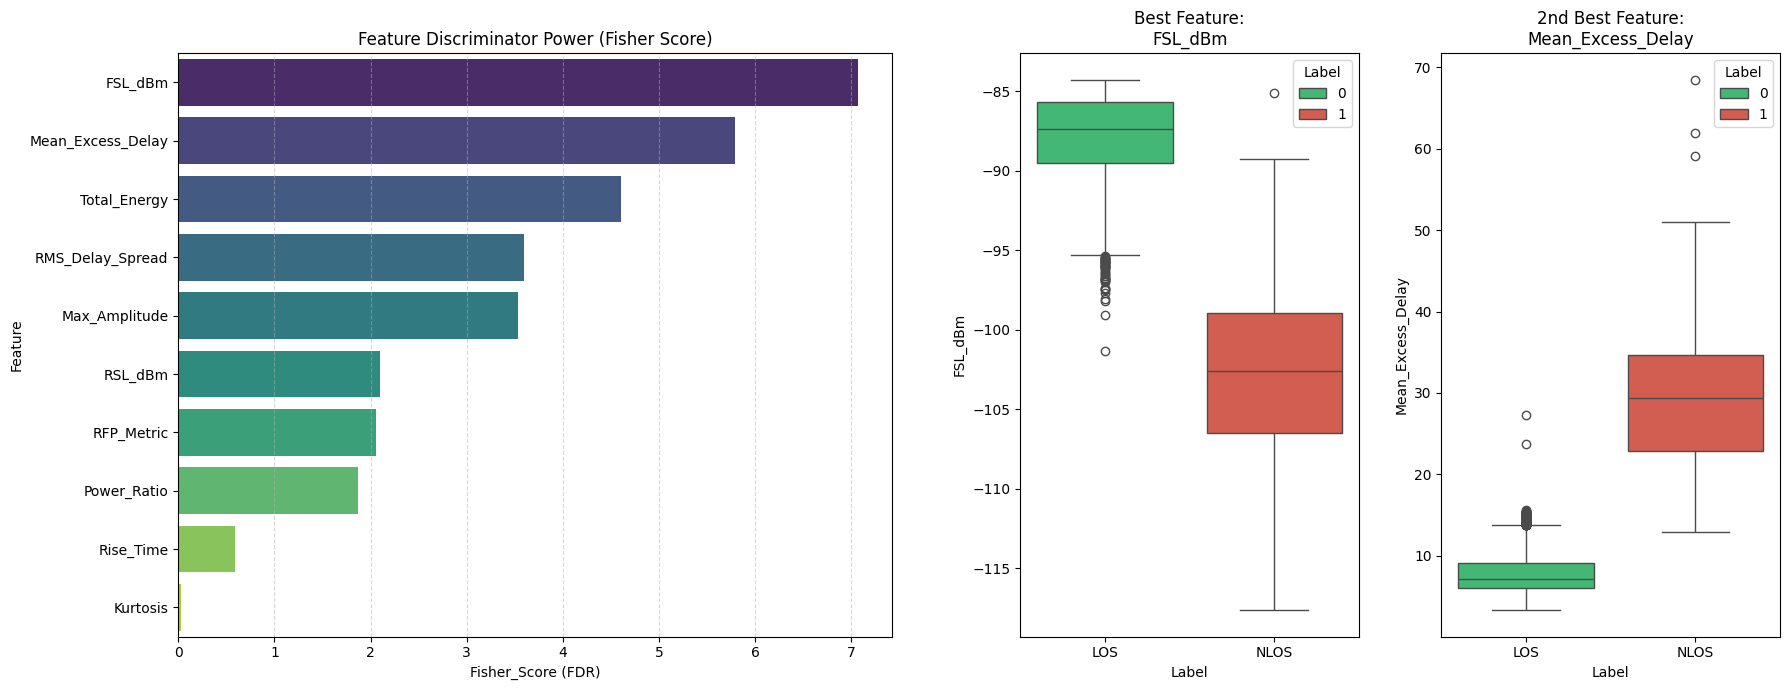

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
from sklearn.metrics import roc_auc_score

# Load the labelled export
filepath = os.path.join(CHANNEL_DIR, "eda_labeled_export.csv")
A = 121.74  # PRF 64 MHz constant for DW1000

try:
    df = pd.read_csv(filepath)
except FileNotFoundError:
    print(f"Error: File not found at {filepath}")
    df = pd.DataFrame() 

cir_cols = sorted([c for c in df.columns if c.startswith('CIR')], key=lambda x: int(x.replace('CIR', '')))

# Feature extraction
data = []

if not df.empty:
    for idx, row in df.iterrows():
        # Preamble accumulation count
        if 'RXPACC' in row: N = float(row['RXPACC'])
        elif 'RXP_ACC' in row: N = float(row['RXP_ACC'])
        else: N = 128.0 
            
        sig = pd.to_numeric(row[cir_cols], errors='coerce').fillna(0).astype(float).values
        if len(sig) == 0: continue
        
        peak_idx = np.argmax(sig)
        peak_val = sig[peak_idx]
        
        try:
            hw_fp_index = float(row['FP_INDEX']) / 64.0
        except (KeyError, ValueError):
            hw_fp_index = peak_idx 
        
        # Delay spread calculations
        pdp = sig[int(hw_fp_index):]**2
        total_pdp_pwr = np.sum(pdp) + 1e-9
        times = np.arange(len(pdp))
        
        mean_excess_delay = np.sum(pdp * times) / total_pdp_pwr
        second_moment = np.sum(pdp * (times**2)) / total_pdp_pwr
        rms_delay_spread = np.sqrt(max(0, second_moment - (mean_excess_delay**2)))

        # Peak and energy
        rise_time = peak_idx - hw_fp_index
        c_max = peak_val
        raw_energy = np.sum(sig**2)
        safe_energy = max(raw_energy, 1e-9)
        
        # RSL, FSL and RFP
        rsl_dbm = 10 * np.log10(safe_energy / (N**2)) - A
        fp_int_idx = int(hw_fp_index)
        fp_energy_val = np.sum(sig[max(0, fp_int_idx - 1):min(len(sig), fp_int_idx + 2)]**2)
        safe_fp_energy = max(fp_energy_val, 1e-9)
        fsl_dbm = 10 * np.log10(safe_fp_energy / (N**2)) - A
        
        rfp = rsl_dbm - fsl_dbm
        c_power_ratio = safe_fp_energy / safe_energy
        
        # Kurtosis
        window = sig[max(0, peak_idx - 10):min(len(sig), peak_idx + 30)]
        c_kurt = kurtosis(window) if len(window) > 5 else 0
            
        data.append({
            "Max_Amplitude": c_max,
            "Total_Energy": raw_energy,
            "RSL_dBm": rsl_dbm,
            "FSL_dBm": fsl_dbm,
            "RFP_Metric": rfp,
            "Power_Ratio": c_power_ratio,
            "Kurtosis": c_kurt,
            "Rise_Time": rise_time,
            "Mean_Excess_Delay": mean_excess_delay,
            "RMS_Delay_Spread": rms_delay_spread,
            "Label": row['Label']
        })

    df_features = pd.DataFrame(data)

    # Feature discriminator analysis
    feature_list = [
        "RFP_Metric", "Power_Ratio", "Kurtosis", 
        "Rise_Time", "RSL_dBm", "FSL_dBm", 
        "Total_Energy", "Max_Amplitude",
        "Mean_Excess_Delay", "RMS_Delay_Spread"
    ]
    
    discriminator_data = []
    los_data = df_features[df_features['Label'] == 0]
    nlos_data = df_features[df_features['Label'] == 1]
    
    for feat in feature_list:
        corr = df_features[feat].corr(df_features['Label'])
        mu0, mu1 = los_data[feat].mean(), nlos_data[feat].mean()
        var0, var1 = los_data[feat].var(), nlos_data[feat].var()
        fisher_score = ((mu0 - mu1)**2) / (var0 + var1 + 1e-9)
        try:
            auc = roc_auc_score(df_features['Label'], df_features[feat])
            auc = max(auc, 1 - auc) 
        except:
            auc = 0.5

        discriminator_data.append({
            "Feature": feat,
            "Fisher_Score (FDR)": fisher_score,
            "ROC_AUC": auc,
            "Correlation": corr
        })
    
    df_power = pd.DataFrame(discriminator_data).sort_values(by="Fisher_Score (FDR)", ascending=False)

    print("FEATURE DISCRIMINATOR POWER TABLE")
    print("=" * 85)
    print(f"{'Feature':<20} | {'Fisher (FDR)':<12} | {'ROC AUC':<10} | {'Correlation':<12}")
    print("-" * 85)
    for _, row in df_power.iterrows():
        print(f"{row['Feature']:<20} | {row['Fisher_Score (FDR)']:<12.4f} | {row['ROC_AUC']:<10.4f} | {row['Correlation']:<12.4f}")
    print("=" * 85)

    # Visualization
    plt.figure(figsize=(18, 7))
    plt.subplot(1, 2, 1)
    sns.barplot(x="Fisher_Score (FDR)", y="Feature", data=df_power, hue="Feature", palette="viridis")
    plt.title("Feature Discriminator Power (Fisher Score)")
    plt.grid(axis='x', linestyle='--', alpha=0.5)

    top_2_features = df_power['Feature'].head(2).values
    plt.subplot(1, 4, 3) 
    sns.boxplot(x='Label', y=top_2_features[0], data=df_features, hue='Label', palette=['#2ecc71', '#e74c3c'])
    plt.title(f"Best Feature:\n{top_2_features[0]}")
    plt.xticks([0, 1], ['LOS', 'NLOS'])
    
    plt.subplot(1, 4, 4)
    sns.boxplot(x='Label', y=top_2_features[1], data=df_features, hue='Label', palette=['#2ecc71', '#e74c3c'])
    plt.title(f"2nd Best Feature:\n{top_2_features[1]}")
    plt.xticks([0, 1], ['LOS', 'NLOS'])

    plt.tight_layout()
    plt.show()

FSL, mean excess delay and total energy separate LOS from NLOS best (Fisher scores 7.07, 5.78 and 4.61; AUC 0.997, 0.998 and 0.977). The kurtosis of the window around the peak hardly separates them on its own (AUC 0.51).

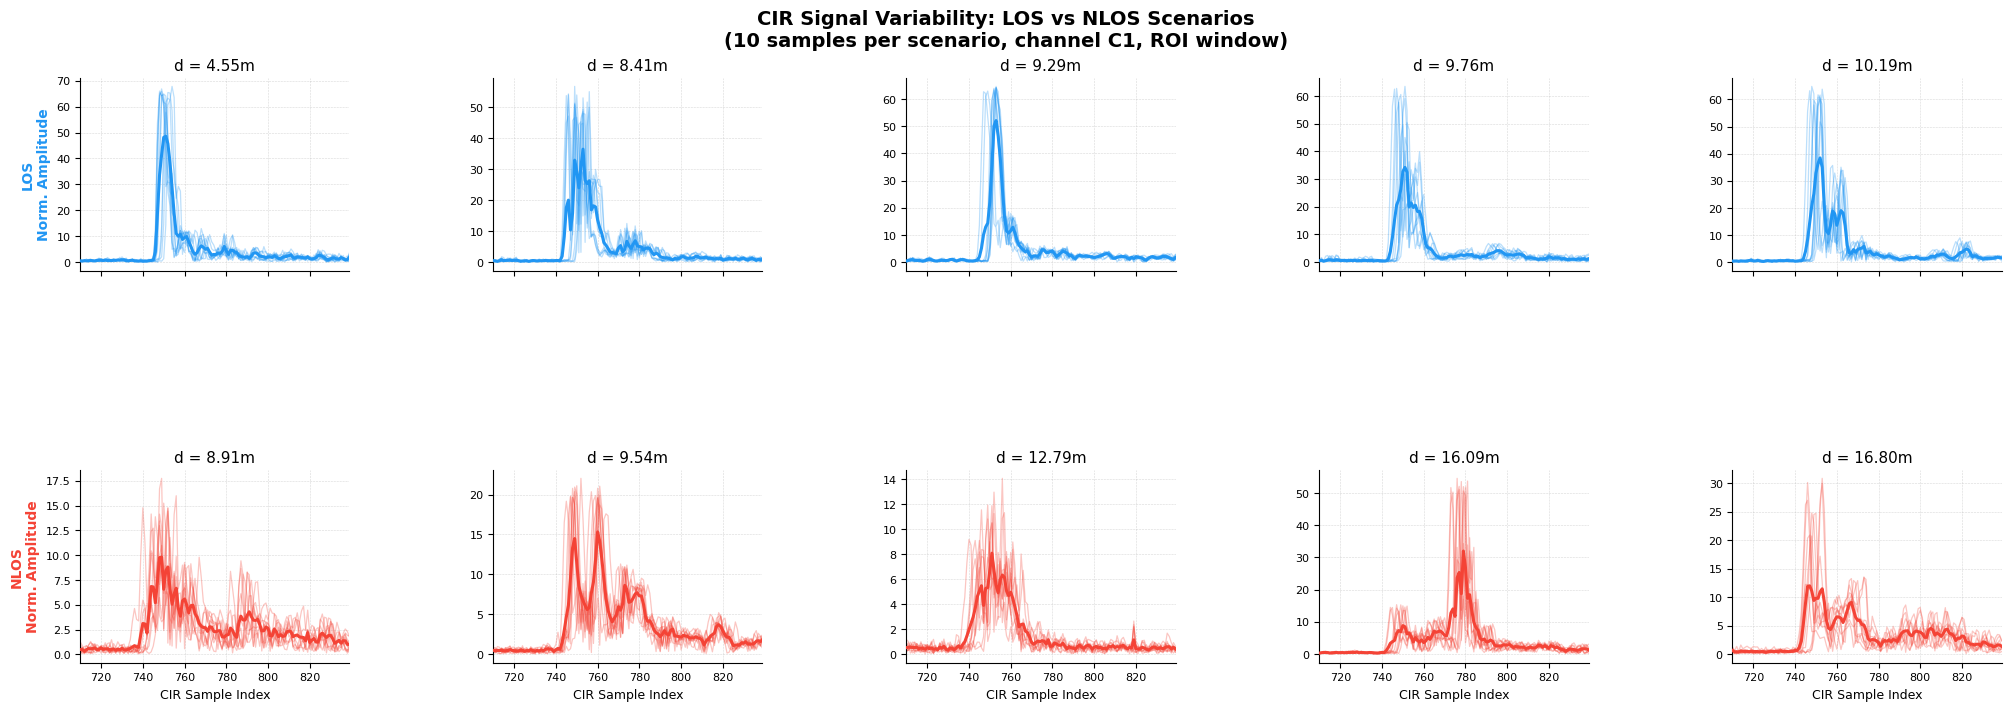

Saved to signal_variability_grid.png


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import glob

# Signal variability grid, 2 rows x 5 columns
# Top row: 5 LOS scenarios | Bottom row: 5 NLOS scenarios
# 10 overlapping samples per subplot (bold line = mean)

DATA_DIR   = 'dataset/channels'
ROI_START  = 710
ROI_END    = 840
N_SAMPLES  = 10
ALPHA      = 0.30

LOS_SCENARIOS  = ['4.55m', '8.41m', '9.29m', '9.76m', '10.19m']
NLOS_SCENARIOS = ['8.91m', '9.54m', '12.79m', '16.09m', '16.80m']

CIR_COLS = [f'CIR{i}' for i in range(1016)]
x_axis   = np.arange(ROI_START, ROI_END)

LOS_COLOR  = '#2196F3'
NLOS_COLOR = '#F44336'

def load_samples(scenario, kind, n=N_SAMPLES):
    files = glob.glob(f'{DATA_DIR}/{scenario}_{kind}_c1.csv')
    if not files:
        return []
    df   = pd.read_csv(files[0])
    rows = df.sample(n=min(n, len(df)), random_state=42)
    sigs = []
    for _, row in rows.iterrows():
        rxpacc = row.get('RXPACC', 1.0)
        sig    = row[CIR_COLS].values.astype(float)
        if rxpacc > 0:
            sig = sig / rxpacc
        sigs.append(sig[ROI_START:ROI_END])
    return sigs

fig, axes = plt.subplots(
    2, 5,
    figsize=(20, 7),
    sharex=True,
    gridspec_kw={'hspace': 0.50, 'wspace': 0.30}, constrained_layout=True
)

for row_idx, (scenarios, kind, color, row_label) in enumerate([
    (LOS_SCENARIOS,  'los',  LOS_COLOR,  'LOS'),
    (NLOS_SCENARIOS, 'nlos', NLOS_COLOR, 'NLOS'),
]):
    for col_idx, scenario in enumerate(scenarios):
        ax   = axes[row_idx, col_idx]
        sigs = load_samples(scenario, kind)

        for sig in sigs:
            ax.plot(x_axis, sig, color=color, alpha=ALPHA, linewidth=0.9)
        if sigs:
            ax.plot(x_axis, np.mean(sigs, axis=0), color=color,
                    linewidth=2.2, alpha=1.0, zorder=5)

        ax.set_title(f'd = {scenario}', fontsize=11, pad=5)
        ax.set_xlim(ROI_START, ROI_END - 1)
        ax.tick_params(labelsize=8)
        ax.grid(True, linestyle='--', linewidth=0.4, alpha=0.5)
        ax.spines[['top', 'right']].set_visible(False)

        if col_idx == 0:
            ax.set_ylabel(f'{row_label}\nNorm. Amplitude', fontsize=10,
                          fontweight='bold',
                          color=color)
        if row_idx == 1:
            ax.set_xlabel('CIR Sample Index', fontsize=9)

fig.suptitle(
    'CIR Signal Variability: LOS vs NLOS Scenarios\n'
    f'({N_SAMPLES} samples per scenario, channel C1, ROI window)',
    fontsize=14, fontweight='bold'
)

plt.savefig('signal_variability_grid.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to signal_variability_grid.png')


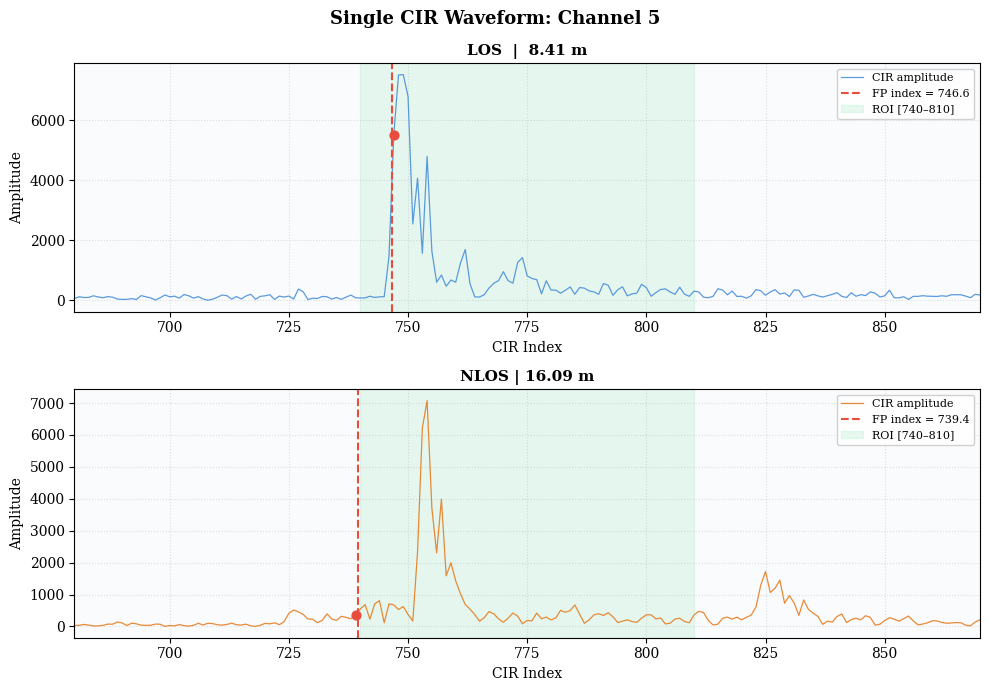

Saved: cir_single_waveform_los_nlos.png


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

CHANNEL_DIR = os.path.join("dataset", "channels")
SEARCH_START, SEARCH_END = 740, 810

df_los  = pd.read_csv(os.path.join(CHANNEL_DIR, "8.41m_los_c5.csv"))
df_nlos = pd.read_csv(os.path.join(CHANNEL_DIR, "16.09m_nlos_c5.csv"))

def get_cir(df, idx=0):
    cir_cols = sorted([c for c in df.columns if c.startswith("CIR")],
                      key=lambda x: int(x.replace("CIR", "")))
    return df.iloc[idx][cir_cols].values.astype(float)

cir_los  = get_cir(df_los,  idx=0)
cir_nlos = get_cir(df_nlos, idx=0)

fp_los  = float(df_los.iloc[0]["FP_INDEX"])  / 64.0
fp_nlos = float(df_nlos.iloc[0]["FP_INDEX"]) / 64.0

plt.rcParams.update({"font.family": "serif", "font.size": 10,
                     "axes.titlesize": 11, "axes.labelsize": 10})

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharey=False)
fig.suptitle("Single CIR Waveform: Channel 5", fontsize=13, fontweight="bold")

configs = [
    (axes[0], cir_los,  fp_los,  "LOS  |  8.41 m",  "#4A90D9"),
    (axes[1], cir_nlos, fp_nlos, "NLOS | 16.09 m", "#E67E22"),
]

for ax, cir, fp, title, color in configs:
    ax.set_facecolor("#FAFBFD")
    ax.plot(cir, color=color, linewidth=0.9, alpha=0.9, label="CIR amplitude")
    fp_int = int(round(fp))
    if 0 <= fp_int < len(cir):
        ax.axvline(fp, color="#E74C3C", linestyle="--", linewidth=1.5,
                   label=f"FP index = {fp:.1f}")
        ax.scatter([fp_int], [cir[fp_int]], color="#E74C3C", s=40, zorder=5)
    ax.axvspan(SEARCH_START, SEARCH_END, color="#2ECC71", alpha=0.10,
               label=f"ROI [{SEARCH_START}–{SEARCH_END}]")
    ax.set_xlim(680, 870)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("CIR Index")
    ax.set_ylabel("Amplitude")
    ax.legend(fontsize=8, framealpha=0.9)
    ax.grid(True, linestyle=":", alpha=0.4)

plt.tight_layout()
plt.savefig("cir_single_waveform_los_nlos.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: cir_single_waveform_los_nlos.png")
